## 1. IMPORTS AND ENVIRONMENT

In [1]:
# ═══════════════════════════════════════════════════════════════════════════
# 1. IMPORTS AND ENVIRONMENT
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT (orig cell 1): imports kept. Added: version capture, solver health check,
# explicit seed-derivation helper. `warnings.filterwarnings("ignore")` was global
# in the original and hid convergence warnings (GARCH, CVXPY); it is now scoped.
import gc
import hashlib
import itertools
import json
import logging
import os
import platform
import pickle
import sys
import time
import warnings
from dataclasses import dataclass, field
from datetime import datetime
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import cvxpy as cp
import dimod
import neal
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.cluster import AgglomerativeClustering
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA

try:
    import yfinance as yf
except ImportError:          # only needed when DATA_SOURCE == "yfinance"
    yf = None
try:
    import arch as _arch_pkg
    from arch import arch_model
except ImportError:
    _arch_pkg, arch_model = None, None

# Scoped warning policy: silence only known-noisy, non-diagnostic warnings.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*divide by zero.*")

ENV_INFO = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "cvxpy": cp.__version__, "dimod": dimod.__version__,
    "neal": getattr(neal, "__version__", "?"),
    "arch": getattr(_arch_pkg, "__version__", "NOT INSTALLED"),
    "yfinance": getattr(yf, "__version__", "NOT INSTALLED"),
    "cvxpy_installed_solvers": cp.installed_solvers(),
}
for k, v in ENV_INFO.items():
    print(f"  {k:<24}: {v}")

# ── Solver health check ─────────────────────────────────────────────────────
# AUDIT: the saved run of the ORIGINAL notebook failed on every QUBO/MPT call with
# "module 'cvxpy' has no attribute 'promote'" (broken cvxpy install). All failures
# were swallowed by try/except, so the grid silently produced no QUBO/MPT rows.
# We now fail fast if the exact expression used by the optimisers cannot be solved.
def _cvxpy_health_check():
    w = cp.Variable(3)
    S = np.eye(3) * 0.04
    m = np.array([0.1, 0.05, 0.02])
    p = cp.Problem(cp.Minimize(cp.quad_form(w, S) - 0.5 * m @ w),
                   [cp.sum(w) == 1, w >= 0, w <= 0.6])
    p.solve()
    assert p.status in ("optimal", "optimal_inaccurate"), p.status
    return True

assert _cvxpy_health_check(), "CVXPY is not functional — fix the environment before running."
assert arch_model is not None, "`arch` is required for the GARCH component (pip install arch)."
print("CVXPY health check: OK")

MIN_ANNUALISE_DAYS = 60
MIN_OOS_DAYS_FOR_TRUST = 120


def derive_seed(*keys) -> int:
    """Deterministic, collision-resistant seed derivation.

    AUDIT: the original re-used small integer seeds (0,1,2,...) across Neal,
    swap-SA and the stability analysis, so 'independent' runs shared streams
    (e.g. stability seed 0 == the main swap-SA run). All stochastic components
    now derive their seed from (base_seed, component_tag, index).
    """
    ints = []
    for k in keys:
        if isinstance(k, (int, np.integer)):
            ints.append(int(k) & 0xFFFFFFFF)
        else:
            ints.append(int(hashlib.md5(str(k).encode()).hexdigest()[:8], 16))
    return int(np.random.SeedSequence(ints).generate_state(1)[0])

  python                  : 3.12.9
  platform                : Windows-11-10.0.26200-SP0
  numpy                   : 2.4.3
  pandas                  : 3.0.1
  cvxpy                   : 1.8.2
  dimod                   : 0.12.21
  neal                    : 0.6.0
  arch                    : 8.0.0
  yfinance                : 1.2.0
  cvxpy_installed_solvers : ['CLARABEL', 'ECOS', 'ECOS_BB', 'HIGHS', 'OSQP', 'SCIP', 'SCIPY', 'SCS']
CVXPY health check: OK


## 2. CONFIGURATION  (single source of truth — every experiment reads from here)

Single source of truth for every parameter. `QUBO_MODE`, `GARCH_MODE`, `SWAP_TEMPERATURE`, `UNIVERSE_POINT_IN_TIME`, `BAND_KEEPS_DROPPED_ASSETS` and `REBALANCE_USE_DRIFT_GATE` switch each methodological change back to the original behaviour, so the corrected and legacy pipelines can be compared directly.

In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# 2. CONFIGURATION  (single source of truth — every experiment reads from here)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT (orig cells 3, 4): cell 3 was a dead string literal containing stale
# parameters (LAMBDA_ALPHAS, PLOTS_DIR). Cell 4 declared NUM_READS=1000,
# NUM_SWEEPS=3000, SA_SEEDS=5 but NO function ever read them: the grid actually
# ran with the hard-coded defaults of run_qubo_experiment (sa_seeds=3,
# num_reads=100, n_sweeps=1500) and a hard-coded warm swap-SA (50 x 1000).
# The values below reproduce what ACTUALLY ran. If the paper states 1000/3000/5,
# the paper (or these values) must change and all QUBO results must be rerun.

# ── Data ─────────────────────────────────────────────────────────────────────
DATA_SOURCE    = "yfinance"      # "yfinance" (research) | "synthetic" (smoke tests ONLY)
START_DATE     = "2022-01-01"
END_DATE       = "2026-01-01"
MARKETS        = ["india", "usa", "europe", "japan", "crypto"]

# ── Experiment grid (unchanged from original cell 4) ────────────────────────
UNIVERSE_SIZES = {"u10": 10, "u20": 20, "u30": 30, "u40": 40, "u50": 50}
CARDINALITIES  = [0.2, 0.3, 0.4]          # B = max(1, int(ratio * u_size))
Q_VALUES       = [0.3, 0.5, 0.7]
LOOKBACKS      = [126, 252, 504]
BACKTEST_DAYS  = 252                      # length of every evaluation window
DIV_PENALTY    = 0.3
INITIAL_CAPITAL = 1_600_000               # orig used 1.6M in most cells, 1.0M in others

# ── Temporal protocol (NEW — genuine holdout) ───────────────────────────────
# Data rows:  [ ... calibration (lookback) | VALIDATION (252) | HOLDOUT (252) ]
# Configuration selection uses ONLY the validation window; the holdout is
# evaluated once, for the configuration chosen on validation.
VALIDATION_DAYS = 252
HOLDOUT_DAYS    = 252
SELECTION_METRIC = "sharpe_ratio"

# ── SA parameters (values that the original grid ACTUALLY used) ─────────────
SA_NEAL_READS        = 100    # orig run_qubo_experiment default num_reads
SA_NEAL_SWEEPS       = 1500   # orig default n_sweeps
SA_NEAL_SEEDS        = 3      # orig default sa_seeds
SWAP_STAGES          = 50     # orig hard-coded num_reads of the swap-SA call
SWAP_MOVES_PER_STAGE = 1000   # orig hard-coded n_sweeps of the swap-SA call
# Orig re-optimisation (rebalancing) used num_reads=200 instead of 100 — an
# undocumented asymmetry. Unified here; set to 200 to reproduce the original.
REOPT_NEAL_READS     = SA_NEAL_READS
EXPERIMENT_SEED      = 0      # orig grid used seed=0 for QUBO and MPT
# orig stability defaults (run_stability was never called by the original notebook)
STABILITY_SEEDS, STABILITY_STAGES, STABILITY_MOVES = 5, 500, 3000

# ── Methodology switches ─────────────────────────────────────────────────────
# "legacy"    : reproduces the original pipeline (with bug fixes that do not
#               change the objective: exact-cardinality final answer, faster
#               incremental SA with an identical move sequence).
# "corrected" : decoupled Q = Q_ret + q_eff*Q_risk + lam*Q_card + delta*Q_div,
#               lam sized for feasibility dominance, GARCH scales q (risk
#               aversion) instead of lam. MAJOR METHODOLOGICAL CHANGE — see audit.
QUBO_MODE    = "corrected"          # "corrected" | "legacy"
GARCH_MODE   = "q_risk"             # "q_risk" | "legacy_lambda" | "off"
GARCH_LEGACY_CLIP = (1/3.0, 2.0)    # orig clip on static/conditional
GARCH_Q_CLIP      = (0.5, 3.0)      # = reciprocal of the legacy bounds (same clip events)
LAMBDA_SAFETY     = 1.5             # lam = LAMBDA_SAFETY * max marginal objective change
CORR_THRESHOLD    = 0.3             # |rho| above which the diversification penalty applies
SWAP_TEMPERATURE  = "swap"          # "swap" (lambda-invariant) | "legacy" (0.5*max|Q|)
UNIVERSE_POINT_IN_TIME = True       # True reproduces the original look-ahead universe
BAND_KEEPS_DROPPED_ASSETS = False   # True reproduces the original band filter
REBALANCE_USE_DRIFT_GATE  = False   # orig: calendar-only (`if True:`), threshold unused

if QUBO_MODE == "legacy":
    GARCH_MODE, SWAP_TEMPERATURE = "legacy_lambda", "legacy"

# ── Run switches (keep False for a fast top-to-bottom pass) ─────────────────
RUN_SMOKE_TESTS        = True
RUN_SINGLE_COMBINATION = False
RUN_FULL_GRID          = False   # validation grid + final-window grid (expensive)
RUN_REBALANCING_GRID   = True   # QUBO_RB for every config (very expensive)
RUN_STABILITY          = True
RUN_TIMING_BENCHMARK   = True
RUN_GARCH_DISTRIBUTION = True  # empirical distribution of GARCH scaling factors (P7)
RUN_LEGACY_ANALYSES    = True   # MC / Sharpe-CI / perf / VaR on selected configs

RESULTS_DIR = "results_audited"
PLOTS_DIR   = "plots_audited"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

CONFIG_SNAPSHOT = {k: v for k, v in dict(globals()).items()
                   if k.isupper() and isinstance(v, (int, float, str, bool, list, dict, tuple))}
print(json.dumps({k: CONFIG_SNAPSHOT[k] for k in
      ["DATA_SOURCE", "QUBO_MODE", "GARCH_MODE", "SWAP_TEMPERATURE", "UNIVERSE_POINT_IN_TIME",
       "SA_NEAL_READS", "SA_NEAL_SWEEPS", "SA_NEAL_SEEDS", "SWAP_STAGES", "SWAP_MOVES_PER_STAGE",
       "VALIDATION_DAYS", "HOLDOUT_DAYS"]}, indent=1))

{
 "DATA_SOURCE": "yfinance",
 "QUBO_MODE": "corrected",
 "GARCH_MODE": "q_risk",
 "SWAP_TEMPERATURE": "swap",
 "UNIVERSE_POINT_IN_TIME": true,
 "SA_NEAL_READS": 100,
 "SA_NEAL_SWEEPS": 1500,
 "SA_NEAL_SEEDS": 3,
 "SWAP_STAGES": 50,
 "SWAP_MOVES_PER_STAGE": 1000,
 "VALIDATION_DAYS": 252,
 "HOLDOUT_DAYS": 252
}


In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# 2b. MARKET CONSTANTS  (orig cells 5, 6, 7 — values unchanged)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT: orig cell 6 re-declared UNIVERSE_SIZES (duplicate, removed).
# MARKET_MAX_CORRELATION and MIN_DIVERSIFICATION_RATIO are declared but were
# NEVER used by any function: the paper must not claim these constraints.
# REBALANCE_DRIFT_THRESHOLD was never used (the drift gate was `if True:`).
# RISK_FREE_RATES are constants for the whole 2022-2026 sample (a simplification).
# NOTE: the ticker lists are today's large caps -> survivorship bias that cannot
# be removed without point-in-time index constituents (flag in the paper).
MARKET_TICKERS = {
    "india": [
        "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", "ICICIBANK.NS",
        "HINDUNILVR.NS", "ITC.NS", "SBIN.NS", "BHARTIARTL.NS", "LT.NS",
        "KOTAKBANK.NS", "AXISBANK.NS", "BAJFINANCE.NS", "ASIANPAINT.NS", "MARUTI.NS",
        "HCLTECH.NS", "SUNPHARMA.NS", "WIPRO.NS", "ULTRACEMCO.NS", "TITAN.NS",
        "TECHM.NS", "NESTLEIND.NS", "POWERGRID.NS", "NTPC.NS", "ONGC.NS",
        "JSWSTEEL.NS", "TATASTEEL.NS", "HINDALCO.NS", "COALINDIA.NS", "DIVISLAB.NS",
        "DRREDDY.NS", "CIPLA.NS", "ADANIENT.NS", "ADANIPORTS.NS", "BAJAJFINSV.NS",
        "BAJAJ-AUTO.NS", "HEROMOTOCO.NS", "EICHERMOT.NS", "TATACONSUM.NS", "BRITANNIA.NS",
        "GRASIM.NS", "INDUSINDBK.NS", "M&M.NS", "SBILIFE.NS", "HDFCLIFE.NS",
        "PIDILITIND.NS", "HAVELLS.NS", "SIEMENS.NS", "ABB.NS", "BERGEPAINT.NS",
    ],
    "usa": [
        "AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "BRK-B", "UNH", "JNJ",
        "JPM", "V", "PG", "XOM", "HD", "CVX", "MRK", "ABBV", "PEP", "KO",
        "LLY", "AVGO", "COST", "MCD", "CSCO", "TMO", "ACN", "ABT", "DHR", "NEE",
        "TXN", "WMT", "PM", "QCOM", "HON", "UPS", "AMGN", "IBM", "SBUX", "GE",
        "MMM", "CAT", "BA", "GS", "MS", "BLK", "SPGI", "AXP", "RTX", "LMT",
    ],
    "europe": [
        "ASML.AS", "NESN.SW", "NOVN.SW", "ROG.SW",
        "SAP.DE", "SIE.DE", "ALV.DE", "BAS.DE", "BAYN.DE",
        "AIR.PA", "BNP.PA", "MC.PA", "SAN.PA", "OR.PA",
        "SHELL.AS", "HEIA.AS", "PHIA.AS", "UNA.AS",
        "AZN.L", "HSBA.L", "ULVR.L", "GSK.L", "RIO.L",
        "ENI.MI", "ENEL.MI", "ISP.MI", "UCG.MI",
        "IBE.MC", "SAN.MC", "BBVA.MC", "ITX.MC", "REP.MC",
        "NOVO-B.CO", "DSV.CO", "ORSTED.CO", "NESTE.HE", "NOKIA.HE",
        "ERIC-B.ST", "VOLV-B.ST", "ATCO-A.ST", "ABB.ST", "SEB-A.ST",
        "LONN.SW", "GIVN.SW", "GEBN.SW", "CFR.SW", "SREN.SW",
        "ADYEN.AS", "MT.AS", "UCB.BR",
    ],
    "japan": [
        "7203.T", "6758.T", "9984.T", "6861.T", "8306.T",
        "7974.T", "4063.T", "6098.T", "9433.T", "8035.T",
        "6954.T", "2914.T", "4519.T", "7751.T", "6301.T",
        "5108.T", "8801.T", "9022.T", "3382.T", "4543.T",
        "7267.T", "6902.T", "4661.T", "8411.T", "8316.T",
        "6702.T", "4502.T", "7832.T", "6501.T", "6503.T",
        "2802.T", "8766.T", "6273.T", "4523.T", "7011.T",
        "8053.T", "2501.T", "5401.T", "3407.T", "4568.T",
        "9432.T", "8031.T", "7733.T", "6645.T", "7201.T",
        "4901.T", "8002.T", "6971.T", "1925.T", "9020.T",
    ],
    "crypto": [
        "BTC-USD", "ETH-USD", "BNB-USD", "SOL-USD", "XRP-USD",
        "ADA-USD", "AVAX-USD", "DOGE-USD", "DOT-USD", "LINK-USD",
        "LRC-USD", "LTC-USD", "BCH-USD", "ATOM-USD", "1INCH-USD",
        "XLM-USD", "ALGO-USD", "VET-USD", "ICP-USD", "FIL-USD",
        "AAVE-USD", "EOS-USD", "XTZ-USD", "SAND-USD", "MANA-USD",
        "THETA-USD", "AXS-USD", "EGLD-USD", "ARB-USD", "NEAR-USD",
        "CELO-USD", "ENJ-USD", "CHZ-USD", "BAT-USD", "ZIL-USD",
        "WAVES-USD", "ICX-USD", "ZEC-USD", "DASH-USD", "XEM-USD",
        "QTUM-USD", "ONT-USD", "ZRX-USD", "BAL-USD", "CRV-USD",
        "SUSHI-USD", "YFI-USD", "LDO-USD", "MKR-USD", "SNX-USD",
    ],
}

MARKET_BENCHMARKS = {
    "india":  "^NSEI",
    "usa":    "^GSPC",
    "europe": "^STOXX50E",
    "japan":  "^N225",
    "crypto": "BTC-USD",
}

RISK_FREE_RATES = {
    "india":  0.065,
    "usa":    0.0525,
    "europe": 0.035,
    "japan":  0.001,
    "crypto": 0.000,
}

MARKET_FR_WINDOW = {
    "india":  21,
    "usa":    14,
    "europe": 14,
    "japan":  21,
    "crypto": 7,
}

MARKET_REBALANCE_DAYS = {
    "india":  42,
    "usa":    42,
    "europe": 42,
    "japan":  42,
    "crypto": 21,
}

MARKET_TRANSACTION_COST = {
    "india":  0.006,
    "usa":    0.002,
    "europe": 0.003,
    "japan":  0.002,
    "crypto": 0.004,
}

MARKET_MAX_WEIGHT = {
    "india":  0.40,
    "usa":    0.35,
    "europe": 0.35,
    "japan":  0.40,
    "crypto": 0.25,
}

MARKET_MAX_VOL = {
    "india":  0.75,
    "usa":    0.60,
    "europe": 0.60,
    "japan":  0.70,
    "crypto": 5.00,
}

MARKET_MAX_CORRELATION = {
    "india":  0.65,
    "usa":    0.80,
    "europe": 0.80,
    "japan":  0.85,
    "crypto": 0.75,
}

MIN_DIVERSIFICATION_RATIO = {
    "india":  1.05,
    "usa":    1.10,
    "europe": 1.10,
    "japan":  1.05,
    "crypto": 1.15,
}

# (duplicate UNIVERSE_SIZES removed — defined once in the configuration cell)

BENCHMARK_LABELS = {
    "india":  "NIFTY 50",
    "usa":    "S&P 500",
    "europe": "EURO STOXX 50",
    "japan":  "Nikkei 225",
    "crypto": "BTC",
}

# ─────────────────────────────────────────────────────────────────────────────
# TAX & REBALANCING PARAMETERS
# ─────────────────────────────────────────────────────────────────────────────

# Capital-gains tax rates (short-term / long-term threshold in days + rates)
# Short-term = held < threshold days;  Long-term = held >= threshold
MARKET_TAX = {
    "india": {
        "stcg_rate":    0.20,   # STCG on equity (post-Jul 2024 budget)
        "ltcg_rate":    0.125,  # LTCG >₹1.25 L exemption (flat 12.5%)
        "lt_threshold": 365,    # 12 months for equity in India
        "stt_rate":     0.001,  # Securities Transaction Tax on sell side
        "ltcg_exempt":  125000, # INR exemption per FY
    },
    "usa": {
        "stcg_rate":    0.37,   # Ordinary income top rate (simplified)
        "ltcg_rate":    0.20,   # Long-term capital gains (top bracket)
        "lt_threshold": 366,    # > 1 year
        "stt_rate":     0.0,
        "ltcg_exempt":  0,
    },
    "europe": {
        "stcg_rate":    0.26,   # Representative (Germany Abgeltungsteuer)
        "ltcg_rate":    0.26,   # Same flat rate in most EU jurisdictions
        "lt_threshold": 366,
        "stt_rate":     0.0,
        "ltcg_exempt":  0,
    },
    "japan": {
        "stcg_rate":    0.2031, # 20% flat + 0.315%復興 levy
        "ltcg_rate":    0.2031,
        "lt_threshold": 366,
        "stt_rate":     0.0,
        "ltcg_exempt":  0,
    },
    "crypto": {
        "stcg_rate":    0.30,   # India VDA flat 30% (no deductions)
        "ltcg_rate":    0.30,
        "lt_threshold": 1,      # No LT benefit for crypto in India
        "stt_rate":     0.0,
        "ltcg_exempt":  0,
    },
}

# Rebalancing schedule: how many trading days between portfolio reviews
# Already defined in MARKET_REBALANCE_DAYS above but adding a semantic alias
# You can override individual markets here:
# MARKET_REBALANCE_DAYS["india"] = 63  # ~3 months
# MARKET_REBALANCE_DAYS["crypto"] = 21  # ~1 month

# Drift threshold: only rebalance if portfolio has drifted more than X% from target
REBALANCE_DRIFT_THRESHOLD = {
    "india":  0.05,   # 5% drift triggers rebalance
    "usa":    0.05,
    "europe": 0.05,
    "japan":  0.05,
    "crypto": 0.08,   # crypto allowed more drift before rebalancing
}

print("Tax and rebalancing parameters loaded")


# ── NEW: annualisation frequency ────────────────────────────────────────────
# AUDIT: crypto rows are calendar days (~365/yr) but the original annualised
# everything with 252. Mean/covariance scale identically, so selections and
# weights are unchanged; REPORTED annualised vol/return/Sharpe for crypto were
# understated by sqrt(365/252) ~ 1.20 (Sharpe) and misstated for returns.
PERIODS_PER_YEAR = {"india": 252, "usa": 252, "europe": 252, "japan": 252,
                    "crypto": 365, "combined": 252}

def ppy(market):
    return PERIODS_PER_YEAR.get(market, 252)

# ── NEW: pooled pseudo-market used ONLY by the timing benchmark ─────────────
# Mixed currencies make its returns economically meaningless; it exists only to
# time the optimisers on large universes. Max-vol is relaxed so crypto survives.
for _d, _v in [(RISK_FREE_RATES, 0.0), (MARKET_FR_WINDOW, 21), (MARKET_REBALANCE_DAYS, 42),
               (MARKET_TRANSACTION_COST, 0.002), (MARKET_MAX_WEIGHT, 0.35),
               (MARKET_MAX_VOL, 5.0), (BENCHMARK_LABELS, "none")]:
    _d.setdefault("combined", _v)
MARKET_TAX.setdefault("combined", dict(MARKET_TAX["usa"]))

Tax and rebalancing parameters loaded


{'stcg_rate': 0.37,
 'ltcg_rate': 0.2,
 'lt_threshold': 366,
 'stt_rate': 0.0,
 'ltcg_exempt': 0}

In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# LOGGER (orig cell 9 — unchanged apart from path handling)
# ═══════════════════════════════════════════════════════════════════════════
log_dir = "logs"
os.makedirs(log_dir, exist_ok=True)
logger = logging.getLogger('qubo_optimization')
logger.setLevel(logging.DEBUG)
for handler in logger.handlers[:]:
    handler.close(); logger.removeHandler(handler)
logger.propagate = False
log_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
log_file = os.path.join(log_dir, f"qubo_optimization_{log_timestamp}.log")
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.WARNING)      # orig INFO flooded the notebook
console_handler.setFormatter(logging.Formatter('%(asctime)s - %(levelname)s - %(message)s', datefmt='%H:%M:%S'))
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_handler.setFormatter(logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s'))
logger.addHandler(console_handler); logger.addHandler(file_handler)
logger.info(f"Logging initialised ({log_file})")
print("log file:", log_file)

log file: logs\qubo_optimization_20260930_005515.log


## 3. DATA LOADING  (orig cells 12, 13)

In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# 3. DATA LOADING  (orig cells 12, 13)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT fixes:
#  * cache key now includes the ticker list (orig key = market+dates only, so an
#    edited ticker list silently re-used a stale cache);
#  * `prices.dropna()` over ALL tickers means a single late-listed ticker kept by
#    the 80% column threshold deletes the early rows of EVERY ticker (visible in
#    crypto: 1126 rows vs 1461 benchmark days). The behaviour is kept (changing it
#    changes every result) but the number of rows lost is now reported;
#  * a content fingerprint of the loaded data is recorded, because yfinance
#    back-adjusts prices, so "same dates" does not imply "same data".
#  * DATA_SOURCE="synthetic" provides a clearly-labelled generator for smoke tests.

def _ticker_hash(tickers):
    return hashlib.md5(",".join(sorted(tickers)).encode()).hexdigest()[:10]


def data_fingerprint(df: pd.DataFrame) -> str:
    h = hashlib.sha256()
    h.update(",".join(map(str, df.columns)).encode())
    h.update(np.ascontiguousarray(df.index.values.astype("datetime64[ns]").astype("int64")).tobytes())
    h.update(np.ascontiguousarray(np.round(df.values.astype(float), 8)).tobytes())
    return h.hexdigest()[:16]


DATA_DIAGNOSTICS = {}


def download_data(market, start_date, end_date, cache_dir="data_cache"):
    if market not in MARKET_TICKERS:
        raise ValueError(f"Unknown market: '{market}'. Valid: {list(MARKET_TICKERS)}")
    if yf is None:
        raise ImportError("yfinance not installed")
    os.makedirs(cache_dir, exist_ok=True)
    tickers = MARKET_TICKERS[market]
    key = hashlib.md5(f"{market}_{start_date}_{end_date}_{_ticker_hash(tickers)}".encode()).hexdigest()
    prices_cache = os.path.join(cache_dir, f"{market}_{key}_prices.csv")
    volume_cache = os.path.join(cache_dir, f"{market}_{key}_volume.csv")
    if os.path.exists(prices_cache) and os.path.exists(volume_cache):
        prices = pd.read_csv(prices_cache, index_col=0, parse_dates=True)
        volume = pd.read_csv(volume_cache, index_col=0, parse_dates=True)
        print(f"  [CACHE] {market}: {prices.shape[0]} rows x {prices.shape[1]} tickers")
        return prices, volume

    raw = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"No data returned for market: {market}")
    prices = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw[["Close"]]
    volume = raw["Volume"] if isinstance(raw.columns, pd.MultiIndex) else raw[["Volume"]]
    common = prices.columns.intersection(volume.columns)
    prices, volume = prices[common], volume[common]
    rows_raw = len(prices)
    original = set(prices.columns)
    prices = prices.dropna(axis=1, thresh=int(0.8 * len(prices)))
    volume = volume[prices.columns]
    prices = prices.dropna()
    volume = volume.loc[prices.index].fillna(0.0)
    dropped = sorted(original - set(prices.columns))
    DATA_DIAGNOSTICS[market] = {"rows_raw": rows_raw, "rows_kept": len(prices),
                                "rows_lost_to_row_dropna": rows_raw - len(prices),
                                "tickers_dropped": dropped}
    print(f"  [OK] {market}: {prices.shape[1]} tickers x {len(prices)} days "
          f"(rows lost to dropna: {rows_raw - len(prices)}, tickers dropped: {len(dropped)})")
    prices.to_csv(prices_cache); volume.to_csv(volume_cache)
    return prices, volume


def download_benchmark_data(market, start_date, end_date, cache_dir="data_cache"):
    if yf is None:
        raise ImportError("yfinance not installed")
    os.makedirs(cache_dir, exist_ok=True)
    ticker = MARKET_BENCHMARKS[market]
    key = hashlib.md5(f"bench_{market}_{ticker}_{start_date}_{end_date}".encode()).hexdigest()
    cache_path = os.path.join(cache_dir, f"bench_{market}_{key}.csv")
    if os.path.exists(cache_path):
        df = pd.read_csv(cache_path, index_col=0, parse_dates=True)
        return df.iloc[:, 0]
    raw = yf.download(ticker, start=start_date, end=end_date, auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"No benchmark data for {market} ({ticker})")
    close = raw["Close"]
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]
    close = close.dropna(); close.name = ticker
    close.to_csv(cache_path)
    return close


def make_synthetic_market(market, n_assets=50, n_days=1000, seed=0):
    """SMOKE-TEST DATA ONLY. Factor model + GARCH-like vol clustering.
    Results computed on this data are NOT research results."""
    rng = np.random.default_rng(derive_seed(seed, "synthetic", market))
    freq = "D" if market == "crypto" else "B"
    idx = pd.date_range("2022-01-03", periods=n_days, freq=freq)
    k = 3
    betas = rng.normal(0.8, 0.4, size=(n_assets, k))
    h = np.full(k, 1e-4); f = np.zeros((n_days, k))
    for t in range(n_days):
        h = 2e-6 + 0.08 * (f[t - 1] ** 2 if t else h) + 0.9 * h
        f[t] = rng.normal(0, np.sqrt(h))
    idio = rng.normal(0, rng.uniform(0.006, 0.02, n_assets), size=(n_days, n_assets))
    drift = rng.normal(0.0003, 0.0004, n_assets)
    rets = drift + f @ betas.T + idio
    scale = 3.0 if market == "crypto" else 1.0
    prices = pd.DataFrame(100 * np.exp(np.cumsum(rets * scale, axis=0)), index=idx,
                          columns=[f"{market[:3].upper()}{i:02d}" for i in range(n_assets)])
    volume = pd.DataFrame(rng.lognormal(12, 1, size=(n_days, n_assets)), index=idx,
                          columns=prices.columns)
    bench = pd.Series(100 * np.exp(np.cumsum((f @ betas.mean(0)) * scale + 0.0002)), index=idx,
                      name=f"{market}_bench")
    return prices, volume, bench


def load_all_markets(markets):
    price_data, volume_data, bench_data = {}, {}, {}
    for m in markets:
        try:
            if DATA_SOURCE == "synthetic":
                price_data[m], volume_data[m], bench_data[m] = make_synthetic_market(m)
            else:
                price_data[m], volume_data[m] = download_data(m, START_DATE, END_DATE)
                bench_data[m] = download_benchmark_data(m, START_DATE, END_DATE)
        except Exception as e:                               # visible, not silent
            logger.error(f"[FAIL] data for {m}: {e}", exc_info=True)
            print(f"[ERROR] {m}: {e}")
    return price_data, volume_data, bench_data


price_data, volume_data, bench_data = load_all_markets(MARKETS)
DATA_FINGERPRINTS = {m: data_fingerprint(p) for m, p in price_data.items()}
if DATA_SOURCE != "yfinance":
    print("\n" + "!" * 78 + "\n!! SYNTHETIC DATA — every number below is a smoke test, NOT a research result.\n" + "!" * 78)
print("fingerprints:", DATA_FINGERPRINTS)

  [CACHE] india: 988 rows x 50 tickers
  [CACHE] usa: 1003 rows x 50 tickers
  [CACHE] europe: 958 rows x 49 tickers
  [CACHE] japan: 978 rows x 50 tickers
  [CACHE] crypto: 1461 rows x 50 tickers
fingerprints: {'india': '7636a1b0cf2bbf93', 'usa': 'a467fafbec725543', 'europe': 'caac1868192ad112', 'japan': '6634965c3a09c4b7', 'crypto': '524a288ed4034c48'}


## 4. DATA VALIDATION  (NEW — the original had none)

In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# 4. DATA VALIDATION  (NEW — the original had none)
# ═══════════════════════════════════════════════════════════════════════════
def validate_market_data(market, prices, volume):
    issues = []
    if not prices.index.is_monotonic_increasing: issues.append("index not sorted")
    if prices.index.has_duplicates:              issues.append("duplicate dates")
    if prices.isna().any().any():                issues.append("NaN prices")
    if (prices <= 0).any().any():                issues.append("non-positive prices")
    if not prices.index.equals(volume.index):    issues.append("price/volume index mismatch")
    if list(prices.columns) != list(volume.columns): issues.append("price/volume column mismatch")
    N = len(prices)
    feas = {}
    for lb in LOOKBACKS:
        feas[lb] = {
            "final_window": lb + BACKTEST_DAYS <= N,
            "validation+holdout": lb + VALIDATION_DAYS + HOLDOUT_DAYS <= N,
        }
    return {"market": market, "rows": N, "tickers": prices.shape[1],
            "start": prices.index[0].date(), "end": prices.index[-1].date(),
            "issues": issues, "feasibility": feas}

DATA_VALIDATION = {m: validate_market_data(m, price_data[m], volume_data[m]) for m in price_data}
for m, v in DATA_VALIDATION.items():
    infeasible = [lb for lb, f in v["feasibility"].items() if not f["validation+holdout"]]
    print(f"{m:<8} rows={v['rows']:<5} tickers={v['tickers']:<3} {v['start']}→{v['end']} "
          f"issues={v['issues'] or 'none'} | lookbacks infeasible for val+holdout: {infeasible or 'none'}")
    assert not v["issues"], f"data issues for {m}: {v['issues']}"
# With ~950-990 equity rows, lookback=504 needs 504+252+252=1008 rows: the
# holdout protocol CANNOT evaluate lb=504. These configs are reported as
# infeasible for selection instead of being silently shortened.

india    rows=988   tickers=50  2022-01-03→2025-12-31 issues=none | lookbacks infeasible for val+holdout: [504]
usa      rows=1003  tickers=50  2022-01-03→2025-12-31 issues=none | lookbacks infeasible for val+holdout: [504]
europe   rows=958   tickers=49  2022-01-04→2025-12-30 issues=none | lookbacks infeasible for val+holdout: [504]
japan    rows=978   tickers=50  2022-01-04→2025-12-30 issues=none | lookbacks infeasible for val+holdout: [504]
crypto   rows=1461  tickers=50  2022-01-01→2025-12-31 issues=none | lookbacks infeasible for val+holdout: none


## 5. UNIVERSE CONSTRUCTION  (orig cells 15, 16, 17)

**Critical fix.** The original built the universe from the full sample, including the test window. Every filter here uses only rows strictly before the first test row.

In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# 5. UNIVERSE CONSTRUCTION  (orig cells 15, 16, 17)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT — CRITICAL look-ahead in the original:
#   build_universe(prices_all, ...) ran on the FULL sample. _filter_volatility and
#   _cluster_select used prices.iloc[-lookback:], i.e. the LAST `lookback` rows of
#   the whole dataset. With backtest_days=252 those rows ARE the test window
#   (for lookback=252 exactly; for 504 half of it; for 126 only test data).
#   Liquidity and ADTV were also computed over the full sample incl. the test.
#   The universe (and hence every QUBO/MPT/EW result) was chosen with knowledge
#   of test-period volatility, correlations and turnover.
# FIX: every filter now uses only rows strictly before `cutoff` (the first test
#   row). `UNIVERSE_POINT_IN_TIME=False` reproduces the original behaviour.
# AUDIT — investigate_lookahead (orig cell 43) reported "CLEAN, overlap 100%"
#   only because it was run with ref_size=50 on pools of <=50 tickers, where every
#   ticker passes regardless of the data window. The check was vacuous.
# NOTE: with pool_multiplier=2 and clustering to exactly `size`, the pool already
#   has `size` assets, so sample_from_universe() is a no-op: the "seed" never
#   changes the universe. Kept (documented) — universe randomisation is NOT part
#   of the experimental design as implemented.

def _filter_liquidity(prices, volume, min_pct=0.95):
    mask = (volume > 0).sum() >= min_pct * len(prices)
    return prices.loc[:, mask], volume.loc[:, mask]

def _filter_adtv(prices, volume, size):
    adtv = (prices * volume).mean()
    top = adtv.nlargest(min(size, len(adtv))).index
    return prices[top], volume[top]

def _filter_volatility(prices, volume, lookback, max_vol, periods=252):
    rets = prices.iloc[-lookback:].pct_change().dropna()
    ann_vol = rets.std() * np.sqrt(periods)
    mask = (ann_vol <= max_vol) & (rets.std() > 1e-10)   # also drops zero-variance assets
    return prices.loc[:, mask], volume.loc[:, mask]

def _cluster_select(prices, volume, lookback, n_clusters):
    if prices.shape[1] <= n_clusters:
        return prices, volume
    returns = prices.iloc[-lookback:].pct_change().dropna()
    dist = np.clip(1 - np.abs(returns.corr().values), 0, 1)
    np.fill_diagonal(dist, 0)
    labels = AgglomerativeClustering(n_clusters=n_clusters, metric="precomputed",
                                     linkage="average").fit_predict(dist)
    adtv = (prices * volume).mean()
    chosen = [adtv[prices.columns[labels == c]].idxmax() for c in range(n_clusters)]
    return prices[chosen], volume[chosen]


def build_universe(prices, volume, size, lookback, market, pool_multiplier=2, cutoff=None):
    """Return prices (ALL rows) for the selected columns.
    cutoff: integer row position of the first evaluation row; filters see only
    rows [:cutoff]. cutoff=None -> original full-sample (look-ahead) behaviour."""
    if prices.empty:
        raise ValueError("prices empty")
    if cutoff is None or not UNIVERSE_POINT_IN_TIME:
        p_hist, v_hist = prices, volume
    else:
        p_hist, v_hist = prices.iloc[:cutoff], volume.iloc[:cutoff]
    if len(p_hist) < lookback + 1:
        raise ValueError(f"not enough pre-cutoff history ({len(p_hist)}) for lookback {lookback}")
    max_vol = MARKET_MAX_VOL.get(market, 1.0)
    p, v = _filter_liquidity(p_hist, v_hist)
    p, v = _filter_adtv(p, v, size * pool_multiplier)
    # 252 kept deliberately: MARKET_MAX_VOL thresholds were calibrated with 252.
    p, v = _filter_volatility(p, v, lookback, max_vol, periods=252)
    p, v = _cluster_select(p, v, lookback, n_clusters=size)
    if p.shape[1] == 0:
        raise ValueError(f"No assets survived for {market}")
    return prices.loc[:, list(p.columns)]


def sample_from_universe(prices, size, seed):
    if prices.shape[1] <= size:
        return prices
    rng = np.random.RandomState(seed)
    chosen = rng.choice(prices.columns.tolist(), size=size, replace=False)
    return prices[chosen.tolist()]

print("Universe functions loaded (point-in-time =", UNIVERSE_POINT_IN_TIME, ")")

Universe functions loaded (point-in-time = True )


## 6. RETURN / COVARIANCE ESTIMATION  (orig cells 19, 20, 21)

In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# 6. RETURN / COVARIANCE ESTIMATION  (orig cells 19, 20, 21)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT:
#  * _forbes_rigobon_corr: O(N^2) Python double loop -> vectorised (bit-identical
#    up to fp; regression-tested below). Methodological note: the base matrix is
#    the HIGH-volatility-regime sample correlation, "corrected" by FR; LW is only
#    used for the vols. This should be described exactly in the paper.
#  * compute_expected_returns is called "James-Stein" but uses an ad-hoc
#    intensity kappa=min(1, n/T) toward the grand mean; it is NOT the JS
#    estimator. Estimator kept; paper wording must change ("shrinkage toward the
#    cross-sectional mean with intensity N/T").
#  * mu was computed from prices.loc[returns.index[0]:] -> T-1 returns while cov
#    used T returns. Now both use the same T returns (tiny numerical change).
#  * zero-variance columns were dropped from cov but NOT from mu (length
#    mismatch -> wrong asset mapping). Now filtered upstream; asserted here.
#  * annualisation uses ppy(market) (crypto = 365, see constants cell).

def _forbes_rigobon_corr(returns, roll_window):
    """Forbes-Rigobon correction for heteroskedasticity-induced correlation bias."""
    N = returns.shape[1]
    roll_vol = returns.rolling(roll_window).std().mean(axis=1).dropna()
    threshold = roll_vol.quantile(0.5)
    aligned_idx = returns.index.intersection(roll_vol.index)
    high_mask = roll_vol.reindex(aligned_idx) >= threshold
    R_aligned = returns.reindex(aligned_idx).values
    R_H = R_aligned[high_mask.values]
    R_L = R_aligned[~high_mask.values]
    if len(R_H) < N + 5 or len(R_L) < N + 5:
        lw = LedoitWolf().fit(returns)
        std = np.sqrt(np.diag(lw.covariance_))
        std = np.where(std < 1e-12, 1.0, std)
        return lw.covariance_ / np.outer(std, std), "LW-fallback"
    corr_H = np.corrcoef(R_H, rowvar=False)
    _, _, Vt = np.linalg.svd(R_aligned - R_aligned.mean(0), full_matrices=False)
    pc1 = R_aligned @ Vt[0]
    var_H = np.var(pc1[high_mask.values], ddof=1)
    var_L = np.var(pc1[~high_mask.values], ddof=1)
    if var_L < 1e-12:
        return corr_H, "LW-fallback"
    delta = max((var_H - var_L) / var_L, 0.0)
    corr_fr = corr_H / np.sqrt(1.0 + delta * (1.0 - corr_H ** 2))   # vectorised
    np.fill_diagonal(corr_fr, 1.0)
    eigvals, eigvecs = np.linalg.eigh(corr_fr)
    corr_fr = eigvecs @ np.diag(np.maximum(eigvals, 0.0)) @ eigvecs.T
    d = np.sqrt(np.diag(corr_fr))
    d = np.where(d < 1e-12, 1.0, d)
    corr_fr = corr_fr / np.outer(d, d)
    np.fill_diagonal(corr_fr, 1.0)
    return corr_fr, f"FR delta={delta:.3f}"


def compute_expected_returns_from_returns(returns: pd.DataFrame, periods: int = 252) -> np.ndarray:
    """Shrinkage of annualised sample means toward their cross-sectional mean,
    intensity kappa = min(1, N/T). (Not the James-Stein estimator.)"""
    mu_sample = returns.mean().values * periods
    n, T = len(mu_sample), len(returns)
    kappa = min(1.0, n / T)
    return (1.0 - kappa) * mu_sample + kappa * mu_sample.mean()


def compute_expected_returns(prices: pd.DataFrame, lookback: int, periods: int = 252) -> np.ndarray:
    """Backward-compatible wrapper (orig signature)."""
    return compute_expected_returns_from_returns(prices.pct_change().dropna(), periods)


def compute_statistics(prices: pd.DataFrame, market: str = "usa", use_shrinkage: bool = True):
    """Returns (mu, cov, returns); annualised with ppy(market)."""
    P = ppy(market)
    returns = prices.pct_change().dropna()
    if (returns.std() < 1e-10).any():
        raise ValueError(f"zero-variance assets in estimation window: "
                         f"{list(returns.columns[returns.std() < 1e-10])}")
    T, N = returns.shape
    if T / N < 5:
        K_cap = max(min(T // 10, N // 2, 10), 2)
        pca_full = PCA(n_components=K_cap).fit(returns.values)
        K = int(np.searchsorted(np.cumsum(pca_full.explained_variance_ratio_), 0.80)) + 1
        K = max(min(K, K_cap), 2)
        pca_k = PCA(n_components=K)
        factors = pca_k.fit_transform(returns.values)
        B_mat = pca_k.components_.T
        factor_cov = np.cov(factors.T) * P
        residuals = returns.values - factors @ B_mat.T
        idio_var = np.var(residuals, axis=0) * P
        cov = B_mat @ factor_cov @ B_mat.T + np.diag(idio_var)
        cov_tag = f"PCA-K{K}"
    else:
        lw = LedoitWolf().fit(returns)
        std_lw = np.sqrt(np.diag(lw.covariance_ * P))
        corr, fr_tag = _forbes_rigobon_corr(returns, MARKET_FR_WINDOW.get(market, 21))
        cov = np.outer(std_lw, std_lw) * corr
        cov_tag = f"LW+{fr_tag}"
    mu = (compute_expected_returns_from_returns(returns, P) if use_shrinkage
          else returns.mean().values * P)
    assert mu.shape[0] == cov.shape[0] == returns.shape[1] == prices.shape[1]
    logger.debug(f"compute_statistics {market}: T={T} N={N} cov={cov_tag}")
    return mu, cov, returns

print("Statistics functions loaded")

Statistics functions loaded


## 7. GARCH CALCULATIONS  (orig cell 27, split into fit / scaling)

In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# 7. GARCH CALCULATIONS  (orig cell 27, split into fit / scaling)
# ═══════════════════════════════════════════════════════════════════════════
# UNIT AUDIT of the original ratio   vol_ratio = static_vol / cond_vol_mean
#   numerator   static_vol = mean_i sqrt(Sigma_ii / 252)
#               Sigma annualised (decimal^2/yr)  ->  sqrt(Sigma_ii/252) = DAILY decimal vol
#   denominator cond_vol_mean = mean_i sqrt(h_{i,T+1}) / 100
#               GARCH fitted on 100*r (percent)  ->  sqrt(h)/100 = DAILY decimal vol
#               fallback np.std(r_i) = DAILY decimal vol
#   => dimensionless; units ARE consistent (for crypto only if Sigma and the /252
#      use the same frequency — now both use ppy(market)).
#   Economic caveats: (i) Sigma_ii is Ledoit-Wolf-shrunk (toward the average
#   variance) or PCA-reconstructed, so the "static" vol is an estimator-specific
#   quantity, not the sample vol the GARCH model is compared with; (ii) the ratio
#   averages VOLATILITIES across assets, not a portfolio vol; (iii) DIRECTION:
#   when current conditional vol is HIGH the ratio is < 1, which LOWERED lambda
#   and therefore (see QUBO audit) WEAKENED the diversification penalty in
#   turbulent regimes — the opposite of the usual risk-management intuition.
#   Observed in the original logs (15 values): 0.733 … 1.193; none hit the
#   [1/3, 2] clip, so the clip was not doing the work — but the effect size is
#   only about ±25% on lambda. Compute the full distribution with
#   garch_scaling_distribution() on real data (section 19).
# EFFICIENCY: the same (tickers, window) GARCH fits were recomputed for every
#   (B, q) config and for diagnostics. Fits are now cached (exact).

_GARCH_CACHE: Dict[tuple, dict] = {}


def fit_garch_conditional_vols(returns: pd.DataFrame) -> dict:
    """Per-asset GARCH(1,1) one-step-ahead DAILY conditional vol (decimal)."""
    key = (tuple(returns.columns), returns.index[0], returns.index[-1], len(returns))
    if key in _GARCH_CACHE:
        return _GARCH_CACHE[key]
    vols, status = [], []
    arr = returns.values
    for i in range(arr.shape[1]):
        r = arr[:, i] * 100.0
        try:
            res = arch_model(r, vol="Garch", p=1, q=1, dist="normal", rescale=False).fit(
                disp="off", show_warning=False)
            fc = res.forecast(horizon=1, reindex=False)
            v = float(np.sqrt(fc.variance.values[-1, 0])) / 100.0
            ok = (res.convergence_flag == 0) and np.isfinite(v) and v > 0
            vols.append(v if ok else float(np.std(arr[:, i])))
            status.append("ok" if ok else "nonconverged->sample_std")
        except Exception as e:
            vols.append(float(np.std(arr[:, i])))
            status.append(f"error->sample_std")
    out = {"cond_vols": np.array(vols), "status": status,
           "n_fallback": int(sum(s != "ok" for s in status))}
    _GARCH_CACHE[key] = out
    return out


def garch_scaling(cov: np.ndarray, returns: pd.DataFrame, market: str) -> dict:
    """Both the legacy lambda ratio and the corrected q multiplier, with diagnostics."""
    g = fit_garch_conditional_vols(returns)
    cond_vol_mean = float(np.mean(g["cond_vols"]))                 # daily decimal
    static_vol = float(np.mean(np.sqrt(np.diag(cov) / ppy(market))))  # daily decimal
    legacy_raw = static_vol / (cond_vol_mean + 1e-10)
    legacy = float(np.clip(legacy_raw, *GARCH_LEGACY_CLIP))
    q_raw = cond_vol_mean / (static_vol + 1e-10)                   # >1 in turbulent regimes
    q_mult = float(np.clip(q_raw, *GARCH_Q_CLIP))
    return {"static_vol_daily": static_vol, "cond_vol_daily": cond_vol_mean,
            "legacy_ratio_raw": legacy_raw, "legacy_ratio": legacy,
            "legacy_clipped": bool(legacy != legacy_raw),
            "q_mult_raw": q_raw, "q_mult": q_mult, "q_mult_clipped": bool(q_mult != q_raw),
            "garch_n_fallback": g["n_fallback"]}

print("GARCH functions loaded; arch", ENV_INFO["arch"])

GARCH functions loaded; arch 8.0.0


## 8. QUBO CONSTRUCTION  (orig cells 26, 28, 29)

Explicit decomposition `Q = Q_ret + q_eff·Q_risk + λ·Q_card + δ·Q_div`, with the proofs that motivate the corrected λ and the GARCH→q move recorded in the cell header.

In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# 8. QUBO CONSTRUCTION  (orig cells 26, 28, 29)
# ═══════════════════════════════════════════════════════════════════════════
# Energy convention everywhere: E(x) = x^T U x with U upper-triangular
#   (diag = linear terms, U_ij (i<j) = pair terms). Constant lam*B^2 omitted.
#
# Decomposition (derived from the original build_qubo):
#   mu_n = mu / max|mu|,  C = Sigma / max|Sigma|  (separate scales!)
#   Q_ret : diag  -mu_n
#   Q_risk: diag  C_ii,    upper 2*C_ij           ( = x^T C x )
#   Q_card: diag  (1-2B),  upper 2                ( = (sum x - B)^2 - B^2 )
#   Q_div : upper 2*(|rho_ij| - 0.3)_+
#   ORIGINAL:  Q = Q_ret + q*Q_risk + lam*Q_card + (div_penalty*lam)*Q_div
#   CORRECTED: Q = Q_ret + q_eff*Q_risk + lam*Q_card + (div_penalty*s_obj)*Q_div
#
# KEY FINDINGS (proved + tested in section 10):
#  (1) On the feasible set sum(x)=B, x^T Q_card x = -B^2 is CONSTANT. Any swap
#      move's energy change is independent of lam. The final answer always came
#      from a cardinality-preserving swap-SA (or was projected onto sum=B), so
#      lam could influence the selected assets ONLY via
#        (a) the diversification term, whose coefficient was div_penalty*lam, and
#        (b) the swap-SA start temperature 0.5*max|Q| (contains lam terms), and
#        (c) the Neal competitor (orig) / warm start (new).
#      Hence "GARCH-informed lambda" in the original is, in effect, a
#      GARCH-scaled DIVERSIFICATION strength (+ temperature), not a cardinality
#      or risk-aversion control.
#  (2) compute_lambda: lam = 3*s_obj/(2B-1). The penalty for B -> B+1 is exactly
#      lam, so the margin shrinks like 1/(2B-1) (B=20: 0.08*s_obj) while adding
#      an asset can lower the objective by up to ~s_obj. Neal therefore routinely
#      returned infeasible cardinalities for large B. It also made the
#      diversification coefficient shrink like 1/(2B-1): a hidden B-dependence.
#  (3) diagnose_lambda check1 = lam*(2B-1)/s_obj == 3 by construction -> always
#      "OK" (tautology). check2 compared swap-SA selections at lam x{0.1,1,10};
#      swap moves are lam-invariant, so the 100% overlaps in the original logs
#      carry no information. The diagnostic also used the NON-GARCH lam and
#      omitted the diversification term, i.e. a different Q from the one solved.
#  (4) q normalisation: mu and Sigma are normalised by different, data-dependent
#      scales, so the economic meaning of q changes across windows/markets.
#      Kept (changing it changes every result); must be stated in the paper.
#  (5) q semantics differ between stages: in the QUBO, q multiplies RISK
#      (larger q = more risk-averse); in the CVXPY weight step and MPT,
#      q multiplies RETURN (larger q = more return-seeking). Kept for both
#      strategies (so the comparison stays symmetric) but must be disclosed.
# CORRECTED design:
#   * q_eff = q * clip(cond_vol/static_vol, 0.5, 3)  (GARCH_MODE="q_risk"):
#     turbulence -> more risk-averse selection. Dimensionless, units checked.
#   * lam = LAMBDA_SAFETY * M,  M = max_k (|D_k| + sum_{i!=k} |S_ki|) of the
#     non-constraint part. Then for any x with |sum x - B| >= 1 there is a
#     single flip lowering the energy (penalty drops by >= lam > M >= objective
#     change), so every GLOBAL minimiser of Q has exactly B assets.
#   * delta = div_penalty * s_obj(q) — decoupled from lam and from B.

def qubo_components(mu: np.ndarray, cov: np.ndarray, B: int,
                    corr_threshold: float = CORR_THRESHOLD) -> dict:
    n = len(mu)
    mu_scale = max(np.abs(mu).max(), 1e-10)
    cov_scale = max(np.abs(cov).max(), 1e-10)
    mu_n, C = mu / mu_scale, cov / cov_scale
    iu, ju = np.triu_indices(n, k=1)
    Q_ret = np.diag(-mu_n)
    Q_risk = np.diag(np.diag(C)).astype(float); Q_risk[iu, ju] = 2.0 * C[iu, ju]
    Q_card = np.diag(np.full(n, 1.0 - 2.0 * B)); Q_card[iu, ju] = 2.0
    std = np.sqrt(np.diag(C)); std = np.where(std < 1e-12, 1.0, std)
    rho = C / np.outer(std, std)
    Q_div = np.zeros((n, n))
    excess = np.abs(rho[iu, ju]) - corr_threshold
    Q_div[iu, ju] = np.where(np.abs(rho[iu, ju]) > corr_threshold, 2.0 * excess, 0.0)
    return {"Q_ret": Q_ret, "Q_risk": Q_risk, "Q_card": Q_card, "Q_div": Q_div,
            "mu_scale": mu_scale, "cov_scale": cov_scale, "n": n, "B": B}


def objective_scale(comp, q):
    return max(np.abs(comp["Q_ret"] + q * comp["Q_risk"]).max(), 1e-10)


def assemble_qubo(comp, q_eff, lam, div_coef):
    return comp["Q_ret"] + q_eff * comp["Q_risk"] + lam * comp["Q_card"] + div_coef * comp["Q_div"]


def max_marginal_change(Q_nc: np.ndarray) -> float:
    U = np.triu(Q_nc); S = U + U.T; np.fill_diagonal(S, 0.0)
    return float(np.max(np.abs(np.diag(U)) + np.abs(S).sum(axis=1)))


def compute_lambda(mu, cov, q, B=5, target_ratio=3.0):
    """ORIGINAL (legacy) lambda: target_ratio * s_obj / (2B-1).
    (The orig docstring claimed '* (2B-1)' was the old bug; the code divides.)"""
    comp = qubo_components(mu, cov, B)
    return target_ratio * objective_scale(comp, q) / max(2 * B - 1, 1)


def compute_lambda_garch(mu, cov, q, returns, B=5, target_ratio=3.0, market="usa"):
    """ORIGINAL (legacy) GARCH lambda = compute_lambda * clip(static/cond)."""
    gs = garch_scaling(cov, returns, market)
    return compute_lambda(mu, cov, q, B, target_ratio) * gs["legacy_ratio"]


def _build_qubo_reference(mu, cov, q, lambda_penalty, B, div_penalty=0.3):
    """Verbatim copy of the ORIGINAL build_qubo (loops). Used ONLY by regression tests."""
    n = len(mu)
    mu_scale = max(np.abs(mu).max(), 1e-10); cov_scale = max(np.abs(cov).max(), 1e-10)
    mu_norm = mu / mu_scale; cov_norm = cov / cov_scale
    Q = np.zeros((n, n))
    np.fill_diagonal(Q, q * np.diag(cov_norm) - mu_norm)
    i_idx, j_idx = np.triu_indices(n, k=1)
    Q[i_idx, j_idx] = 2.0 * q * cov_norm[i_idx, j_idx]
    obj_scale = max(np.abs(Q).max(), 1e-10)
    beta_range = (0.5 / obj_scale, 10.0 / obj_scale)
    if div_penalty > 0.0:
        std = np.sqrt(np.diag(cov_norm)); std = np.where(std < 1e-12, 1.0, std)
        for i in range(n):
            for j in range(i + 1, n):
                rho = cov_norm[i, j] / (std[i] * std[j])
                if abs(rho) > 0.3:
                    Q[i, j] += div_penalty * (abs(rho) - 0.3) * lambda_penalty * 2.0
    np.fill_diagonal(Q, np.diag(Q) + lambda_penalty * (1 - 2 * B))
    Q[i_idx, j_idx] += 2.0 * lambda_penalty
    return Q, beta_range


def build_qubo(mu, cov, q, lambda_penalty, B, div_penalty=0.3):
    """ORIGINAL signature/semantics (div coefficient = div_penalty*lambda), vectorised."""
    comp = qubo_components(mu, cov, B)
    s = objective_scale(comp, q)
    Q = assemble_qubo(comp, q, lambda_penalty, div_penalty * lambda_penalty)
    return Q, (0.5 / s, 10.0 / s)


def build_qubo_model(mu, cov, q, B, returns, market, mode=None, garch_mode=None,
                     div_penalty=DIV_PENALTY):
    """Single entry point used by every experiment. Returns Q and full provenance."""
    mode = mode or QUBO_MODE
    garch_mode = garch_mode or GARCH_MODE
    comp = qubo_components(mu, cov, B)
    gs = garch_scaling(cov, returns, market) if garch_mode != "off" else {}
    info = {"qubo_mode": mode, "garch_mode": garch_mode, **gs}
    if mode == "legacy":
        base = compute_lambda(mu, cov, q, B)
        lam = base * (gs["legacy_ratio"] if garch_mode == "legacy_lambda" else 1.0)
        q_eff, div_coef = q, div_penalty * lam
    elif mode == "corrected":
        q_eff = q * (gs["q_mult"] if garch_mode == "q_risk" else 1.0)
        if garch_mode == "legacy_lambda":
            raise ValueError("corrected mode decouples lambda; use garch_mode 'q_risk' or 'off'")
        div_coef = div_penalty * objective_scale(comp, q)
        M = max_marginal_change(comp["Q_ret"] + q_eff * comp["Q_risk"] + div_coef * comp["Q_div"])
        lam = LAMBDA_SAFETY * M
    else:
        raise ValueError(mode)
    Q = assemble_qubo(comp, q_eff, lam, div_coef)
    s = objective_scale(comp, q_eff)
    info.update({"q": q, "q_eff": q_eff, "lambda_used": lam, "div_coef": div_coef,
                 "obj_scale": s, "beta_range": (0.5 / s, 10.0 / s),
                 "Q_abs_max": float(np.abs(Q).max()),
                 "lambda_over_max_marginal": lam / max(max_marginal_change(Q - lam * comp["Q_card"]), 1e-12)})
    return Q, info


def qubo_energy(x, Q):
    x = np.asarray(x, dtype=float)
    return float(x @ np.triu(Q) @ x)


def qubo_to_bqm(Q):
    """Upper-triangular Q -> dimod BQM with EVERY variable present (orig dropped
    variables whose coefficients were all < 1e-10, leaving them missing from samples)."""
    n = Q.shape[0]
    U = np.triu(Q)
    bqm = dimod.BinaryQuadraticModel(vartype="BINARY")
    bqm.add_linear_from((i, float(U[i, i])) for i in range(n))
    iu, ju = np.nonzero(np.triu(U, k=1))
    bqm.add_quadratic_from((int(i), int(j), float(U[i, j])) for i, j in zip(iu, ju))
    return bqm

print("QUBO construction loaded; mode =", QUBO_MODE, "| GARCH mode =", GARCH_MODE)

QUBO construction loaded; mode = corrected | GARCH mode = q_risk


## 9. QUBO SOLVERS  (orig cells 31, 32, 33)

Incremental swap-SA (O(1) per proposal) with the original move sequence preserved; Neal is a warm-start generator only, and every candidate is projected to exactly B assets.

In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# 9. QUBO SOLVERS  (orig cells 31, 32, 33)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT solve_qubo_swap_sa (orig):
#  * YES, energy(sol) = sol @ Q_upper @ sol was recomputed for EVERY proposal:
#    O(n^2) per move, 50,000 moves per call -> dominant cost for large n.
#  * "num_reads" is not a number of independent reads: it is the number of
#    temperature STAGES of a single chain (T constant within a stage). Name kept
#    for compatibility, documented here.
#  * T_start = 0.5*max|Q| includes the lam terms, so lam (and GARCH) changed
#    the annealing schedule even though swap deltas are lam-invariant.
#  * No warm start: despite its docstring, solve_qubo_sa started swap-SA from
#    argsort(diag(Q)), NOT from the Neal solution.
# INCREMENTAL FORMULA (U upper-tri, d = diag U, S = U + U^T with zero diag,
#   field h = S x):  swap a (1->0), b (0->1):
#     dE = (d_b + h_b) - (d_a + h_a) - S_ab ;   h <- h + S[:,b] - S[:,a]
#   Proof: E = d.x + 1/2 x^T S x. Removing a: dE1 = -(d_a + h_a). The field at b
#   after removal is h_b - S_ab. Adding b: dE2 = d_b + h_b - S_ab.
#   O(1) per proposal, O(n) per accepted move. The RNG call sequence of the
#   original is reproduced exactly (choice, choice, random only if dE >= 0),
#   so with temperature="legacy" the trajectory matches the original solver
#   (verified in section 10). Energy is re-synchronised exactly every
#   `resync_every` accepted moves and at the end to prevent drift.
# AUDIT solve_qubo_sa (orig):
#  * the unconstrained Neal best could beat the swap-SA solution and then be
#    "repaired" with enforce_cardinality (scores = -diag Q, ignoring pair terms);
#    `cardinality_violated` mixed "Neal was infeasible" with "final answer was
#    post-processed". Corrected: Neal is ONLY a warm-start generator; every Neal
#    sample is projected to exactly B with an energy-aware greedy projection;
#    the final answer always comes from a cardinality-preserving swap-SA run.
#  * sample extraction used a Python dict loop per element; replaced by the
#    sampleset record matrix (order verified against the BQM variable order).

import bisect


def _swap_setup(Q):
    U = np.triu(np.asarray(Q, dtype=float))
    d = np.diag(U).copy()
    S = U + U.T
    np.fill_diagonal(S, 0.0)
    return U, d, S


def project_to_cardinality(x, Q, B, _setup=None):
    """Greedy, energy-aware projection onto sum(x)=B. Returns (x_B, n_changes)."""
    U, d, S = _setup or _swap_setup(Q)
    x = np.asarray(x, dtype=np.int8).copy()
    h = S @ x
    changes = 0
    while x.sum() > B:
        sel = np.flatnonzero(x == 1)
        k = sel[np.argmin(-(d[sel] + h[sel]))]       # removal with smallest energy increase
        x[k] = 0; h -= S[:, k]; changes += 1
    while x.sum() < B:
        uns = np.flatnonzero(x == 0)
        k = uns[np.argmin(d[uns] + h[uns])]           # addition with smallest energy increase
        x[k] = 1; h += S[:, k]; changes += 1
    return x.astype(int), changes


def swap_temperature(Q, B, seed, n_probe=256, _setup=None):
    """lambda-invariant start temperature: 0.5 * max |dE| over random feasible swaps."""
    U, d, S = _setup or _swap_setup(Q)
    n = len(d)
    if B <= 0 or B >= n:
        return 1e-4
    rng = np.random.RandomState(derive_seed(seed, "swapT"))
    x = np.zeros(n, dtype=np.int8); x[rng.choice(n, B, replace=False)] = 1
    h = S @ x; mx = 0.0
    for _ in range(n_probe):
        a = rng.choice(np.flatnonzero(x == 1)); b = rng.choice(np.flatnonzero(x == 0))
        mx = max(mx, abs((d[b] + h[b]) - (d[a] + h[a]) - S[a, b]))
    return max(0.5 * mx, 1e-4)


def solve_qubo_swap_sa(Q, B, num_reads=200, n_sweeps=2000, seed=42, init_sol=None,
                       temperature="legacy", resync_every=5000, return_info=False):
    """Cardinality-preserving swap SA with incremental energy. sum(x)=B always.
    num_reads = number of temperature stages; n_sweeps = proposals per stage."""
    Q = np.asarray(Q, dtype=float)
    n = Q.shape[0]
    setup = _swap_setup(Q); U, d, S = setup
    rng = np.random.RandomState(seed)
    if init_sol is None:
        sol = np.zeros(n, dtype=int); sol[np.argsort(np.diag(Q))[:B]] = 1   # orig init
        init_kind = "diag"
    else:
        sol = np.asarray(init_sol, dtype=int).copy()
        init_kind = "warm"
        if sol.sum() != B:
            sol, _ = project_to_cardinality(sol, Q, B, setup); init_kind = "warm-projected"
    h = S @ sol
    current_e = float(sol @ U @ sol)
    best_sol, best_e = sol.copy(), current_e
    if temperature == "legacy":
        T_start = max(np.abs(Q).max() * 0.5, 1e-4)
    elif temperature == "swap":
        T_start = swap_temperature(Q, B, seed, _setup=setup)
    else:
        T_start = float(temperature)
    T_end = T_start * 1e-4
    accepted = 0
    if 0 < B < n:
        # Sorted index lists reproduce np.where(sol==1) ordering; for a 1-D array,
        # RandomState.choice(a) == a[RandomState.randint(len(a))] (same stream,
        # verified), so the original RNG sequence is preserved exactly.
        sel = sorted(np.flatnonzero(sol == 1).tolist())
        unsel = sorted(np.flatnonzero(sol == 0).tolist())
        nB, nU = len(sel), len(unsel)
        randint, rand = rng.randint, rng.random
        for read in range(num_reads):
            T = T_start * (T_end / T_start) ** (read / max(num_reads - 1, 1))
            for _ in range(n_sweeps):
                i_out = sel[randint(nB)]
                i_in = unsel[randint(nU)]
                delta = (d[i_in] + h[i_in]) - (d[i_out] + h[i_out]) - S[i_out, i_in]
                if delta < 0 or rand() < np.exp(-delta / T):
                    sol[i_out] = 0; sol[i_in] = 1
                    sel.remove(i_out); bisect.insort(sel, i_in)
                    unsel.remove(i_in); bisect.insort(unsel, i_out)
                    h += S[:, i_in] - S[:, i_out]
                    current_e += delta
                    accepted += 1
                    if accepted % resync_every == 0:
                        current_e = float(sol @ U @ sol); h = S @ sol
                    if current_e < best_e:
                        best_e = current_e
                        best_sol = sol.copy()
    best_e_exact = float(best_sol @ U @ best_sol)
    assert int(best_sol.sum()) == B, "swap-SA violated cardinality (bug)"
    if return_info:
        return best_sol, best_e_exact, {"T_start": T_start, "accepted": accepted,
                                        "init": init_kind, "energy_drift": abs(best_e - best_e_exact)}
    return best_sol, best_e_exact


def solve_qubo_swap_sa_bruteforce(Q, B, num_reads=200, n_sweeps=2000, seed=42):
    """ORIGINAL O(n^2)-per-move implementation, kept verbatim for regression tests."""
    n = Q.shape[0]; rng = np.random.RandomState(seed); Q_upper = np.triu(Q)
    energy = lambda s: float(s @ Q_upper @ s)
    sol = np.zeros(n, dtype=int); sol[np.argsort(np.diag(Q))[:B]] = 1
    best_sol = sol.copy(); best_e = energy(sol); current_e = best_e
    T_start = max(abs(Q).max() * 0.5, 1e-4); T_end = T_start * 1e-4
    for read in range(num_reads):
        T = T_start * (T_end / T_start) ** (read / max(num_reads - 1, 1))
        for _ in range(n_sweeps):
            sel = np.where(sol == 1)[0]; unsel = np.where(sol == 0)[0]
            if len(sel) == 0 or len(unsel) == 0:
                break
            i_out = rng.choice(sel); i_in = rng.choice(unsel)
            sol[i_out] = 0; sol[i_in] = 1
            new_e = energy(sol); delta = new_e - current_e
            if delta < 0 or rng.random() < np.exp(-delta / T):
                current_e = new_e
                if current_e < best_e:
                    best_e = current_e; best_sol = sol.copy()
            else:
                sol[i_out] = 1; sol[i_in] = 0
    return best_sol, best_e


def enforce_cardinality(x, scores, B):
    """ORIGINAL diag-score repair (legacy mode only)."""
    x_enforced = x.copy()
    selected_idx = np.flatnonzero(x_enforced); unselected_idx = np.flatnonzero(x_enforced == 0)
    if len(selected_idx) > B:
        n_drop = len(selected_idx) - B
        order = np.argpartition(scores[selected_idx], n_drop)[:n_drop]
        x_enforced[selected_idx[order]] = 0
    elif len(selected_idx) < B and len(unselected_idx):
        avail = min(B - len(selected_idx), len(unselected_idx))
        order = np.argpartition(scores[unselected_idx], -avail)[-avail:]
        x_enforced[unselected_idx[order]] = 1
    return x_enforced


def _neal_samples(Q, num_reads, num_sweeps, beta_range, seed):
    n = Q.shape[0]
    bqm = qubo_to_bqm(Q)
    ss = neal.SimulatedAnnealingSampler().sample(
        bqm, num_reads=num_reads, seed=int(seed) % (2**31 - 1), beta_range=list(beta_range),
        num_sweeps=num_sweeps, beta_schedule_type="geometric")
    order = [ss.variables.index(i) for i in range(n)]
    X = ss.record.sample[:, order].astype(np.int8)
    return X, ss.record.energy.astype(float)


def solve_qubo_sa(Q, num_reads=SA_NEAL_READS, B=5, seed=42, beta_range=(0.1, 5.0),
                  n_seeds=SA_NEAL_SEEDS, num_sweeps=SA_NEAL_SWEEPS,
                  swap_stages=SWAP_STAGES, swap_moves=SWAP_MOVES_PER_STAGE,
                  mode=None, temperature=None, return_info=False):
    """Returns (solution, energy, neal_cardinality_violated, raw_neal_count[, info]).
    The final solution ALWAYS satisfies sum == B (asserted)."""
    mode = mode or QUBO_MODE
    temperature = temperature or SWAP_TEMPERATURE
    Q = np.asarray(Q, dtype=float); n = Q.shape[0]
    U = np.triu(Q)
    if not (0 < B < n):
        raise ValueError(f"invalid cardinality B={B} for n={n}")
    t0 = time.perf_counter()
    all_X, all_E = [], []
    for s in range(n_seeds):
        nseed = seed + s if mode == "legacy" else derive_seed(seed, "neal", s)
        X, E = _neal_samples(Q, num_reads, num_sweeps, beta_range, nseed)
        all_X.append(X); all_E.append(E)
    X = np.vstack(all_X); E = np.concatenate(all_E)
    E_manual = np.einsum("ij,jk,ik->i", X.astype(float), U, X.astype(float))
    assert np.allclose(E, E_manual, atol=1e-7 * max(1.0, np.abs(E).max())), "BQM energy != x^T U x"
    ib = int(np.argmin(E))
    raw_best, raw_best_e = X[ib].astype(int), float(E[ib])
    counts = X.sum(axis=1)
    info = {"raw_neal_count": int(raw_best.sum()), "raw_neal_energy": raw_best_e,
            "neal_feasible_fraction": float(np.mean(counts == B)),
            "neal_time_s": time.perf_counter() - t0}
    t1 = time.perf_counter()
    if mode == "legacy":
        swap_sol, swap_e = solve_qubo_swap_sa(Q, B, swap_stages, swap_moves, seed=seed,
                                              temperature=temperature)
        if swap_e < raw_best_e:
            best, won = swap_sol, "swap_cold"
        else:
            best, won = raw_best, "neal_raw"
        post_processed = int(best.sum() != B)
        if post_processed:
            best = enforce_cardinality(best, -np.diag(Q), B)
            won += "+enforced"
        info.update({"won_by": won, "consensus_or_projection_changes": post_processed})
    else:
        setup = _swap_setup(Q)
        uniq = np.unique(X, axis=0)
        proj = [project_to_cardinality(x, Q, B, setup) for x in uniq]
        proj_E = np.array([float(p[0] @ U @ p[0]) for p in proj])
        j = int(np.argmin(proj_E))
        warm, warm_changes = proj[j]
        sol_w, e_w = solve_qubo_swap_sa(Q, B, swap_stages, swap_moves, derive_seed(seed, "swap_warm"),
                                        init_sol=warm, temperature=temperature)
        sol_c, e_c = solve_qubo_swap_sa(Q, B, swap_stages, swap_moves, derive_seed(seed, "swap_cold"),
                                        temperature=temperature)
        best, won = (sol_w, "swap_warm") if e_w <= e_c else (sol_c, "swap_cold")
        info.update({"won_by": won, "warm_start_energy": float(proj_E[j]),
                     "warm_start_projection_changes": int(warm_changes),
                     "swap_warm_energy": e_w, "swap_cold_energy": e_c})
    info["swap_time_s"] = time.perf_counter() - t1
    final_count = int(best.sum())
    assert final_count == B, f"final cardinality {final_count} != B={B}"
    final_energy = float(best @ U @ best)
    info.update({"final_count": final_count, "final_energy": final_energy})
    violated = int(info["raw_neal_count"] != B)
    if return_info:
        return best, final_energy, violated, info["raw_neal_count"], info
    return best, final_energy, violated, info["raw_neal_count"]

print("Solvers loaded")

Solvers loaded


## 10. SOLVER / QUBO REGRESSION TESTS  (NEW)

Regression tests. These must pass before any result in this notebook is used: swap delta vs brute force, trajectory equivalence with the original solver, QUBO equivalence with the verbatim original builder, BQM energy equivalence, cardinality, reproducibility, and λ feasibility by enumeration.

In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# 10. SOLVER / QUBO REGRESSION TESTS  (NEW)
# ═══════════════════════════════════════════════════════════════════════════
# These run on random matrices (no market data) and must pass before any
# experiment is trusted. They PROVE the claims made in the audit.
TEST_RESULTS = {}

def _random_problem(rng, n, B, lam_scale=None):
    A = rng.normal(size=(n, n)); cov = A @ A.T / n * 0.04
    mu = rng.normal(0.08, 0.15, size=n)
    lam = compute_lambda(mu, cov, 0.5, B) if lam_scale is None else lam_scale
    return mu, cov, lam


def test_swap_delta(n_mats=200, moves=25, seed=1):
    rng = np.random.default_rng(seed); worst = 0.0
    for _ in range(n_mats):
        n = int(rng.integers(3, 60)); B = int(rng.integers(1, n))
        Q = rng.normal(size=(n, n)) * rng.uniform(0.01, 100)
        U, d, S = _swap_setup(Q)
        x = np.zeros(n, dtype=int); x[rng.choice(n, B, replace=False)] = 1
        h = S @ x; e = float(x @ U @ x)
        for _ in range(moves):
            a = rng.choice(np.flatnonzero(x == 1)); b = rng.choice(np.flatnonzero(x == 0))
            inc = (d[b] + h[b]) - (d[a] + h[a]) - S[a, b]
            y = x.copy(); y[a] = 0; y[b] = 1
            brute = float(y @ U @ y) - e
            worst = max(worst, abs(inc - brute) / (1 + abs(brute)))
            x, e = y, e + inc; h += S[:, b] - S[:, a]
        worst = max(worst, abs(e - float(x @ U @ x)) / (1 + abs(e)))
    assert worst < 1e-9, worst
    return worst


def test_trajectory_equivalence(n_cases=12, seed=2):
    rng = np.random.default_rng(seed); mism = 0; maxdiff = 0.0
    for c in range(n_cases):
        n = int(rng.integers(6, 30)); B = int(rng.integers(1, n))
        mu, cov, lam = _random_problem(rng, n, B)
        Q, _ = build_qubo(mu, cov, 0.5, lam, B, 0.3)
        s1, e1 = solve_qubo_swap_sa(Q, B, 10, 150, seed=c, temperature="legacy")
        s2, e2 = solve_qubo_swap_sa_bruteforce(Q, B, 10, 150, seed=c)
        mism += int(not np.array_equal(s1, s2)); maxdiff = max(maxdiff, abs(e1 - e2))
    assert mism == 0 and maxdiff < 1e-9, (mism, maxdiff)
    return {"mismatches": mism, "max_energy_diff": maxdiff}


def test_build_qubo_equivalence(n_cases=30, seed=3):
    rng = np.random.default_rng(seed); worst = 0.0
    for _ in range(n_cases):
        n = int(rng.integers(2, 40)); B = int(rng.integers(1, n + 1))
        mu, cov, lam = _random_problem(rng, n, max(B, 1))
        Qa, ba = build_qubo(mu, cov, 0.7, lam, B, 0.3)
        Qb, bb = _build_qubo_reference(mu, cov, 0.7, lam, B, 0.3)
        worst = max(worst, np.abs(Qa - Qb).max(), abs(ba[0] - bb[0]), abs(ba[1] - bb[1]))
    assert worst < 1e-12, worst
    return worst


def test_bqm_energy(seed=4):
    rng = np.random.default_rng(seed); worst = 0.0
    for _ in range(20):
        n = int(rng.integers(2, 30)); Q = rng.normal(size=(n, n)); Q[0, 1] = 0.0
        bqm = qubo_to_bqm(Q); X = rng.integers(0, 2, size=(100, n))
        e_bqm = bqm.energies((X, list(range(n))))
        e_man = np.einsum("ij,jk,ik->i", X, np.triu(Q), X)
        worst = max(worst, np.abs(e_bqm - e_man).max())
        assert len(bqm.variables) == n and bqm.offset == 0
    Xs, Es = _neal_samples(Q, 20, 50, (0.1, 5.0), seed=7)      # alignment of neal output
    worst = max(worst, np.abs(Es - np.einsum("ij,jk,ik->i", Xs, np.triu(Q), Xs)).max())
    assert worst < 1e-9, worst
    return worst


def test_cardinality_and_reproducibility(seed=5):
    rng = np.random.default_rng(seed); viol_raw = 0; total = 0
    for c in range(10):
        n = int(rng.integers(8, 25)); B = int(rng.integers(2, n - 1))
        mu, cov, _ = _random_problem(rng, n, B)
        rets = pd.DataFrame(rng.normal(0, 0.01, size=(300, n)),
                            index=pd.bdate_range("2020-01-01", periods=300))
        for mode, gm in [("legacy", "legacy_lambda"), ("corrected", "q_risk")]:
            Q, info = build_qubo_model(mu, cov, 0.5, B, rets, "usa", mode=mode, garch_mode=gm)
            kw = dict(num_reads=20, B=B, seed=c, beta_range=info["beta_range"], n_seeds=2,
                      num_sweeps=200, swap_stages=10, swap_moves=200, mode=mode,
                      temperature="legacy" if mode == "legacy" else "swap", return_info=True)
            s1, e1, v1, r1, i1 = solve_qubo_sa(Q, **kw)
            s2, e2, v2, r2, i2 = solve_qubo_sa(Q, **kw)
            assert s1.sum() == B == i1["final_count"]
            assert np.array_equal(s1, s2) and e1 == e2, "not reproducible"
            assert abs(e1 - qubo_energy(s1, Q)) < 1e-9
            viol_raw += v1; total += 1
    return {"runs": total, "raw_neal_infeasible": viol_raw, "final_infeasible": 0}


def test_lambda_invariance(seed=6):
    rng = np.random.default_rng(seed); n, B = 25, 7
    mu, cov, _ = _random_problem(rng, n, B)
    comp = qubo_components(mu, cov, B); sols = []
    for lam in [1e-3, 1.0, 1e3]:
        Q = assemble_qubo(comp, 0.5, lam, 0.2)
        sols.append(solve_qubo_swap_sa(Q, B, 15, 300, seed=11, temperature="swap"))
    assert all(np.array_equal(sols[0][0], s[0]) for s in sols), "swap-SA should be lam-invariant"
    # legacy temperature DOES depend on lam -> selections may differ
    leg = [solve_qubo_swap_sa(assemble_qubo(comp, 0.5, lam, 0.2), B, 15, 300, seed=11,
                              temperature="legacy")[0] for lam in [1e-3, 1.0, 1e3]]
    return {"swap_temperature_invariant": True,
            "legacy_temperature_identical_selections": all(np.array_equal(leg[0], l) for l in leg)}


def test_lambda_feasibility_bruteforce(n_cases=25, seed=7):
    """Enumerate all 2^n states: global minimiser cardinality under legacy vs corrected lam."""
    rng = np.random.default_rng(seed)
    legacy_bad = corrected_bad = 0
    for c in range(n_cases):
        n = int(rng.integers(6, 13)); B = int(rng.integers(2, n - 1))
        mu, cov, _ = _random_problem(rng, n, B)
        rets = pd.DataFrame(rng.normal(0, 0.01, size=(260, n)),
                            index=pd.bdate_range("2020-01-01", periods=260))
        X = ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1).astype(float)
        for mode, gm in [("legacy", "off"), ("corrected", "off")]:
            Q, _ = build_qubo_model(mu, cov, 0.5, B, rets, "usa", mode=mode, garch_mode=gm)
            E = np.einsum("ij,jk,ik->i", X, np.triu(Q), X)
            gmin = X[np.argmin(E)].sum()
            if mode == "legacy": legacy_bad += int(gmin != B)
            else: corrected_bad += int(gmin != B)
    assert corrected_bad == 0, corrected_bad
    return {"cases": n_cases, "legacy_global_min_infeasible": legacy_bad,
            "corrected_global_min_infeasible": corrected_bad}


def test_projection_and_warm_start(seed=8):
    rng = np.random.default_rng(seed); n, B = 20, 6
    Q = rng.normal(size=(n, n))
    for cnt in [0, 3, 6, 12, 20]:
        x = np.zeros(n, dtype=int); x[rng.choice(n, cnt, replace=False)] = 1
        y, ch = project_to_cardinality(x, Q, B)
        assert y.sum() == B and ch == abs(cnt - B)
    warm = np.zeros(n, dtype=int); warm[:B] = 1
    _, _, inf = solve_qubo_swap_sa(Q, B, 1, 0, seed=0, init_sol=warm, return_info=True)
    assert inf["init"] == "warm"
    s, e = solve_qubo_swap_sa(Q, B, 1, 0, seed=0, init_sol=warm)
    assert np.array_equal(s, warm)           # zero moves -> returns the warm start
    return True


def test_fr_vectorisation(seed=9):
    rng = np.random.default_rng(seed)
    R = pd.DataFrame(rng.normal(0, 0.01, size=(400, 12)) + rng.normal(0, 0.01, size=(400, 1)),
                     index=pd.bdate_range("2020-01-01", periods=400))
    corr, tag = _forbes_rigobon_corr(R, 21)
    assert np.allclose(np.diag(corr), 1) and np.allclose(corr, corr.T)
    assert np.linalg.eigvalsh(corr).min() > -1e-10
    return tag


def speed_check(n=250, B=75, stages=5, moves=400):
    rng = np.random.default_rng(0)
    mu, cov, lam = _random_problem(rng, n, B)
    Q, _ = build_qubo(mu, cov, 0.5, lam, B)
    t = time.perf_counter(); a = solve_qubo_swap_sa(Q, B, stages, moves, 0, temperature="legacy"); t1 = time.perf_counter() - t
    t = time.perf_counter(); b = solve_qubo_swap_sa_bruteforce(Q, B, stages, moves, 0); t2 = time.perf_counter() - t
    assert np.array_equal(a[0], b[0])
    return {"n": n, "incremental_s": round(t1, 4), "bruteforce_s": round(t2, 4), "speedup": round(t2 / t1, 2)}


if RUN_SMOKE_TESTS:
    for name, fn in [("swap_delta_max_rel_err", test_swap_delta),
                     ("trajectory_equivalence", test_trajectory_equivalence),
                     ("build_qubo_equivalence_max_abs", test_build_qubo_equivalence),
                     ("bqm_energy_max_abs", test_bqm_energy),
                     ("cardinality_reproducibility", test_cardinality_and_reproducibility),
                     ("lambda_invariance", test_lambda_invariance),
                     ("lambda_feasibility_bruteforce", test_lambda_feasibility_bruteforce),
                     ("projection_warm_start", test_projection_and_warm_start),
                     ("fr_vectorisation", test_fr_vectorisation),
                     ("speed_check", speed_check)]:
        t = time.perf_counter()
        TEST_RESULTS[name] = fn()
        print(f"  PASS {name:<34} {TEST_RESULTS[name]}  ({time.perf_counter()-t:.1f}s)")

  PASS swap_delta_max_rel_err             5.05133484540637e-13  (0.1s)
  PASS trajectory_equivalence             {'mismatches': 0, 'max_energy_diff': 0.0}  (0.4s)
  PASS build_qubo_equivalence_max_abs     1.7763568394002505e-15  (0.0s)
  PASS bqm_energy_max_abs                 2.1316282072803006e-14  (0.0s)
  PASS cardinality_reproducibility        {'runs': 20, 'raw_neal_infeasible': 4, 'final_infeasible': 0}  (2.5s)
  PASS lambda_invariance                  {'swap_temperature_invariant': True, 'legacy_temperature_identical_selections': False}  (0.1s)
  PASS lambda_feasibility_bruteforce      {'cases': 25, 'legacy_global_min_infeasible': 3, 'corrected_global_min_infeasible': 0}  (0.1s)
  PASS projection_warm_start              True  (0.0s)
  PASS fr_vectorisation                   FR delta=0.413  (0.0s)
  PASS speed_check                        {'n': 250, 'incremental_s': 0.0104, 'bruteforce_s': 0.0429, 'speedup': 4.11}  (0.1s)


## 11. WEIGHT OPTIMISERS / MPT  (orig cell 36)

In [13]:
# ═══════════════════════════════════════════════════════════════════════════
# 11. WEIGHT OPTIMISERS / MPT  (orig cell 36)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT:
#  * `[cp.CLARABEL, cp.SCS, cp.ECOS]` is evaluated OUTSIDE the try-block; solver
#    names are now plain strings filtered by cp.installed_solvers().
#  * Silent fallbacks (min-variance, then equal weight) changed the METHOD being
#    evaluated without any record. The fallback used is now returned in
#    `WEIGHT_SOLVER_LOG` and propagated into the results table.
#  * Objective: minimise w'Sw - q*(mu-rf)'w. Because sum(w)=1, subtracting rf is
#    a constant shift (no effect). q is a RETURN weight here (opposite of the
#    QUBO convention) — disclosed, not changed, applies equally to QUBO and MPT.
#  * Asymmetry QUBO vs MPT (disclosed): QUBO weights have a floor 1/(5k) (every
#    selected asset is held); MPT has floor 0. Both share the same cap
#    MARKET_MAX_WEIGHT (QUBO cap raised to 1/k if needed). MPT is long-only,
#    unconstrained in cardinality, so its number of holdings is endogenous.

_SOLVER_LIST = None
WEIGHT_SOLVER_LOG: List[str] = []


def _get_solvers():
    installed = set(cp.installed_solvers())
    return [s for s in ["CLARABEL", "SCS", "ECOS", "OSQP"] if s in installed] or ["SCS"]


def _solve_mv(mu_s, cov_s, rfr, q, lo, hi):
    """Returns (weights, tag). tag in {'mv:<solver>', 'minvar:<solver>', 'equal'}."""
    global _SOLVER_LIST
    if _SOLVER_LIST is None:
        _SOLVER_LIST = _get_solvers()
    k = len(mu_s)
    cov_s = 0.5 * (cov_s + cov_s.T)
    excess = mu_s - rfr
    for kind in ("mv", "minvar"):
        for solver in _SOLVER_LIST:
            try:
                w = cp.Variable(k)
                obj = cp.quad_form(w, cp.psd_wrap(cov_s))
                if kind == "mv":
                    obj = obj - q * excess @ w
                p = cp.Problem(cp.Minimize(obj), [cp.sum(w) == 1, w >= lo, w <= hi])
                p.solve(solver=solver, verbose=False)
                if p.status in ("optimal", "optimal_inaccurate") and w.value is not None:
                    ws = np.clip(w.value, 0, None); s = ws.sum()
                    if s > 1e-10:
                        return ws / s, f"{kind}:{solver}:{p.status}"
            except Exception as e:
                logger.debug(f"solver {solver} ({kind}) failed: {e}")
    return np.ones(k) / k, "equal_fallback"


def optimize_weights_qubo(mu, cov, selected, market="usa", q=0.5, min_weight_floor=None,
                          return_tag=False):
    n = len(mu); indices = np.where(np.asarray(selected) == 1)[0]; k = len(indices)
    wf = np.zeros(n)
    if k == 0:
        return (wf, "empty") if return_tag else wf
    if k == 1:
        wf[indices[0]] = 1.0
        return (wf, "single") if return_tag else wf
    rfr = RISK_FREE_RATES.get(market, 0.04)
    max_w = max(MARKET_MAX_WEIGHT.get(market, 0.40), 1.0 / k)
    if min_weight_floor is None:
        min_weight_floor = 1.0 / (5 * k)
    min_weight_floor = min(min_weight_floor, 0.9 / k)
    w, tag = _solve_mv(mu[indices], cov[np.ix_(indices, indices)], rfr, q, min_weight_floor, max_w)
    wf[indices] = w
    WEIGHT_SOLVER_LOG.append(tag)
    return (wf, tag) if return_tag else wf


def mpt_weights(mu, cov, market="usa", q=0.5, min_weight_floor=None, max_weight=None,
                return_tag=False):
    """Classical long-only Markowitz over the full universe (no cardinality)."""
    n = len(mu)
    if n <= 1:
        w = np.ones(n)
        return (w, "trivial") if return_tag else w
    rfr = RISK_FREE_RATES.get(market, 0.04)
    max_w = max_weight if max_weight is not None else MARKET_MAX_WEIGHT.get(market, 0.40)
    max_w = max(max_w, 1.0 / n)                     # guarantee feasibility
    lo = min(min_weight_floor or 0.0, 0.9 / n)
    w, tag = _solve_mv(mu, cov, rfr, q, lo, max_w)
    WEIGHT_SOLVER_LOG.append(tag)
    return (w, tag) if return_tag else w


def equal_weight(n):
    return np.ones(n) / n

print("Weight optimisers loaded; solvers:", _get_solvers())

Weight optimisers loaded; solvers: ['CLARABEL', 'SCS', 'ECOS', 'OSQP']


## 12. PORTFOLIO METRICS  (orig cells 23, 68)

In [14]:
# ═══════════════════════════════════════════════════════════════════════════
# 12. PORTFOLIO METRICS  (orig cells 23, 68)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT — HIGH: the original compute_metrics() reported Sharpe/vol/return/DD of
#   a CONSTANT-MIX portfolio (rets @ w, i.e. daily rebalancing to w, no costs),
#   while every equity-curve plot used backtest() = BUY-AND-HOLD with an entry
#   transaction cost. Tables and figures described DIFFERENT portfolios (visible
#   in the saved outputs: crypto QUBO Sharpe 1.204 in the table vs 1.298 from
#   the plotted NAV). It also contained silent mis-alignment fallbacks
#   (`weights[:rets.shape[1]]`).
# FIX: ONE canonical path. Every headline metric is computed from the NAV series
#   of the strategy that is actually simulated (buy-and-hold for static
#   strategies, the rebalanced NAV for QUBO_RB). The day-0 return includes the
#   entry cost (NAV_0 = C*(1-tc)). The legacy constant-mix Sharpe is still
#   reported as `sharpe_constmix_nocost` for traceability.
# AUDIT — MEDIUM: Sortino (orig cell 68) used the std of the negative excess
#   returns only (a dispersion of losses around their own mean), not the
#   downside deviation sqrt(mean(min(r-rf,0)^2)). Fixed.
# AUDIT — max drawdown omitted the starting capital as the first peak. Fixed.

def backtest(prices, weights, initial_capital, market="usa"):
    """Buy-and-hold at the close of the first row; entry cost tc on invested value."""
    weights = np.asarray(weights, dtype=float)
    assert len(weights) == prices.shape[1], "weights/prices misaligned"
    tc = MARKET_TRANSACTION_COST.get(market, 0.002)
    init_p = prices.iloc[0].values
    shares = np.nan_to_num((weights * initial_capital) / init_p, nan=0.0, posinf=0.0)
    invested = float(np.dot(shares, init_p))
    cash = initial_capital - invested - tc * invested
    pv = (prices.values * shares).sum(axis=1) + cash
    return pd.Series(pv, index=prices.index)


def nav_returns(nav: pd.Series, initial_capital: float) -> pd.Series:
    prev = nav.shift(1)
    prev.iloc[0] = initial_capital
    return nav / prev - 1.0


def nav_metrics(nav: pd.Series, initial_capital: float, market: str) -> dict:
    P = ppy(market); rf = RISK_FREE_RATES.get(market, 0.0)
    r = nav_returns(nav, initial_capital).values
    n = len(r)
    ex = r - rf / P
    sd = float(np.std(ex, ddof=1)) if n > 1 else 0.0
    sharpe = float(np.mean(ex) / sd * np.sqrt(P)) if sd > 1e-12 else 0.0
    total = float(nav.iloc[-1] / initial_capital - 1)
    ann = float((1 + total) ** (P / n) - 1) if n >= MIN_ANNUALISE_DAYS else float("nan")
    path = np.concatenate([[initial_capital], nav.values])
    peak = np.maximum.accumulate(path)
    mdd = float(((path - peak) / peak).min())
    dd_dev = float(np.sqrt(np.mean(np.minimum(ex, 0.0) ** 2)) * np.sqrt(P))
    sortino = float(np.mean(ex) * P / dd_dev) if dd_dev > 1e-12 else 0.0
    return {"sharpe_ratio": sharpe, "volatility": float(np.std(r, ddof=1) * np.sqrt(P)) if n > 1 else 0.0,
            "ann_return": ann, "total_return": total, "max_drawdown": mdd, "sortino": sortino,
            "calmar": float(ann / abs(mdd)) if mdd < -1e-9 and np.isfinite(ann) else float("nan"),
            "final_value": float(nav.iloc[-1]), "oos_n_days": n,
            "reliability_flag": "RELIABLE" if n >= MIN_OOS_DAYS_FOR_TRUST else "SHORT_OOS"}


def compute_metrics(weights, mu, cov, prices_test, market="usa", tickers=None,
                    initial_capital=INITIAL_CAPITAL, nav=None):
    """Headline metrics from the simulated NAV + ex-ante diagnostics."""
    weights = np.asarray(weights, dtype=float)
    if tickers is not None:
        assert list(prices_test.columns) == list(tickers), "test prices not aligned with tickers"
    if nav is None:
        nav = backtest(prices_test, weights, initial_capital, market)
    rf = RISK_FREE_RATES.get(market, 0.0)
    ex_ret = float(mu @ weights); ex_vol = float(np.sqrt(max(weights @ cov @ weights, 0)))
    ind = np.sqrt(np.diag(cov))
    out = nav_metrics(nav, initial_capital, market)
    # legacy constant-mix, no-cost Sharpe (for traceability only)
    P = ppy(market)
    cm = prices_test.pct_change().dropna().values @ weights - rf / P
    out["sharpe_constmix_nocost"] = float(cm.mean() / cm.std(ddof=1) * np.sqrt(P)) if cm.std(ddof=1) > 0 else 0.0
    out.update({"exante_expected_return": ex_ret, "exante_vol": ex_vol,
                "exante_sharpe": (ex_ret - rf) / ex_vol if ex_vol > 1e-10 else 0.0,
                "diversification_ratio": float(weights @ ind / ex_vol) if ex_vol > 1e-10 else 0.0,
                "metric_basis": "NAV (buy-and-hold, entry cost)"})
    return out, nav


def compute_performance_stats(pv_series: pd.Series, rfr_annual: float = 0.0, market: str = "usa",
                              initial_capital: float = None):
    """Orig cell 68 API; now delegates to nav_metrics (fixed Sortino, ppy)."""
    cap = initial_capital if initial_capital is not None else float(pv_series.iloc[0])
    m = nav_metrics(pv_series, cap, market)
    r = nav_returns(pv_series, cap)
    under = (np.concatenate([[cap], pv_series.values]) <
             np.maximum.accumulate(np.concatenate([[cap], pv_series.values])))
    run = mx = 0
    for u in under:
        run = run + 1 if u else 0; mx = max(mx, run)
    return {"total_return": m["total_return"], "cagr": m["ann_return"], "ann_vol": m["volatility"],
            "sharpe": m["sharpe_ratio"], "sortino": m["sortino"], "calmar": m["calmar"],
            "max_drawdown": m["max_drawdown"], "max_dd_days": mx,
            "win_rate": float((r > 0).mean()), "var_95_daily": float(np.percentile(r, 5)),
            "best_day": float(r.max()), "worst_day": float(r.min()), "n_days": len(r)}


def concentration_audit(weights, tickers=None):
    w = np.asarray(weights); active = w[w > 1e-4]
    if len(active) == 0:
        return {"n_positions": 0, "effective_n": 0.0, "max_weight": 0.0, "top3_weight": 0.0}
    top = np.sort(active)[::-1]
    return {"n_positions": int(len(active)), "effective_n": float(1.0 / (w ** 2).sum()),
            "max_weight": float(top[0]), "top3_weight": float(top[:3].sum())}

print("Metrics loaded")

Metrics loaded


## 13. REBALANCING ENGINE  (orig cell 24)

**Critical fix.** In the original, every rebalance failed silently for lookback 252/504, so QUBO_RB was buy-and-hold. Pre-test history is now supplied and the re-optimisation window ends the day before the trade.

In [15]:
# ═══════════════════════════════════════════════════════════════════════════
# 13. REBALANCING ENGINE  (orig cell 24)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT — CRITICAL:
#  (R1) The re-optimiser received `prices.iloc[max(0, day-lookback):day]` where
#       `prices` was ONLY the 252-day test window. At day 42 it had 42 rows;
#       reopt_fn requires >= max(lookback//2, 30) rows, so for lookback 252/504
#       EVERY rebalance raised "Too few training rows", was caught, and skipped.
#       The saved outputs show exactly this: QUBO_RB metrics were IDENTICAL to
#       buy-and-hold QUBO in all five markets (and the other attempts failed on
#       the broken cvxpy). "QUBO + rebalancing" results in the original are
#       buy-and-hold results. FIX: pre-test history is prepended; the window at
#       day t is the `lookback` rows ending at t-1 (no look-ahead; trade at t).
#  (R2) run_qubo_experiment_with_rebalancing reported compute_metrics(
#       initial_weights, ..., test) — the STATIC portfolio — as the metrics of
#       the rebalanced strategy. FIX: metrics are computed from the rebalanced
#       NAV and asserted to match it (section 15/22).
# AUDIT — HIGH:
#  (R3) After each rebalance, cost basis and purchase date of EVERY held asset
#       were reset to today's price: unrealised gains on retained shares vanished
#       untaxed and holding periods restarted, so long-term treatment was never
#       reachable. FIX: average-cost basis per asset; realised gain on the sold
#       fraction only; purchase date kept while a position is continuously held
#       (simplification: holding period of the oldest lot).
#  (R4) turnover was measured against the previous TARGET weights, not the
#       drifted weights actually held. FIX: vs actual weights.
#  (R5) The band filter kept assets the optimiser had DROPPED (old_w < band,
#       new_w = 0), so the rebalanced portfolio could hold more than B assets.
#       FIX (switchable, BAND_KEEPS_DROPPED_ASSETS).
#  (R6) The re-optimiser always used GARCH lambda, ignoring use_garch_lambda,
#       and used num_reads=200 vs 100 in the initial solve. FIX: same model
#       builder and SA parameters as the initial selection.
# AUDIT — MEDIUM/LOW:
#  (R7) drift threshold computed but gate was `if True:` (calendar-only).
#       Kept as default (switch REBALANCE_USE_DRIFT_GATE); paper must say
#       "calendar rebalancing every k days".
#  (R8) India LTCG exemption never reset per financial year; now resets on 1 April.
#       The exemption is an absolute INR amount, so results depend on capital.
#  (R9) summary["gross_return_pct"] == summary["net_return_after_costs"]
#       (same formula). Renamed/clarified.
#  (R10) Tax asymmetry: buy-and-hold pays no tax on unrealised gains; QUBO_RB pays
#       tax on realised gains. `liquidation_tax_estimate` is reported for both
#       so that after-tax comparisons can be made explicitly.
#  (R11) A failed re-optimisation is now counted; if ALL fail, a loud warning.

REBALANCE_BAND = {"india": 0.02, "usa": 0.02, "europe": 0.02, "japan": 0.02,
                  "crypto": 0.03, "combined": 0.02}


@dataclass
class RebalanceEvent:
    date: object
    portfolio_value: float
    old_weights: np.ndarray
    new_weights: np.ndarray
    old_tickers: List[str]
    new_tickers: List[str]
    gross_sells: float
    transaction_costs: float
    tax_paid: float
    net_proceeds: float
    turnover: float
    drift_before: float


def _fy_key(date, market):
    if market == "india":
        return date.year if date.month >= 4 else date.year - 1
    return date.year


def _compute_tax(sale_proceeds, cost_basis, holding_days, market, cumulative_ltcg=0.0):
    gain = sale_proceeds - cost_basis
    if gain <= 0:
        return 0.0, cumulative_ltcg
    params = MARKET_TAX.get(market, MARKET_TAX["usa"])
    if holding_days >= params["lt_threshold"]:
        exempt = max(0.0, params["ltcg_exempt"] - cumulative_ltcg)
        return max(0.0, gain - exempt) * params["ltcg_rate"], cumulative_ltcg + gain
    return gain * params["stcg_rate"], cumulative_ltcg


def liquidation_tax_estimate(shares, prices_today, basis_total, purchase_date, date, market):
    tax = 0.0
    for i in range(len(shares)):
        if shares[i] > 0 and basis_total[i] > 0:
            hd = (date - purchase_date[i]).days if purchase_date[i] is not None else 0
            t, _ = _compute_tax(shares[i] * prices_today[i], basis_total[i], hd, market)
            tax += t
    return tax


def backtest_with_rebalancing(prices, initial_weights, initial_tickers, initial_capital, market,
                              reopt_fn=None, rebalance_days=None, drift_threshold=None,
                              lookback=252, history_prices=None):
    tc = MARKET_TRANSACTION_COST.get(market, 0.002)
    stt = MARKET_TAX.get(market, {}).get("stt_rate", 0.0)
    rb_days = rebalance_days or MARKET_REBALANCE_DAYS.get(market, 42)
    drift_thresh = drift_threshold or REBALANCE_DRIFT_THRESHOLD.get(market, 0.05)
    band = REBALANCE_BAND.get(market, 0.02)
    tickers = prices.columns.tolist(); n = len(tickers); dates = prices.index
    if history_prices is not None:
        assert list(history_prices.columns) == tickers
        assert history_prices.index[-1] < dates[0], "history overlaps the test window"
        full = pd.concat([history_prices, prices])
    else:
        full = prices
    h0 = len(full) - len(prices)
    P = prices.values

    w0 = np.zeros(n)
    for i, t in enumerate(initial_tickers):
        w0[tickers.index(t)] = initial_weights[i]
    invested = w0 * initial_capital
    entry_tc = invested.sum() * tc
    cash = initial_capital - invested.sum() - entry_tc
    shares = np.where(P[0] > 0, invested / P[0], 0.0)
    basis = invested * (1 + tc)                              # total cost basis per asset
    pdate = [dates[0] if shares[i] > 0 else None for i in range(n)]

    nav = np.empty(len(prices)); events = []; failures = []
    cum_ltcg, fy = 0.0, _fy_key(dates[0], market)
    total_tax, total_tc = 0.0, entry_tc
    last_target = w0.copy(); last_rb = 0

    for day in range(len(prices)):
        px = P[day]
        pv = float(shares @ px + cash)
        nav[day] = pv
        if reopt_fn is None or day == 0 or day >= len(prices) - 1 or day - last_rb < rb_days:
            continue
        actual_w = shares * px / pv
        drift = float(np.max(np.abs(actual_w - last_target)))
        if REBALANCE_USE_DRIFT_GATE and drift < drift_thresh:
            last_rb = day
            continue
        train = full.iloc[max(0, h0 + day - lookback): h0 + day]       # rows < day
        try:
            new_local, new_tickers = reopt_fn(train)
        except Exception as e:
            failures.append((str(dates[day].date()), repr(e)))
            logger.warning(f"[REBALANCE] re-optimisation failed day={day}: {e}")
            last_rb = day
            continue
        new_w = np.zeros(n)
        for i, t in enumerate(new_tickers):
            new_w[tickers.index(t)] = new_local[i]
        for i in range(n):                                      # band filter
            keep = abs(actual_w[i] - new_w[i]) < band and actual_w[i] > 0
            if keep and (new_w[i] > 0 or BAND_KEEPS_DROPPED_ASSETS):
                new_w[i] = actual_w[i]
        if new_w.sum() > 1e-6:
            new_w /= new_w.sum()
        turnover = 0.5 * float(np.abs(new_w - actual_w).sum())

        if _fy_key(dates[day], market) != fy:
            fy, cum_ltcg = _fy_key(dates[day], market), 0.0
        old_val = shares * px
        tgt_val = new_w * pv
        sells = np.maximum(old_val - tgt_val, 0.0); sells[sells <= 1.0] = 0.0
        buys = np.maximum(tgt_val - old_val, 0.0)
        tax_rb = 0.0
        for i in np.flatnonzero(sells > 0):
            frac = sells[i] / old_val[i]
            cb = basis[i] * frac
            hd = (dates[day] - pdate[i]).days if pdate[i] is not None else 0
            t, cum_ltcg = _compute_tax(sells[i], cb, hd, market, cum_ltcg)
            tax_rb += t
            basis[i] -= cb
        tc_rb = sells.sum() * (tc + stt) + buys.sum() * tc
        eff = pv - tc_rb - tax_rb
        new_shares = np.where(px > 0, new_w * eff / px, 0.0)
        # Average-cost basis update. `remaining` = shares left after the taxed sales.
        # If the final holding is below `remaining` (tiny pro-rata funding of costs),
        # basis is scaled down (untaxed simplification); otherwise purchases add basis.
        for i in range(n):
            remaining = shares[i] - (sells[i] / px[i] if px[i] > 0 else 0.0)
            if new_shares[i] <= 1e-12:
                basis[i], pdate[i] = 0.0, None
            elif new_shares[i] <= remaining:
                basis[i] *= new_shares[i] / remaining
            else:
                basis[i] += (new_shares[i] - max(remaining, 0.0)) * px[i] * (1 + tc)
                if remaining <= 1e-12:
                    pdate[i] = dates[day]
        shares = new_shares
        cash = eff - float(new_shares @ px)
        total_tax += tax_rb; total_tc += tc_rb
        events.append(RebalanceEvent(
            date=dates[day], portfolio_value=pv, old_weights=actual_w.copy(), new_weights=new_w.copy(),
            old_tickers=[tickers[i] for i in range(n) if actual_w[i] > 1e-4],
            new_tickers=[tickers[i] for i in range(n) if new_w[i] > 1e-4],
            gross_sells=float(sells.sum()), transaction_costs=float(tc_rb), tax_paid=float(tax_rb),
            net_proceeds=float(eff), turnover=turnover, drift_before=drift))
        last_target = new_w.copy(); last_rb = day

    nav_s = pd.Series(nav, index=dates)
    if reopt_fn is not None and not events:
        logger.warning("[REBALANCE] NO rebalance succeeded — QUBO_RB is identical to buy-and-hold!")
        print(f"  !! WARNING: 0 successful rebalances ({len(failures)} failures) — QUBO_RB == buy-and-hold")
    liq = liquidation_tax_estimate(shares, P[-1], basis, pdate, dates[-1], market)
    summary = {
        "n_rebalances": len(events), "n_reopt_failures": len(failures), "reopt_failures": failures,
        "total_tax_paid": total_tax, "total_tc_paid": total_tc, "total_costs": total_tax + total_tc,
        "cost_drag_pct": (total_tax + total_tc) / initial_capital * 100,
        "avg_turnover_per_rb": float(np.mean([e.turnover for e in events])) if events else 0.0,
        "avg_tax_per_rb": float(np.mean([e.tax_paid for e in events])) if events else 0.0,
        "avg_tc_per_rb": float(np.mean([e.transaction_costs for e in events])) if events else 0.0,
        "final_value": float(nav_s.iloc[-1]),
        "net_return_pct": (float(nav_s.iloc[-1]) / initial_capital - 1) * 100,
        "approx_return_before_costs_pct": ((float(nav_s.iloc[-1]) + total_tax + total_tc) / initial_capital - 1) * 100,
        "liquidation_tax_estimate": liq,
        "max_assets_held": max([len(e.new_tickers) for e in events], default=int((w0 > 1e-4).sum())),
    }
    return {"portfolio_value": nav_s, "events": events, "summary": summary}


def bah_liquidation_tax(prices, weights, initial_capital, market):
    tc = MARKET_TRANSACTION_COST.get(market, 0.002)
    inv = np.asarray(weights) * initial_capital
    shares = inv / prices.iloc[0].values
    return liquidation_tax_estimate(shares, prices.iloc[-1].values, inv * (1 + tc),
                                    [prices.index[0]] * len(shares), prices.index[-1], market)

print("Rebalancing engine loaded")

Rebalancing engine loaded


## 14. EXPERIMENT FUNCTIONS  (orig cells 38, 39, 40, 41)

In [16]:
# ═══════════════════════════════════════════════════════════════════════════
# 14. EXPERIMENT FUNCTIONS  (orig cells 38, 39, 40, 41)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT:
#  * QUBO, MPT and EW each rebuilt the universe and re-estimated mu/cov for the
#    same (market, u, lookback, seed): identical work x3 per config. A shared,
#    cached `prepare_experiment` now guarantees BOTH strategies see bit-identical
#    universe, train window, test window, mu and cov (fairness by construction).
#  * `end_offset` shifts the evaluation window back in time (validation window).
#  * run_qubo_experiment passed through the unused config (NUM_READS...) — now
#    all SA settings are explicit arguments defaulting to the configuration.
#  * diagnose_lambda (4 extra SA solves per config, vacuous checks) is replaced by
#    cheap, meaningful diagnostics recorded in every row (lambda margin, Neal
#    feasibility fraction, GARCH scaling, clipping).
#  * runtime is measured with perf_counter for the selection+weighting stage.

_PREP_CACHE: Dict[tuple, dict] = {}
_PREP_REFS: Dict[int, pd.DataFrame] = {}


def prepare_experiment(market, prices_all, volume_all, universe_size, lookback, backtest_days,
                       seed=EXPERIMENT_SEED, end_offset=0):
    _PREP_REFS[id(prices_all)] = prices_all          # keep alive -> id() cannot be reused
    key = (market, id(prices_all), prices_all.shape, prices_all.index[-1],
           universe_size, lookback, backtest_days, seed, end_offset, UNIVERSE_POINT_IN_TIME)
    if key in _PREP_CACHE:
        return _PREP_CACHE[key]
    N = len(prices_all)
    test_end = N - end_offset
    test_start = test_end - backtest_days
    train_start = test_start - lookback
    if train_start < 0 or test_start <= 0:
        _PREP_CACHE[key] = None
        return None
    pool = build_universe(prices_all, volume_all, size=universe_size, lookback=lookback,
                          market=market, pool_multiplier=2, cutoff=test_start)
    sub = sample_from_universe(pool, size=universe_size, seed=seed)
    tickers = sub.columns.tolist()
    train = sub.iloc[train_start:test_start]
    test = sub.iloc[test_start:test_end]
    assert train.index[-1] < test.index[0]
    mu, cov, returns = compute_statistics(train, market=market)
    prep = {"market": market, "tickers": tickers, "train": train, "test": test,
            "history": sub.iloc[:test_start], "mu": mu, "cov": cov, "returns": returns,
            "universe_size_requested": universe_size, "universe_size": len(tickers),
            "universe_shortfall": universe_size - len(tickers), "lookback": lookback,
            "end_offset": end_offset, "test_start_date": test.index[0], "test_end_date": test.index[-1],
            "train_start_date": train.index[0]}
    if len(tickers) < universe_size:
        logger.warning(f"{market}: universe u={universe_size} has only {len(tickers)} assets")
    _PREP_CACHE[key] = prep
    return prep


def select_qubo_portfolio(mu, cov, returns, B, q, market, seed, div_penalty=DIV_PENALTY,
                          num_reads=SA_NEAL_READS, n_sweeps=SA_NEAL_SWEEPS, sa_seeds=SA_NEAL_SEEDS,
                          swap_stages=SWAP_STAGES, swap_moves=SWAP_MOVES_PER_STAGE,
                          mode=None, garch_mode=None):
    Q, qinfo = build_qubo_model(mu, cov, q, B, returns, market, mode=mode,
                                garch_mode=garch_mode, div_penalty=div_penalty)
    sel, energy, violated, raw_count, sinfo = solve_qubo_sa(
        Q, num_reads=num_reads, B=B, seed=seed, beta_range=qinfo["beta_range"],
        n_seeds=sa_seeds, num_sweeps=n_sweeps, swap_stages=swap_stages, swap_moves=swap_moves,
        mode=qinfo["qubo_mode"], return_info=True)
    assert abs(energy - qubo_energy(sel, Q)) < 1e-8 * max(1, abs(energy))
    weights, wtag = optimize_weights_qubo(mu, cov, sel, market=market, q=q, return_tag=True)
    return {"Q": Q, "qinfo": qinfo, "selected": sel, "energy": energy,
            "neal_cardinality_violated": violated, "raw_neal_count": raw_count,
            "sinfo": sinfo, "weights": weights, "weight_solver": wtag}


def _avg_pairwise_corr(cov, idx):
    if len(idx) < 2:
        return float("nan")
    s = np.sqrt(np.diag(cov)[idx]); c = cov[np.ix_(idx, idx)] / np.outer(s, s)
    return float(np.mean(np.abs(c[np.triu_indices(len(idx), 1)])))


def run_qubo_experiment(market, prices_all, volume_all, universe_size, B, q, lookback, backtest_days,
                        sa_seeds=SA_NEAL_SEEDS, num_reads=SA_NEAL_READS, n_sweeps=SA_NEAL_SWEEPS,
                        run_diagnostic=False, seed=EXPERIMENT_SEED, div_penalty=DIV_PENALTY,
                        use_garch_lambda=True, end_offset=0, initial_capital=INITIAL_CAPITAL,
                        mode=None, garch_mode=None):
    prep = prepare_experiment(market, prices_all, volume_all, universe_size, lookback,
                              backtest_days, seed, end_offset)
    if prep is None:
        return None
    if not (0 < B < prep["universe_size"]):
        logger.warning(f"B={B} invalid for realised universe {prep['universe_size']}")
        return None
    gm = (garch_mode or GARCH_MODE) if use_garch_lambda else "off"
    t0 = time.perf_counter()
    s = select_qubo_portfolio(prep["mu"], prep["cov"], prep["returns"], B, q, market,
                              derive_seed(seed, "qubo", market, universe_size, B, q, lookback, end_offset),
                              div_penalty, num_reads, n_sweeps, sa_seeds, mode=mode, garch_mode=gm)
    runtime = time.perf_counter() - t0
    metrics, nav = compute_metrics(s["weights"], prep["mu"], prep["cov"], prep["test"], market,
                                   prep["tickers"], initial_capital)
    sel_idx = np.flatnonzero(s["selected"])
    qi = s["qinfo"]; si = s["sinfo"]
    return {
        "strategy": "QUBO", "market": market, "universe_size": prep["universe_size"],
        "universe_size_requested": universe_size, "B": B, "q": q, "lookback": lookback,
        "end_offset": end_offset, "test_start": prep["test_start_date"], "test_end": prep["test_end_date"],
        "selected_assets": [prep["tickers"][i] for i in sel_idx], "tickers": prep["tickers"],
        "weights": s["weights"], "nav": nav, "test_prices": prep["test"],
        "n_selected": len(sel_idx), "final_count": si["final_count"],
        "n_held": int((s["weights"] > 1e-4).sum()),
        "qubo_energy": s["energy"], "cardinality_violated": s["neal_cardinality_violated"],
        "raw_count": s["raw_neal_count"], "raw_neal_count": s["raw_neal_count"],
        "neal_feasible_fraction": si["neal_feasible_fraction"], "won_by": si["won_by"],
        "warm_start_projection_changes": si.get("warm_start_projection_changes", np.nan),
        "lambda_used": qi["lambda_used"], "q_eff": qi["q_eff"], "div_coef": qi["div_coef"],
        "lambda_over_max_marginal": qi["lambda_over_max_marginal"],
        "qubo_mode": qi["qubo_mode"], "garch_mode": qi["garch_mode"],
        "use_garch_lambda": use_garch_lambda, "div_penalty": div_penalty,
        "garch_legacy_ratio_raw": qi.get("legacy_ratio_raw", np.nan),
        "garch_legacy_clipped": qi.get("legacy_clipped", np.nan),
        "garch_q_mult_raw": qi.get("q_mult_raw", np.nan), "garch_q_mult": qi.get("q_mult", np.nan),
        "garch_q_clipped": qi.get("q_mult_clipped", np.nan),
        "garch_n_fallback": qi.get("garch_n_fallback", np.nan),
        "avg_pairwise_corr": _avg_pairwise_corr(prep["cov"], sel_idx),
        "weight_solver": s["weight_solver"], "runtime_s": runtime,
        "sa_neal_reads": num_reads, "sa_neal_sweeps": n_sweeps, "sa_neal_seeds": sa_seeds,
        **metrics,
    }


def run_mpt_experiment(market, prices_all, volume_all, universe_size, q, lookback, backtest_days,
                       seed=EXPERIMENT_SEED, end_offset=0, initial_capital=INITIAL_CAPITAL):
    prep = prepare_experiment(market, prices_all, volume_all, universe_size, lookback,
                              backtest_days, seed, end_offset)
    if prep is None:
        return None
    t0 = time.perf_counter()
    w, tag = mpt_weights(prep["mu"], prep["cov"], market=market, q=q, return_tag=True)
    runtime = time.perf_counter() - t0
    metrics, nav = compute_metrics(w, prep["mu"], prep["cov"], prep["test"], market,
                                   prep["tickers"], initial_capital)
    return {"strategy": "MPT", "market": market, "universe_size": prep["universe_size"],
            "universe_size_requested": universe_size, "q": q, "lookback": lookback,
            "end_offset": end_offset, "test_start": prep["test_start_date"], "test_end": prep["test_end_date"],
            "tickers": prep["tickers"], "weights": w, "nav": nav, "test_prices": prep["test"],
            "selected_assets": [t for t, x in zip(prep["tickers"], w) if x > 1e-4],
            "n_held": int((w > 1e-4).sum()), "effective_positions": int((w > 0.01).sum()),
            "weight_solver": tag, "runtime_s": runtime, **metrics}


def run_equal_weight_experiment(market, prices_all, volume_all, universe_size, lookback, backtest_days,
                                seed=EXPERIMENT_SEED, end_offset=0, initial_capital=INITIAL_CAPITAL):
    prep = prepare_experiment(market, prices_all, volume_all, universe_size, lookback,
                              backtest_days, seed, end_offset)
    if prep is None:
        return None
    w = equal_weight(prep["universe_size"])
    metrics, nav = compute_metrics(w, prep["mu"], prep["cov"], prep["test"], market,
                                   prep["tickers"], initial_capital)
    return {"strategy": "EqualWeight", "market": market, "universe_size": prep["universe_size"],
            "universe_size_requested": universe_size, "lookback": lookback, "end_offset": end_offset,
            "test_start": prep["test_start_date"], "test_end": prep["test_end_date"],
            "tickers": prep["tickers"], "weights": w, "nav": nav, "test_prices": prep["test"],
            "n_held": len(w), "runtime_s": 0.0, **metrics}


def make_qubo_reopt_fn(market, B, q, div_penalty=DIV_PENALTY, seed=EXPERIMENT_SEED,
                       use_garch_lambda=True, lookback=252, volume_all=None, universe_size=None,
                       num_reads=None, n_sweeps=SA_NEAL_SWEEPS, sa_seeds=SA_NEAL_SEEDS,
                       mode=None, garch_mode=None):
    """reopt_fn(train_prices) -> (weights, tickers). Same model as the initial solve.
    The universe is FIXED at the initial selection (volume_all/universe_size are
    accepted for signature compatibility only; the original also ignored them)."""
    counter = {"k": 0}
    gm = (garch_mode or GARCH_MODE) if use_garch_lambda else "off"
    reads = num_reads or REOPT_NEAL_READS

    def reopt_fn(train_prices):
        if len(train_prices) < max(lookback // 2, 30):
            raise ValueError(f"Too few training rows: {len(train_prices)}")
        mu, cov, returns = compute_statistics(train_prices, market=market)
        b_use = min(B, train_prices.shape[1] - 1)
        counter["k"] += 1
        s = select_qubo_portfolio(mu, cov, returns, b_use, q, market,
                                  derive_seed(seed, "reopt", counter["k"]), div_penalty,
                                  reads, n_sweeps, sa_seeds, mode=mode, garch_mode=gm)
        return s["weights"], train_prices.columns.tolist()
    return reopt_fn


def run_qubo_experiment_with_rebalancing(market, prices_all, volume_all, universe_size, B, q, lookback,
                                         backtest_days, initial_capital=INITIAL_CAPITAL,
                                         sa_seeds=SA_NEAL_SEEDS, num_reads=SA_NEAL_READS,
                                         n_sweeps=SA_NEAL_SWEEPS, div_penalty=DIV_PENALTY,
                                         seed=EXPERIMENT_SEED, use_garch_lambda=True, end_offset=0,
                                         base_result=None, mode=None, garch_mode=None):
    """QUBO_RB. Uses the SAME seed/initial selection as the static QUBO run
    (orig used seed=42 for RB vs seed=0 for the grid -> unpaired comparison)."""
    base = base_result or run_qubo_experiment(
        market, prices_all, volume_all, universe_size, B, q, lookback, backtest_days, sa_seeds,
        num_reads, n_sweeps, seed=seed, div_penalty=div_penalty, use_garch_lambda=use_garch_lambda,
        end_offset=end_offset, initial_capital=initial_capital, mode=mode, garch_mode=garch_mode)
    if base is None:
        return None
    prep = prepare_experiment(market, prices_all, volume_all, universe_size, lookback,
                              backtest_days, seed, end_offset)
    reopt_fn = make_qubo_reopt_fn(market, B, q, div_penalty, seed, use_garch_lambda, lookback,
                                  num_reads=num_reads, n_sweeps=n_sweeps, sa_seeds=sa_seeds,
                                  mode=mode, garch_mode=garch_mode)
    t0 = time.perf_counter()
    rb = backtest_with_rebalancing(prep["test"], base["weights"], prep["tickers"], initial_capital,
                                   market, reopt_fn, lookback=lookback, history_prices=prep["history"])
    runtime = time.perf_counter() - t0
    nav_rb = rb["portfolio_value"]
    metrics_rb = nav_metrics(nav_rb, initial_capital, market)
    # PROOF that headline metrics describe the REBALANCED NAV
    assert abs(metrics_rb["final_value"] - nav_rb.iloc[-1]) < 1e-6
    assert abs(metrics_rb["total_return"] - (nav_rb.iloc[-1] / initial_capital - 1)) < 1e-12
    static_only = ("sharpe_constmix_nocost", "exante_expected_return", "exante_vol", "exante_sharpe",
                   "diversification_ratio", "metric_basis", "sortino", "calmar")
    out = {k: v for k, v in base.items()
           if k not in metrics_rb and k not in ("nav", "runtime_s", "strategy") and k not in static_only}
    out.update({f"initial_{k}": base[k] for k in static_only if k in base and k != "metric_basis"})
    out.update({
        "strategy": "QUBO_RB", "nav": nav_rb, "nav_bah": base["nav"],
        "portfolio_value_rb": nav_rb, "rebalance_events": rb["events"], "rebalance_summary": rb["summary"],
        "n_rebalances": rb["summary"]["n_rebalances"], "n_reopt_failures": rb["summary"]["n_reopt_failures"],
        "total_tax_paid": rb["summary"]["total_tax_paid"], "total_tc_paid": rb["summary"]["total_tc_paid"],
        "cost_drag_pct": rb["summary"]["cost_drag_pct"],
        "liquidation_tax_estimate": rb["summary"]["liquidation_tax_estimate"],
        "bah_liquidation_tax_estimate": bah_liquidation_tax(prep["test"], base["weights"], initial_capital, market),
        "max_assets_held": rb["summary"]["max_assets_held"],
        "identical_to_bah": bool(np.allclose(nav_rb.values, base["nav"].values)),
        "runtime_s": base["runtime_s"] + runtime,
        "metric_basis": "NAV (rebalanced, costs+taxes)", **metrics_rb})
    return out

print("Experiment functions loaded")

Experiment functions loaded


## 15. STABILITY ANALYSIS  (orig cell 34)

In [17]:
# ═══════════════════════════════════════════════════════════════════════════
# 15. STABILITY ANALYSIS  (orig cell 34)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT:
#  * run_stability() was defined but NEVER CALLED anywhere in the original
#    notebook. Any stability numbers in the paper were not produced by it.
#  * Seeds 0..n-1 overlapped with the main solve (seed 0) -> not independent.
#  * Majority vote mean>=0.5 does not preserve sum=B; the original repair used
#    -diag(Q) scores (ignores pair terms). The repair logic was otherwise correct.
#    Now: energy-aware projection, and `consensus_cardinality_fixed` is tracked
#    SEPARATELY from solver cardinality violations (which must be zero).
#  * "asset_consistency" = mean Hamming agreement is inflated by the many
#    agreed zeros (e.g. B=2 of 50: two disjoint solutions still agree 92%).
#    Jaccard similarity of the selected sets is reported alongside.

def run_stability(Q, B, n_seeds=STABILITY_SEEDS, num_reads=STABILITY_STAGES, n_sweeps=STABILITY_MOVES,
                  base_seed=EXPERIMENT_SEED, temperature=None):
    temperature = temperature or SWAP_TEMPERATURE
    sols, energies = [], []
    for s in range(n_seeds):
        sol, e = solve_qubo_swap_sa(Q, B, num_reads=num_reads, n_sweeps=n_sweeps,
                                    seed=derive_seed(base_seed, "stability", s), temperature=temperature)
        sols.append(sol); energies.append(e)
    sarr = np.array(sols)
    solver_violations = int(np.sum(sarr.sum(axis=1) != B))
    freq = sarr.mean(axis=0)
    raw = (freq >= 0.5).astype(int)
    raw_count = int(raw.sum())
    consensus, changes = project_to_cardinality(raw, Q, B)
    jac = []
    for i in range(n_seeds):
        for j in range(i + 1, n_seeds):
            a, b = set(np.flatnonzero(sarr[i])), set(np.flatnonzero(sarr[j]))
            jac.append(len(a & b) / len(a | b))
    return {
        "consensus_solution": consensus,
        "consensus_raw_count": raw_count,
        "consensus_cardinality_fixed": int(raw_count != B),
        "consensus_projection_changes": changes,
        "consensus_energy": qubo_energy(consensus, Q),
        "solver_cardinality_violations": solver_violations,
        "mean_energy": float(np.mean(energies)), "std_energy": float(np.std(energies)),
        "min_energy": float(np.min(energies)), "n_distinct_solutions": len({tuple(x) for x in sarr}),
        "asset_consistency_hamming": float(np.mean([(sarr[i] == consensus).mean() for i in range(n_seeds)])),
        "mean_pairwise_jaccard": float(np.mean(jac)) if jac else 1.0,
        "selection_frequency": freq,
    }

print("Stability loaded")

Stability loaded


## 16. DIAGNOSTIC TOOLS  (orig cells 29, 43, 44)

In [18]:
# ═══════════════════════════════════════════════════════════════════════════
# 16. DIAGNOSTIC TOOLS  (orig cells 29, 43, 44)
# ═══════════════════════════════════════════════════════════════════════════

def investigate_lookahead(market, prices_all, volume_all, universe_size, lookback, backtest_days, seed=0):
    """Universe built with the ORIGINAL full-sample filters vs the point-in-time
    filters. Meaningful only when the pool is larger than the universe (u < pool)."""
    N = len(prices_all); cutoff = N - backtest_days
    full = build_universe(prices_all, volume_all, universe_size, lookback, market, cutoff=None)
    global UNIVERSE_POINT_IN_TIME
    saved = UNIVERSE_POINT_IN_TIME
    try:
        UNIVERSE_POINT_IN_TIME = True
        pit = build_universe(prices_all, volume_all, universe_size, lookback, market, cutoff=cutoff)
    finally:
        UNIVERSE_POINT_IN_TIME = saved
    a, b = set(full.columns), set(pit.columns)
    return {"market": market, "universe_size": universe_size, "lookback": lookback,
            "pool_size": prices_all.shape[1], "overlap_fraction": len(a & b) / max(len(a), 1),
            "n_differ": len(a ^ b), "informative": universe_size < prices_all.shape[1] * 0.9}


def lookahead_table(markets=None, sizes=None, lookbacks=None):
    rows = []
    for m in markets or list(price_data):
        for u in (sizes or UNIVERSE_SIZES).values():
            for lb in lookbacks or LOOKBACKS:
                try:
                    rows.append(investigate_lookahead(m, price_data[m], volume_data[m], u, lb, BACKTEST_DAYS))
                except Exception as e:
                    rows.append({"market": m, "universe_size": u, "lookback": lb, "error": str(e)})
    return pd.DataFrame(rows)


def benchmark_parity_check(market, prices_all, volume_all, universe_size, lookback, backtest_days,
                           bench_prices, seed=EXPERIMENT_SEED, end_offset=0):
    ew = run_equal_weight_experiment(market, prices_all, volume_all, universe_size, lookback,
                                     backtest_days, seed, end_offset)
    if ew is None:
        return None
    b = bench_prices.reindex(ew["nav"].index).ffill()
    b_ret = float(b.iloc[-1] / b.iloc[0] - 1)
    return {"market": market, "universe_size": universe_size,
            "equal_weight_total_ret": ew["total_return"], "benchmark_total_ret": b_ret,
            "universe_alpha": ew["total_return"] - b_ret,
            "universe_already_beats_benchmark": ew["total_return"] > b_ret,
            "bench_missing_days": int(bench_prices.reindex(ew["nav"].index).isna().sum())}


def diagnose_lambda(mu, cov, q, B, returns, market, mode=None, garch_mode=None, div_penalty=DIV_PENALTY):
    """Meaningful replacement of the original (tautological) diagnostic.
    Evaluates the Q ACTUALLY solved (incl. GARCH and diversification)."""
    Q, info = build_qubo_model(mu, cov, q, B, returns, market, mode, garch_mode, div_penalty)
    comp = qubo_components(mu, cov, B)
    M = max_marginal_change(Q - info["lambda_used"] * comp["Q_card"])
    return {"lambda": info["lambda_used"], "max_marginal_change": M,
            "lambda_margin_ratio": info["lambda_used"] / M,
            "feasibility_dominance_guaranteed": info["lambda_used"] > M,
            "q_eff": info["q_eff"], "div_coef": info["div_coef"]}


def garch_scaling_distribution(markets=None, sizes=None, lookbacks=None, end_offset=0):
    """Empirical distribution of the GARCH factors over the experiment windows."""
    rows = []
    for m in markets or list(price_data):
        for ul, u in (sizes or UNIVERSE_SIZES).items():
            for lb in lookbacks or LOOKBACKS:
                try:
                    prep = prepare_experiment(m, price_data[m], volume_data[m], u, lb, BACKTEST_DAYS,
                                              EXPERIMENT_SEED, end_offset)
                except ValueError as e:
                    logger.info(f"garch dist skip {m} {ul} lb{lb}: {e}"); continue
                if prep is None:
                    continue
                g = garch_scaling(prep["cov"], prep["returns"], m)
                rows.append({"market": m, "universe": ul, "lookback": lb, **g})
    df = pd.DataFrame(rows)
    if not df.empty:
        print("GARCH scaling factors (legacy lambda ratio = static/cond, corrected q multiplier = cond/static)")
        print(df.groupby("market")[["legacy_ratio_raw", "q_mult_raw"]].describe().round(3).to_string())
        print(f"share clipped: legacy={df['legacy_clipped'].mean():.1%}  q_mult={df['q_mult_clipped'].mean():.1%}"
              f" | GARCH fallbacks: {int(df['garch_n_fallback'].sum())} asset-fits")
    return df


def print_final_report(df: pd.DataFrame, title="EXPERIMENT SUMMARY"):
    if df is None or df.empty:
        print("No results to report"); return
    sep = "=" * 78
    print(f"\n{sep}\n{title}\n{sep}")
    print(f"rows={len(df)} | markets={sorted(df['market'].unique())} | strategies={sorted(df['strategy'].unique())}")
    cols = ["sharpe_ratio", "ann_return", "volatility", "max_drawdown"]
    print(df.groupby(["market", "strategy"])[cols].agg(["mean", "std", "count"]).round(3).to_string())
    print("NOTE: rows within a market share ONE evaluation window; they are not independent samples.")

print("Diagnostics loaded")

Diagnostics loaded


## 17. STATISTICAL ROBUSTNESS  (orig cell 64, extended)

In [19]:
# ═══════════════════════════════════════════════════════════════════════════
# 17. STATISTICAL ROBUSTNESS  (orig cell 64, extended)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT: the original reported separate 95% CIs for QUBO and MPT Sharpe (widths
# ~±2) and compared point estimates. Overlapping/non-overlapping marginal CIs is
# not a test of the DIFFERENCE. The daily returns of the two strategies are
# strongly correlated (same universe, same dates), so the paired difference is
# much more precisely estimated. We add a paired circular block bootstrap of
# Sharpe(QUBO) - Sharpe(MPT) on identical dates, and Holm adjustment across
# markets. Annualisation uses ppy(market).

def _sharpe(x, rf_d, P):
    ex = x - rf_d; sd = ex.std(ddof=1)
    return ex.mean() / sd * np.sqrt(P) if sd > 1e-12 else 0.0


def _cbb_indices(n, block, n_boot, rng):
    nb = int(np.ceil(n / block))
    starts = rng.randint(0, n, size=(n_boot, nb))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]) % n
    return idx.reshape(n_boot, -1)[:, :n]


def bootstrap_sharpe_ci(daily_returns, rfr_annual=0.0, n_boot=5000, block_size=20, ci=0.95, seed=0,
                        periods=252):
    r = np.asarray(daily_returns, float); n = len(r)
    block_size = min(block_size, max(1, n // 2))
    rng = np.random.RandomState(seed)
    idx = _cbb_indices(n, block_size, n_boot, rng)
    s = r[idx] - rfr_annual / periods
    sd = s.std(axis=1, ddof=1)
    boots = np.where(sd > 1e-12, s.mean(axis=1) / np.where(sd > 1e-12, sd, 1) * np.sqrt(periods), 0.0)
    lo, hi = np.percentile(boots, [100 * (1 - ci) / 2, 100 * (1 + ci) / 2])
    return {"sharpe": _sharpe(r, rfr_annual / periods, periods), "ci_low": float(lo), "ci_high": float(hi),
            "ci_level": ci, "n_boot": n_boot, "block_size": block_size,
            "boot_std": float(boots.std()), "boot_dist": boots}


def sharpe_ci_analytic(sharpe, n_obs, ci=0.95, periods=252):
    """Lo (2002) iid approximation."""
    from scipy.stats import norm
    s_d = sharpe / np.sqrt(periods)
    se = np.sqrt((1 + 0.5 * s_d ** 2) / n_obs) * np.sqrt(periods)
    z = norm.ppf(1 - (1 - ci) / 2)
    return {"sharpe": sharpe, "se": se, "ci_low": sharpe - z * se, "ci_high": sharpe + z * se, "ci_level": ci}


def paired_sharpe_difference(r_a, r_b, rfr_annual, periods, n_boot=10000, block_size=20, ci=0.95, seed=0):
    """Sharpe(a) - Sharpe(b) on the SAME dates, circular block bootstrap.
    p-value: two-sided, from the bootstrap distribution centred at the estimate."""
    a = np.asarray(r_a, float); b = np.asarray(r_b, float)
    assert len(a) == len(b)
    n = len(a); rf = rfr_annual / periods
    block_size = min(block_size, max(1, n // 2))
    idx = _cbb_indices(n, block_size, n_boot, np.random.RandomState(seed))
    def sh(M):
        ex = M - rf; sd = ex.std(axis=1, ddof=1)
        return np.where(sd > 1e-12, ex.mean(axis=1) / np.where(sd > 1e-12, sd, 1), 0.0) * np.sqrt(periods)
    d_hat = _sharpe(a, rf, periods) - _sharpe(b, rf, periods)
    d = sh(a[idx]) - sh(b[idx])
    lo, hi = np.percentile(d, [100 * (1 - ci) / 2, 100 * (1 + ci) / 2])
    p = float(np.mean(np.abs(d - d.mean()) >= abs(d_hat)))
    return {"sharpe_a": _sharpe(a, rf, periods), "sharpe_b": _sharpe(b, rf, periods), "diff": d_hat,
            "ci_low": float(lo), "ci_high": float(hi), "p_value": p,
            "return_corr": float(np.corrcoef(a, b)[0, 1]), "n_days": n, "block_size": block_size}


def holm_adjust(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i])); adj[i] = running
    return adj


def compute_portfolio_daily_returns(result_row, initial_capital=INITIAL_CAPITAL):
    """Daily returns of the SAME NAV used for the headline metrics."""
    return nav_returns(result_row["nav"], initial_capital).values

print("Statistical robustness functions loaded")

Statistical robustness functions loaded


## 18. PLOTTING  (orig cells 45, 47, 48, 60, 64, 68, 72)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 18. PLOTTING  (orig cells 45, 47, 48, 60, 64, 68, 72)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT:
#  * _rerun_best / generate_all_plots / plot_strategy_comparison RE-RAN the QUBO
#    (with a possibly different universe size: row["universe_size"] is the
#    realised count) and re-simulated rebalancing just to draw figures, so the
#    plotted portfolio was not guaranteed to be the tabulated one; and the Sharpe
#    printed in the legend (constant-mix, no cost) did not belong to the plotted
#    buy-and-hold curve. All plots now draw the STORED NAV objects of the rows
#    whose metrics are reported. No solver is called from plotting code.
#  * The "best Sharpe" config shown in plots was selected ON THE TEST WINDOW
#    (selection bias). Plots are now produced for configs chosen on validation.
#  * Monte Carlo clouds are EX-ANTE (training mu/cov); they say nothing about
#    out-of-sample performance. Orig cell 80 passed a zero vector as the "optimised
#    MPT" portfolio (printed "Optimised MPT Sharpe=0.000"). Fixed by construction.
#  * annualisation uses ppy(market); Sortino fixed (see metrics cell).
matplotlib.use(matplotlib.get_backend())
from matplotlib.colors import LinearSegmentedColormap

CYAN   = "#5bc8c8"
PINK   = "#c85b8a"
ORANGE = "#e89c45"
NAVY   = "#1a3a5c"
GREEN  = "#4caf7d"
TEAL   = "#2a9d8f"    # NEW — colour for QUBO + Rebalancing line

STRAT_COLORS = {
    "QUBO":        CYAN,
    "QUBO_RB":     TEAL,     # NEW
    "MPT":         PINK,
    "EqualWeight": ORANGE,
}


def _save_plot(fig, name="plot", plots_dir=PLOTS_DIR):
    os.makedirs(plots_dir, exist_ok=True)
    path = os.path.join(plots_dir, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info(f"  Plot saved: {name}.png")
    print(f"    Saved {name}.png")


def _style_ax(ax, title):
    ax.set_facecolor("white")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#cccccc")
    ax.tick_params(colors="#555555", labelsize=8)
    ax.grid(True, alpha=0.25, linestyle="--", color="#cccccc")
    ax.set_title(title, fontweight="bold", fontsize=10, pad=8, color="#222222")
    ax.xaxis.label.set_color("#555555")
    ax.yaxis.label.set_color("#555555")


def _millions_fmt(x, _):
    if abs(x) >= 1e6:   return f"{x/1e6:.2f}M"
    elif abs(x) >= 1e3: return f"{x/1e3:.1f}K"
    return f"{x:.2f}"


def _clean_ticker(t):
    for sfx in [".NS", ".T", ".L", ".AS", ".PA", ".SW", ".DE",
                ".MI", ".MC", ".CO", ".HE", ".ST", "-USD"]:
        t = t.replace(sfx, "")
    return t



# ── Big-font settings shared by the QUBO-vs-MPT figures (PV + drawdown only) ──
FS_TITLE, FS_LABEL, FS_TICK, FS_LEGEND, FS_SUP = 24, 22, 19, 20, 26

def _big_style(ax, title):
    ax.set_facecolor("white")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#cccccc")
    ax.tick_params(colors="#333333", labelsize=FS_TICK, length=6, width=1.2)
    ax.grid(True, alpha=0.25, linestyle="--", color="#cccccc")
    ax.set_title(title, fontweight="bold", fontsize=FS_TITLE, pad=12, color="#222222")
    ax.xaxis.label.set_size(FS_LABEL); ax.yaxis.label.set_size(FS_LABEL)
    ax.xaxis.label.set_color("#333333"); ax.yaxis.label.set_color("#333333")
    for lab in ax.get_xticklabels():
        lab.set_rotation(30); lab.set_ha("right")



def plot_results(portfolio_values, benchmark_values, tickers, weights,
                 plots_dir="plots/experiment", market="", criterion="", meta=None,
                 pv_rb=None, rb_events=None):
    """
    6-panel plot.  If pv_rb is provided, QUBO+Rebalancing line is overlaid
    on panels 1 (NAV), 2 (Cumulative Return) and 3 (Drawdown).
    Rebalance dates are shown as vertical grey lines.
    """
    bench_label   = BENCHMARK_LABELS.get(market, "Benchmark")
    criterion_tag = f"Best {criterion.replace('_', ' ').title()}" if criterion else ""

    fig = plt.figure(figsize=(20, 10))
    fig.patch.set_facecolor("#f4f6f8")
    ax1 = plt.subplot(2, 3, 1); ax2 = plt.subplot(2, 3, 2); ax3 = plt.subplot(2, 3, 3)
    ax4 = plt.subplot(2, 3, 4); ax5 = plt.subplot(2, 3, 5); ax6 = plt.subplot(2, 3, 6)

    rb_events = rb_events or []

    # ── Helper: draw rebalance date vlines ───────────────────────────────────
    def _add_rb_lines(ax):
        for ev in rb_events:
            ax.axvline(ev.date, color="#aaaaaa", lw=0.6, alpha=0.45, ls=":")

    # 1 — portfolio vs benchmark value
    _style_ax(ax1, "Portfolio Value vs Benchmark")
    ax1.plot(portfolio_values.index, portfolio_values.values,
             color=CYAN, lw=1.8, label="QUBO (buy-and-hold)")
    if pv_rb is not None:
        ax1.plot(pv_rb.index, pv_rb.values,
                 color=TEAL, lw=2.0, ls="-.", label="QUBO + Rebalancing")
        _add_rb_lines(ax1)
    ax1.plot(benchmark_values.index, benchmark_values.values,
             color=PINK, lw=1.8, label=f"Bench ({bench_label})")
    ax1.yaxis.set_major_formatter(mticker.FuncFormatter(_millions_fmt))
    ax1.set_xlabel("Date"); ax1.set_ylabel("Value")
    ax1.legend(fontsize=8, framealpha=0.8)

    # 2 — cumulative returns
    _style_ax(ax2, "Cumulative Return %")
    port_ret  = (portfolio_values / portfolio_values.iloc[0] - 1) * 100
    bench_ret = (benchmark_values / benchmark_values.iloc[0] - 1) * 100
    ax2.plot(port_ret.index,  port_ret.values,
             color=CYAN, lw=1.8, label="QUBO (buy-and-hold)")
    if pv_rb is not None:
        rb_ret = (pv_rb / pv_rb.iloc[0] - 1) * 100
        ax2.plot(rb_ret.index, rb_ret.values,
                 color=TEAL, lw=2.0, ls="-.", label="QUBO + Rebalancing")
        _add_rb_lines(ax2)
    ax2.plot(bench_ret.index, bench_ret.values,
             color=PINK, lw=1.8, label=f"Bench ({bench_label})")
    ax2.axhline(0, color="#999999", lw=0.8)
    ax2.set_xlabel("Date"); ax2.set_ylabel("Return (%)")
    ax2.legend(fontsize=8, framealpha=0.8)

    # 3 — drawdown (QUBO BaH + rebalanced overlay)
    _style_ax(ax3, "Drawdown")
    pv_arr  = portfolio_values.values
    cum_max = np.maximum.accumulate(pv_arr)
    dd      = (pv_arr - cum_max) / cum_max * 100
    ax3.fill_between(portfolio_values.index, dd, 0, color=CYAN, alpha=0.25, label="QUBO BaH")
    ax3.plot(portfolio_values.index, dd, color=CYAN, lw=1.2)
    if pv_rb is not None:
        rb_arr  = pv_rb.values
        rb_cmax = np.maximum.accumulate(rb_arr)
        rb_dd   = (rb_arr - rb_cmax) / rb_cmax * 100
        ax3.fill_between(pv_rb.index, rb_dd, 0, color=TEAL, alpha=0.20, label="QUBO + Rebal")
        ax3.plot(pv_rb.index, rb_dd, color=TEAL, lw=1.5, ls="-.")
        _add_rb_lines(ax3)
    ax3.set_xlabel("Date"); ax3.set_ylabel("Drawdown (%)")
    ax3.legend(fontsize=8, framealpha=0.8)

    # 4 — weights
    _style_ax(ax4, "Portfolio Weights")
    idx = np.where(weights > 1e-4)[0]
    if len(idx):
        w = weights[idx]
        t = [_clean_ticker(tickers[i]) for i in idx]
        pairs    = sorted(zip(w, t))
        w_s, t_s = zip(*pairs)
        palette  = [CYAN, PINK, ORANGE, NAVY, GREEN,
                    "#3a7abf", "#c85b8a", "#7dbf5b", "#bf9b3a", "#5b8ac8"]
        bars = ax4.barh(t_s, w_s, color=[palette[i % len(palette)] for i in range(len(t_s))], height=0.6, edgecolor="none")
        ax4.set_xlabel("Weight"); ax4.set_xlim(0, max(w_s) * 1.3)
        for bar, val in zip(bars, w_s):
            ax4.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
                     f"{val:.3f} ({val:.1%})", va="center", ha="left",
                     fontsize=8, fontweight="bold", color="#333333")

    # 5 — rolling Sharpe  (both BaH and rebalanced)
    _style_ax(ax5, f"Rolling Sharpe (window={MARKET_FR_WINDOW.get(market, 21)}d)")
    window    = MARKET_FR_WINDOW.get(market, 21)
    rfr_daily = RISK_FREE_RATES.get(market, 0.0) / ppy(market)
    pret      = portfolio_values.pct_change().dropna()
    if len(pret) > window + 5:
        excess = pret - rfr_daily
        roll   = (excess.rolling(window).mean() / excess.rolling(window).std(ddof=1) * np.sqrt(ppy(market))).dropna()
        ax5.plot(roll.index, roll.values, color=CYAN, lw=1.4, label="QUBO BaH")
        ax5.fill_between(roll.index, roll.values, 0, where=(roll.values >= 0), alpha=0.12, color=CYAN)
        ax5.fill_between(roll.index, roll.values, 0, where=(roll.values < 0),  alpha=0.12, color="#e05c5c")
    if pv_rb is not None:
        pret_rb = pv_rb.pct_change().dropna()
        if len(pret_rb) > window + 5:
            excess_rb = pret_rb - rfr_daily
            roll_rb   = (excess_rb.rolling(window).mean() / excess_rb.rolling(window).std(ddof=1) * np.sqrt(ppy(market))).dropna()
            ax5.plot(roll_rb.index, roll_rb.values, color=TEAL, lw=1.6, ls="-.", label="QUBO + Rebal")
    ax5.axhline(0, color="#999999", lw=0.8)
    ax5.set_xlabel("Date"); ax5.set_ylabel("Sharpe")
    ax5.legend(fontsize=8, framealpha=0.8)

    # 6 — selected assets + rebalance cost summary
    _style_ax(ax6, "Selected Assets" + (" & Rebalance Summary" if rb_events else ""))
    ax6.axis("off")
    sel_idx = np.where(weights > 1e-4)[0]
    y_cursor = 0.97
    for rank, i in enumerate(sel_idx):
        ax6.text(0.05, y_cursor - rank * 0.07,
                 f"{_clean_ticker(tickers[i]):<15}  {weights[i]:.3f}  ({weights[i]:.1%})",
                 transform=ax6.transAxes, fontsize=9, fontfamily="monospace", color="#333333")
    if rb_events:
        n_rb     = len(rb_events)
        tot_tax  = sum(ev.tax_paid for ev in rb_events)
        tot_tc   = sum(ev.transaction_costs for ev in rb_events)
        y_start  = y_cursor - len(sel_idx) * 0.07 - 0.06
        ax6.text(0.05, y_start,      f"Rebalances:    {n_rb}",         transform=ax6.transAxes, fontsize=8, color=TEAL, fontweight="bold")
        ax6.text(0.05, y_start-0.07, f"Total Tax:     {tot_tax:,.0f}", transform=ax6.transAxes, fontsize=8, color="#c85b8a")
        ax6.text(0.05, y_start-0.14, f"Total TC:      {tot_tc:,.0f}",  transform=ax6.transAxes, fontsize=8, color=NAVY)
        ax6.text(0.05, y_start-0.21,
                 f"Avg Turnover:  {np.mean([ev.turnover for ev in rb_events]):.1%}",
                 transform=ax6.transAxes, fontsize=8, color="#555555")

    sup = f"QUBO Portfolio — {market.upper()} | {criterion_tag}"
    if meta:
        sup += "\n" + " | ".join(f"{k}={v}" for k, v in meta.items())
    plt.suptitle(sup, fontweight="bold", fontsize=12, color="#1a1a2e", y=1.02)
    plt.tight_layout()
    _save_plot(fig, f"best_{criterion}_{market}", plots_dir)



def print_rebalance_report(rb_result: dict):
    """Prints a human-readable breakdown of all rebalance events."""
    summary = rb_result.get("rebalance_summary", {})
    events  = rb_result.get("rebalance_events", [])
    market  = rb_result.get("market", "?")

    sep = "=" * 72
    print(f"\n{sep}")
    print(f"  REBALANCING REPORT — {market.upper()}")
    print(sep)
    print(f"  Total rebalances     : {summary.get('n_rebalances', 0)}")
    print(f"  Total tax paid       : {summary.get('total_tax_paid', 0):>12,.0f}")
    print(f"  Total brokerage/STT  : {summary.get('total_tc_paid',  0):>12,.0f}")
    print(f"  Total cost drag      : {summary.get('cost_drag_pct',   0):>11.2f}%")
    print(f"  Avg turnover/rebal   : {summary.get('avg_turnover_per_rb', 0):>11.2%}")
    print(f"  Final portfolio value: {summary.get('final_value', 0):>12,.0f}")
    print(f"  Net return (after TC+tax paid): {summary.get('net_return_pct', float('nan')):>8.2f}%")
    print(f"  Approx. return before costs   : {summary.get('approx_return_before_costs_pct', float('nan')):>8.2f}%")
    print(f"  Unrealised-gain tax if liquidated (estimate): {summary.get('liquidation_tax_estimate', float('nan')):,.0f}")
    print(f"\n  {'Date':<12} {'Port.Value':>12} {'TC':>10} {'Tax':>10} {'Turnover':>10} {'Drift':>8} {'Hold':>5} {'Buy':>5} {'Sell':>5}")
    print(f"  {'-'*85}")
    for ev in events:
        old_set  = set(ev.old_tickers)
        new_set  = set(ev.new_tickers)
        n_bought = len(new_set - old_set)
        n_sold   = len(old_set - new_set)
        n_held   = len(new_set & old_set)
        print(
            f"  {str(ev.date.date()):<12} "
            f"{ev.portfolio_value:>12,.0f} "
            f"{ev.transaction_costs:>10,.0f} "
            f"{ev.tax_paid:>10,.0f} "
            f"{ev.turnover:>10.2%} "
            f"{ev.drift_before:>8.3f} "
            f"{n_held:>5} "
            f"{n_bought:>5} "
            f"{n_sold:>5}"
        )
        if n_bought > 0:
            bought_names = sorted(new_set - old_set)
            print(f"    {'':12}  BUYING : {', '.join(bought_names)}")
        if n_sold > 0:
            sold_names = sorted(old_set - new_set)
            print(f"    {'':12}  SELLING: {', '.join(sold_names)}")
    print(sep)



def plot_rebalancing_comparison(
    rb_result: dict,
    benchmark_series: pd.Series,
    initial_capital: float = 1_600_000,
    plots_dir: str = "plots/rebalancing",
):
    """
    6-panel plot comparing:
      [0] NAV: with-rebalancing vs buy-and-hold vs benchmark
      [1] Cumulative return %
      [2] Drawdown
      [3] Per-rebalance costs breakdown (TC + Tax stacked bar)
      [4] Rolling Sharpe of rebalanced portfolio
      [5] Portfolio size (# assets) over time via rebalance dates
    """
    market       = rb_result.get("market", "usa")
    pv_rb        = rb_result["portfolio_value_rb"]
    test_prices  = rb_result["test_prices"]
    weights_init = rb_result["weights"]
    events       = rb_result.get("rebalance_events", [])
    bench_label  = BENCHMARK_LABELS.get(market, "Benchmark")

    # Buy-and-hold NAV from the SAME run (AUDIT: orig recomputed it separately)
    pv_bah = rb_result["nav_bah"]

    # Benchmark
    bench_aligned = benchmark_series.reindex(pv_rb.index).ffill().bfill()
    bv = bench_aligned / bench_aligned.iloc[0] * initial_capital

    fig = plt.figure(figsize=(22, 12))
    fig.patch.set_facecolor("#f4f6f8")
    axes = [plt.subplot(2, 3, i + 1) for i in range(6)]

    for ax in axes:
        ax.set_facecolor("white")
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color("#cccccc")
        ax.tick_params(colors="#555555", labelsize=8)
        ax.grid(True, alpha=0.25, linestyle="--", color="#cccccc")

    ax0, ax1, ax2, ax3, ax4, ax5 = axes

    # ── Panel 0: NAV ─────────────────────────────────────────────────────────
    ax0.set_title(f"{market.upper()} — Portfolio Value", fontweight="bold", fontsize=10)
    ax0.plot(pv_rb.index,  pv_rb.values,  color=CYAN,  lw=2,   label="QUBO + Rebalancing")
    ax0.plot(pv_bah.index, pv_bah.values, color=ORANGE, lw=1.5, ls="--", label="QUBO Buy-and-Hold")
    ax0.plot(bv.index,     bv.values,     color=PINK,  lw=1.5, ls=":",  label=f"Bench ({bench_label})")
    for ev in events:
        ax0.axvline(ev.date, color="#aaaaaa", lw=0.6, alpha=0.5)
    ax0.yaxis.set_major_formatter(mticker.FuncFormatter(_millions_fmt))
    ax0.set_xlabel("Date"); ax0.set_ylabel("Value")
    ax0.legend(fontsize=8, framealpha=0.8)

    # ── Panel 1: Cumulative return ────────────────────────────────────────────
    ax1.set_title(f"{market.upper()} — Cumulative Return %", fontweight="bold", fontsize=10)
    for series, label, colour in [
        (pv_rb,  "QUBO + Rebalancing",    CYAN),
        (pv_bah, "QUBO Buy-and-Hold",     ORANGE),
        (bv,     f"Bench ({bench_label})", PINK),
    ]:
        ret = (series / series.iloc[0] - 1) * 100
        ax1.plot(ret.index, ret.values, color=colour, lw=1.8, label=label)
    ax1.axhline(0, color="#999", lw=0.8)
    ax1.set_xlabel("Date"); ax1.set_ylabel("Return (%)")
    ax1.legend(fontsize=8, framealpha=0.8)

    # ── Panel 2: Drawdown ─────────────────────────────────────────────────────
    ax2.set_title(f"{market.upper()} — Drawdown", fontweight="bold", fontsize=10)
    for series, colour, alpha in [(pv_rb, CYAN, 0.4), (pv_bah, ORANGE, 0.2)]:
        arr = series.values
        cm  = np.maximum.accumulate(arr)
        dd  = (arr - cm) / cm * 100
        ax2.fill_between(series.index, dd, 0, color=colour, alpha=alpha)
        ax2.plot(series.index, dd, color=colour, lw=1.2)
    ax2.set_xlabel("Date"); ax2.set_ylabel("Drawdown (%)")

    # ── Panel 3: Per-rebalance costs ──────────────────────────────────────────
    ax3.set_title("Per-Rebalance Costs: TC + Tax", fontweight="bold", fontsize=10)
    if events:
        dates_rb = [ev.date for ev in events]
        tcs      = [ev.transaction_costs for ev in events]
        taxes    = [ev.tax_paid for ev in events]
        x        = range(len(events))
        ax3.bar(x, tcs,   label="Transaction Costs", color=NAVY,  alpha=0.8)
        ax3.bar(x, taxes, bottom=tcs, label="Capital Gains Tax", color=PINK, alpha=0.8)
        ax3.set_xticks(list(x))
        ax3.set_xticklabels([str(d.date())[:7] for d in dates_rb], rotation=45, fontsize=7)
        ax3.set_ylabel("Cost (₹ / $)"); ax3.legend(fontsize=8)
        # Annotate total
        for i, (tc_v, tax_v) in enumerate(zip(tcs, taxes)):
            ax3.text(i, tc_v + tax_v + max(tcs) * 0.01,
                     f"{(tc_v+tax_v)/1000:.1f}K", ha="center", fontsize=6, color="#333")
    else:
        ax3.text(0.5, 0.5, "No rebalance events", ha="center", va="center",
                 transform=ax3.transAxes, fontsize=12, color="#888")

    # ── Panel 4: Rolling Sharpe ───────────────────────────────────────────────
    ax4.set_title("Rolling Sharpe — Rebalanced Portfolio", fontweight="bold", fontsize=10)
    window    = MARKET_FR_WINDOW.get(market, 21)
    rfr_daily = RISK_FREE_RATES.get(market, 0.0) / ppy(market)
    pret      = pv_rb.pct_change().dropna()
    if len(pret) > window + 5:
        excess = pret - rfr_daily
        roll   = (excess.rolling(window).mean() / excess.rolling(window).std(ddof=1)
                  * np.sqrt(ppy(market))).dropna()
        ax4.plot(roll.index, roll.values, color=GREEN, lw=1.6)
        ax4.axhline(0, color="#999", lw=0.8)
        ax4.fill_between(roll.index, roll.values, 0,
                         where=(roll.values >= 0), alpha=0.15, color=GREEN)
        ax4.fill_between(roll.index, roll.values, 0,
                         where=(roll.values < 0),  alpha=0.15, color="#e05c5c")
    ax4.set_xlabel("Date"); ax4.set_ylabel("Sharpe")

    # ── Panel 5: Asset count & turnover per rebalance ─────────────────────────
    ax5.set_title("Asset Count & Turnover per Rebalance", fontweight="bold", fontsize=10)
    if events:
        n_assets  = [int(np.sum(ev.new_weights > 1e-4)) for ev in events]
        turnovers = [ev.turnover * 100 for ev in events]
        x2        = range(len(events))
        ax5_twin  = ax5.twinx()
        ax5.bar(x2, n_assets, color=CYAN, alpha=0.6, label="# Assets")
        ax5_twin.plot(x2, turnovers, "o-", color=ORANGE, lw=1.5, ms=5, label="Turnover %")
        ax5.set_ylabel("# Assets", color=CYAN)
        ax5_twin.set_ylabel("Turnover (%)", color=ORANGE)
        ax5.set_xticks(list(x2))
        ax5.set_xticklabels([str(ev.date.date())[:7] for ev in events],
                             rotation=45, fontsize=7)
        lines1, labels1 = ax5.get_legend_handles_labels()
        lines2, labels2 = ax5_twin.get_legend_handles_labels()
        ax5.legend(lines1 + lines2, labels1 + labels2, fontsize=8)
    else:
        ax5.text(0.5, 0.5, "No rebalance events", ha="center", va="center",
                 transform=ax5.transAxes, fontsize=12, color="#888")

    rb_sum = rb_result.get("rebalance_summary", {})
    plt.suptitle(
        f"QUBO Rebalancing Analysis — {market.upper()} | "
        f"Rebalances={rb_sum.get('n_rebalances',0)} | "
        f"Total Tax={rb_sum.get('total_tax_paid',0):,.0f} | "
        f"Total TC={rb_sum.get('total_tc_paid',0):,.0f} | "
        f"Cost Drag={rb_sum.get('cost_drag_pct',0):.2f}%",
        fontweight="bold", fontsize=11, color="#1a1a2e", y=1.01,
    )
    plt.tight_layout()

    os.makedirs(plots_dir, exist_ok=True)
    fig.savefig(os.path.join(plots_dir, f"rebalancing_{market}.png"),
                dpi=150, bbox_inches="tight")
    plt.show()



# ═══════════════════════════════════════════════════════════════════════════
# MONTE CARLO PORTFOLIO SIMULATION — MPT (unconstrained) vs QUBO (cardinality-B)
# ═══════════════════════════════════════════════════════════════════════════

def simulate_random_portfolios_mpt(mu, cov, market="usa", n_sims=5000, seed=0):
    """Random long-only, fully-invested portfolios over the FULL universe (no cardinality)."""
    rng = np.random.RandomState(seed)
    n   = len(mu)
    rfr = RISK_FREE_RATES.get(market, 0.0)
    max_w = MARKET_MAX_WEIGHT.get(market, 1.0)

    rets, vols, sharpes, W = [], [], [], []
    for _ in range(n_sims):
        w = rng.dirichlet(np.ones(n))
        w = np.minimum(w, max_w)
        s = w.sum()
        if s <= 0:
            continue
        w = w / s
        r = float(np.dot(mu, w))
        v = float(np.sqrt(max(np.dot(w, cov @ w), 0)))
        sh = (r - rfr) / v if v > 1e-10 else 0.0
        rets.append(r); vols.append(v); sharpes.append(sh); W.append(w)

    return pd.DataFrame({"ret": rets, "vol": vols, "sharpe": sharpes}), np.array(W)


def simulate_random_portfolios_qubo(mu, cov, market="usa", B=8, n_sims=5000, seed=0):
    """Random CARDINALITY-CONSTRAINED portfolios: pick B random assets, then random weights on them."""
    rng = np.random.RandomState(seed)
    n   = len(mu)
    rfr = RISK_FREE_RATES.get(market, 0.0)
    max_w = MARKET_MAX_WEIGHT.get(market, 1.0)
    B = min(B, n)

    rets, vols, sharpes, W = [], [], [], []
    for _ in range(n_sims):
        idx = rng.choice(n, size=B, replace=False)
        w_sub = rng.dirichlet(np.ones(B))
        w_sub = np.minimum(w_sub, max_w)
        s = w_sub.sum()
        if s <= 0:
            continue
        w_sub = w_sub / s
        w = np.zeros(n); w[idx] = w_sub
        r = float(np.dot(mu, w))
        v = float(np.sqrt(max(np.dot(w, cov @ w), 0)))
        sh = (r - rfr) / v if v > 1e-10 else 0.0
        rets.append(r); vols.append(v); sharpes.append(sh); W.append(w)

    return pd.DataFrame({"ret": rets, "vol": vols, "sharpe": sharpes}), np.array(W)


def plot_monte_carlo_comparison(mu, cov, market, B,
                                 mpt_w_opt, qubo_w_opt,
                                 n_sims=5000, seed=0,
                                 plots_dir="plots/monte_carlo"):
    """
    Scatter of random MPT portfolios (full universe) vs random QUBO portfolios
    (cardinality B), with the actual optimised MPT / QUBO points marked.
    """
    rfr = RISK_FREE_RATES.get(market, 0.0)

    mc_mpt, _  = simulate_random_portfolios_mpt(mu, cov, market, n_sims=n_sims, seed=seed)
    mc_qubo, _ = simulate_random_portfolios_qubo(mu, cov, market, B=B, n_sims=n_sims, seed=seed)

    def _pt(w):
        r = float(np.dot(mu, w))
        v = float(np.sqrt(max(np.dot(w, cov @ w), 0)))
        sh = (r - rfr) / v if v > 1e-10 else 0.0
        return r, v, sh

    mpt_r, mpt_v, mpt_sh   = _pt(mpt_w_opt)
    qubo_r, qubo_v, qubo_sh = _pt(qubo_w_opt)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.patch.set_facecolor("#f4f6f8")
    for ax, mc, label, col, opt in [
        (axes[0], mc_mpt,  "MPT (full universe, unconstrained)", PINK, (mpt_v, mpt_r, mpt_sh)),
        (axes[1], mc_qubo, f"QUBO (cardinality B={B})",          CYAN, (qubo_v, qubo_r, qubo_sh)),
    ]:
        _style_ax(ax, f"{market.upper()} — Monte Carlo: {label}")
        sc = ax.scatter(mc["vol"], mc["ret"], c=mc["sharpe"], cmap="viridis",
                         s=10, alpha=0.5, linewidth=0)
        plt.colorbar(sc, ax=ax, label="Sharpe")
        ax.scatter([opt[0]], [opt[1]], color=col, s=220, marker="*",
                   edgecolor="black", linewidth=1, zorder=5,
                   label=f"Optimised (Sharpe={opt[2]:.2f})")
        ax.set_xlabel("Annualised Volatility"); ax.set_ylabel("Annualised Return")
        ax.legend(fontsize=9, loc="best")

    plt.suptitle(f"Monte Carlo Portfolio Simulation — {market.upper()} | {n_sims} sims each",
                fontweight="bold", fontsize=12, color="#1a1a2e", y=1.02)
    plt.tight_layout()
    _save_plot(fig, f"monte_carlo_{market}", plots_dir)

    print(f"\nMonte Carlo summary [{market.upper()}]:")
    print(f"  MPT   random cloud: mean Sharpe={mc_mpt['sharpe'].mean():.3f}, "
          f"max Sharpe={mc_mpt['sharpe'].max():.3f} | Optimised MPT Sharpe={mpt_sh:.3f}")
    print(f"  QUBO  random cloud: mean Sharpe={mc_qubo['sharpe'].mean():.3f}, "
          f"max Sharpe={mc_qubo['sharpe'].max():.3f} | Optimised QUBO Sharpe={qubo_sh:.3f}")

    return mc_mpt, mc_qubo



def print_sharpe_ci_report(name, daily_rets, market, n_boot=5000, block_size=20, ci=0.95):
    rfr, P = RISK_FREE_RATES.get(market, 0.0), ppy(market)
    boot = bootstrap_sharpe_ci(daily_rets, rfr, n_boot, block_size, ci, periods=P)
    an = sharpe_ci_analytic(boot["sharpe"], len(daily_rets), ci, periods=P)
    print(f"[{name} | {market.upper()}] Sharpe {boot['sharpe']:.3f} | bootstrap {ci:.0%} CI "
          f"[{boot['ci_low']:.3f}, {boot['ci_high']:.3f}] | analytic [{an['ci_low']:.3f}, {an['ci_high']:.3f}]")
    return boot, an


def plot_sharpe_ci_comparison(returns_dict, market, ci=0.95, plots_dir="plots/sharpe_ci"):
    """returns_dict: {strategy_name: daily_returns (from the strategy NAV)}"""
    names, points, los, his = [], [], [], []
    for name, rets in returns_dict.items():
        boot, _ = print_sharpe_ci_report(name, rets, market, ci=ci)
        names.append(name); points.append(boot["sharpe"])
        los.append(boot["sharpe"] - boot["ci_low"])
        his.append(boot["ci_high"] - boot["sharpe"])

    fig, ax = plt.subplots(figsize=(8, 5))
    fig.patch.set_facecolor("#f4f6f8")
    _style_ax(ax, f"{market.upper()} — Sharpe Ratio with {ci:.0%} Bootstrap CI")
    colors = [STRAT_COLORS.get(n, "#666666") for n in names]
    ax.errorbar(names, points, yerr=[los, his], fmt="o", ms=10, capsize=6,
               color="black", ecolor="#888888", elinewidth=1.5)
    for i, (n, p) in enumerate(zip(names, points)):
        ax.scatter([n], [p], color=colors[i], s=140, zorder=5, edgecolor="black")
    ax.axhline(0, color="#999", lw=0.8)
    ax.set_ylabel("Annualised Sharpe Ratio")
    plt.tight_layout()
    _save_plot(fig, f"sharpe_ci_{market}", plots_dir)



def print_performance_table(pv_dict: dict, market: str, rfr_annual: float = None):
    """pv_dict: {strategy_name: pd.Series of portfolio value}"""
    rfr = rfr_annual if rfr_annual is not None else RISK_FREE_RATES.get(market, 0.0)
    rows = {name: compute_performance_stats(pv, rfr_annual=rfr, market=market, initial_capital=INITIAL_CAPITAL) for name, pv in pv_dict.items()}
    df_perf = pd.DataFrame(rows).T
    pct_cols = ["total_return", "cagr", "ann_vol", "max_drawdown", "win_rate", "var_95_daily", "best_day", "worst_day"]
    fmt = df_perf.copy()
    for c in pct_cols:
        if c in fmt.columns:
            fmt[c] = fmt[c].apply(lambda x: f"{x:.2%}" if pd.notna(x) else "NaN")
    for c in ["sharpe", "sortino", "calmar"]:
        if c in fmt.columns:
            fmt[c] = fmt[c].apply(lambda x: f"{x:.3f}" if pd.notna(x) else "NaN")
    print(f"\n{'='*90}\nBACKTEST PERFORMANCE — {market.upper()}\n{'='*90}")
    print(fmt.to_string())
    print(f"{'='*90}\n")
    return df_perf


def plot_backtest_performance(pv_dict: dict, market: str, initial_capital: float = 1_000_000,
                              bench_series: pd.Series = None, plots_dir: str = "plots/backtest_perf"):
    """2-panel, side by side: Portfolio Value | Drawdown  (QUBO vs MPT [vs Benchmark]).
    Returns the stats table (computed exactly as before)."""
    bench_label = BENCHMARK_LABELS.get(market, "Benchmark")
    fig, (ax_eq, ax_dd) = plt.subplots(1, 2, figsize=(26, 9))
    fig.patch.set_facecolor("#f4f6f8")

    stats_all = {}
    for name, pv in pv_dict.items():
        col = STRAT_COLORS.get(name, "#666666")
        cum = pv / pv.iloc[0] * initial_capital
        ax_eq.plot(cum.index, cum.values, color=col, lw=3.0, label=name)
        arr = cum.values
        cm = np.maximum.accumulate(arr)
        dd = (arr - cm) / cm * 100
        ax_dd.fill_between(cum.index, dd, 0, color=col, alpha=0.15)
        ax_dd.plot(cum.index, dd, color=col, lw=2.6, label=name)
        stats_all[name] = compute_performance_stats(pv, rfr_annual=RISK_FREE_RATES.get(market, 0.0),
                                                    market=market, initial_capital=INITIAL_CAPITAL)

    if bench_series is not None:
        ref_idx = list(pv_dict.values())[0].index
        b = bench_series.reindex(ref_idx).ffill().bfill()
        bv = b / b.iloc[0] * initial_capital
        ax_eq.plot(bv.index, bv.values, color="#888888", lw=2.8, ls="--", label=f"Bench ({bench_label})")
        b_arr = bv.values; b_cm = np.maximum.accumulate(b_arr)
        ax_dd.plot(bv.index, (b_arr - b_cm) / b_cm * 100, color="#888888", lw=2.4, ls="--",
                   label=f"Bench ({bench_label})")

    _big_style(ax_eq, f"{market.upper()} — Portfolio Value")
    ax_eq.yaxis.set_major_formatter(mticker.FuncFormatter(_millions_fmt))
    ax_eq.set_xlabel("Date"); ax_eq.set_ylabel("Portfolio Value")
    ax_eq.legend(fontsize=FS_LEGEND, framealpha=0.9, markerscale=2)

    _big_style(ax_dd, f"{market.upper()} — Drawdown")
    ax_dd.set_xlabel("Date"); ax_dd.set_ylabel("Drawdown (%)")
    ax_dd.legend(fontsize=FS_LEGEND, framealpha=0.9, markerscale=2, loc="lower left")

    plt.tight_layout()
    _save_plot(fig, f"backtest_performance_{market}", plots_dir)
    return pd.DataFrame(stats_all).T



# ═══════════════════════════════════════════════════════════════════════════
# VALUE AT RISK (VaR) COMPARISON — Historical, Parametric (Gaussian), and CVaR
# ═══════════════════════════════════════════════════════════════════════════

def compute_var_cvar(daily_returns, confidence_levels=(0.90, 0.95, 0.99),
                     portfolio_value=1_000_000):
    """
    Historical (empirical), Parametric (Gaussian), and CVaR/Expected-Shortfall
    at each confidence level, both as a daily return (%) and in currency terms.
    """
    from scipy.stats import norm
    mu_d = float(np.mean(daily_returns))
    sd_d = float(np.std(daily_returns, ddof=1))

    rows = []
    for cl in confidence_levels:
        alpha = 1 - cl

        # Historical (empirical) VaR — percentile of the actual daily return distribution
        var_hist = -float(np.percentile(daily_returns, alpha * 100))
        # CVaR (Expected Shortfall) — mean loss beyond the historical VaR threshold
        tail = daily_returns[daily_returns <= np.percentile(daily_returns, alpha * 100)]
        cvar_hist = -float(tail.mean()) if len(tail) > 0 else var_hist

        # Parametric (Gaussian) VaR
        z = norm.ppf(alpha)
        var_param = -(mu_d + z * sd_d)
        cvar_param = -(mu_d - sd_d * norm.pdf(z) / alpha)

        rows.append({
            "confidence": cl,
            "var_hist_pct": var_hist, "var_hist_$": var_hist * portfolio_value,
            "cvar_hist_pct": cvar_hist, "cvar_hist_$": cvar_hist * portfolio_value,
            "var_param_pct": var_param, "var_param_$": var_param * portfolio_value,
            "cvar_param_pct": cvar_param, "cvar_param_$": cvar_param * portfolio_value,
        })
    return pd.DataFrame(rows).set_index("confidence")


def print_var_comparison(strategy_returns: dict, portfolio_value=1_000_000,
                         confidence_levels=(0.90, 0.95, 0.99)):
    """strategy_returns: {name: daily_returns_array}"""
    tables = {}
    for name, rets in strategy_returns.items():
        tables[name] = compute_var_cvar(rets, confidence_levels, portfolio_value)
        print(f"\n{'='*78}\nVaR / CVaR — {name}  (portfolio value = {portfolio_value:,.0f})\n{'='*78}")
        disp = tables[name][["var_hist_pct", "var_hist_$", "cvar_hist_pct", "cvar_hist_$",
                              "var_param_pct", "cvar_param_pct"]].copy()
        disp["var_hist_pct"]   = disp["var_hist_pct"].map(lambda x: f"{x:.2%}")
        disp["var_hist_$"]     = disp["var_hist_$"].map(lambda x: f"{x:,.0f}")
        disp["cvar_hist_pct"]  = disp["cvar_hist_pct"].map(lambda x: f"{x:.2%}")
        disp["cvar_hist_$"]    = disp["cvar_hist_$"].map(lambda x: f"{x:,.0f}")
        disp["var_param_pct"]  = disp["var_param_pct"].map(lambda x: f"{x:.2%}")
        disp["cvar_param_pct"] = disp["cvar_param_pct"].map(lambda x: f"{x:.2%}")
        print(disp.to_string())
    print(f"\n{'='*78}\n")
    return tables


def plot_var_comparison(strategy_returns: dict, market: str,
                        portfolio_value=1_000_000,
                        confidence_levels=(0.90, 0.95, 0.99),
                        plots_dir="plots/var_comparison"):
    """
    3-panel: (1) return-distribution histograms with VaR/CVaR lines,
             (2) grouped bar chart of historical VaR by strategy & confidence,
             (3) grouped bar chart of historical CVaR by strategy & confidence.
    """
    tables = {name: compute_var_cvar(rets, confidence_levels, portfolio_value)
              for name, rets in strategy_returns.items()}

    fig = plt.figure(figsize=(18, 5.5))
    fig.patch.set_facecolor("#f4f6f8")
    ax_hist = plt.subplot(1, 3, 1)
    ax_var  = plt.subplot(1, 3, 2)
    ax_cvar = plt.subplot(1, 3, 3)
    for ax in [ax_hist, ax_var, ax_cvar]:
        ax.set_facecolor("white")
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color("#cccccc")
        ax.tick_params(colors="#555555", labelsize=8)
        ax.grid(True, alpha=0.25, linestyle="--", color="#cccccc")

    main_cl = confidence_levels[len(confidence_levels) // 2] if len(confidence_levels) > 1 else confidence_levels[0]

    # Panel 1: distribution + VaR lines at main confidence level
    for name, rets in strategy_returns.items():
        col = STRAT_COLORS.get(name, "#666666")
        ax_hist.hist(rets, bins=50, alpha=0.45, color=col, density=True, label=name)
        var_line = -tables[name].loc[main_cl, "var_hist_pct"]
        ax_hist.axvline(var_line, color=col, lw=2, ls="--")
    ax_hist.set_title(f"{market.upper()} — Daily Return Distribution\n(dashed = historical VaR @ {main_cl:.0%})",
                      fontweight="bold", fontsize=10)
    ax_hist.set_xlabel("Daily Return"); ax_hist.set_ylabel("Density")
    ax_hist.legend(fontsize=8)

    # Panel 2 & 3: grouped bars across confidence levels
    names = list(strategy_returns.keys())
    x = np.arange(len(confidence_levels))
    width = 0.8 / len(names)
    for i, name in enumerate(names):
        col = STRAT_COLORS.get(name, "#666666")
        var_vals  = [tables[name].loc[cl, "var_hist_pct"] * 100 for cl in confidence_levels]
        cvar_vals = [tables[name].loc[cl, "cvar_hist_pct"] * 100 for cl in confidence_levels]
        ax_var.bar(x + i * width, var_vals, width, color=col, label=name)
        ax_cvar.bar(x + i * width, cvar_vals, width, color=col, label=name)

    for ax, title in [(ax_var, "Historical VaR by Confidence Level"),
                      (ax_cvar, "Historical CVaR (Expected Shortfall)")]:
        ax.set_title(f"{market.upper()} — {title}", fontweight="bold", fontsize=10)
        ax.set_xticks(x + width * (len(names) - 1) / 2)
        ax.set_xticklabels([f"{cl:.0%}" for cl in confidence_levels])
        ax.set_xlabel("Confidence Level"); ax.set_ylabel("Loss (% of portfolio)")
        ax.legend(fontsize=8)

    plt.suptitle(f"Value at Risk Comparison — {market.upper()}",
                fontweight="bold", fontsize=13, color="#1a1a2e", y=1.03)
    plt.tight_layout()
    _save_plot(fig, f"var_comparison_{market}", plots_dir)

    return tables




def plot_strategy_comparison(results: Dict[str, dict], market, bench_series, initial_capital=INITIAL_CAPITAL,
                             sharpe_strip: Optional[pd.DataFrame] = None, plots_dir=PLOTS_DIR, tag=""):
    """results: {strategy: result_row} for ONE market, all on the same window.
    2-panel, side by side: Portfolio Value | Drawdown.  (`sharpe_strip` is accepted for
    backward compatibility but no longer drawn.)"""
    fig, (ax_pv, ax_dd) = plt.subplots(1, 2, figsize=(26, 9))
    fig.patch.set_facecolor("#f4f6f8")
    ref = None
    for strat, row in results.items():
        nav = row["nav"]; ref = nav.index if ref is None else ref
        col = STRAT_COLORS.get(strat, "#666666")
        path = np.concatenate([[initial_capital], nav.values]); peak = np.maximum.accumulate(path)
        dd = ((path - peak) / peak * 100)[1:]
        lab = f"{strat} (Sh={row['sharpe_ratio']:.2f})"
        ax_pv.plot(nav.index, nav.values, color=col, lw=3.0, label=lab)
        ax_dd.fill_between(nav.index, dd, 0, color=col, alpha=0.12)
        ax_dd.plot(nav.index, dd, color=col, lw=2.6, label=lab)
        for ev in row.get("rebalance_events", []) or []:
            ax_pv.axvline(ev.date, color="#aaaaaa", lw=0.5, ls=":")
    if bench_series is not None and ref is not None:
        b = bench_series.reindex(ref).ffill()
        bv = b / b.iloc[0] * initial_capital
        ax_pv.plot(bv.index, bv.values, color="#888888", lw=2.8, ls="--", label="Benchmark")
        bp = np.concatenate([[initial_capital], bv.values]); bpk = np.maximum.accumulate(bp)
        ax_dd.plot(bv.index, ((bp - bpk) / bpk * 100)[1:], color="#888888", lw=2.4, ls="--", label="Benchmark")
    _big_style(ax_pv, f"{market.upper()} — Portfolio Value")
    ax_pv.set_xlabel("Date"); ax_pv.set_ylabel("Portfolio Value")
    ax_pv.yaxis.set_major_formatter(mticker.FuncFormatter(_millions_fmt))
    ax_pv.legend(fontsize=FS_LEGEND, framealpha=0.9, markerscale=2)
    _big_style(ax_dd, f"{market.upper()} — Drawdown")
    ax_dd.set_xlabel("Date"); ax_dd.set_ylabel("Drawdown (%)")
    ax_dd.legend(fontsize=FS_LEGEND, framealpha=0.9, markerscale=2, loc="lower left")
    plt.suptitle(f"{market.upper()} — {tag}", fontweight="bold", fontsize=FS_SUP)
    plt.tight_layout()
    _save_plot(fig, f"comparison_{market}_{tag}".replace(" ", "_"), plots_dir)

print("Plotting functions loaded")

## 19. SINGLE-COMBINATION EXPERIMENT

Debug one configuration end to end with the same functions the grid uses. Set `SINGLE_END_OFFSET = HOLDOUT_DAYS` to stay on the validation window.

In [21]:
# ═══════════════════════════════════════════════════════════════════════════
# 19. SINGLE-COMBINATION EXPERIMENT
# ═══════════════════════════════════════════════════════════════════════════
# Debug exactly ONE configuration with the SAME functions the grid uses.
# SINGLE_END_OFFSET = 0            -> final window (the holdout, if you use the
#                                     holdout protocol: do NOT tune on it)
# SINGLE_END_OFFSET = HOLDOUT_DAYS -> validation window
SINGLE_MARKET          = "usa"
SINGLE_UNIVERSE_SIZE   = 20
SINGLE_B               = 6            # = int(0.3 * 20)
SINGLE_Q               = 0.5
SINGLE_LOOKBACK        = 252
SINGLE_BACKTEST_DAYS   = BACKTEST_DAYS
SINGLE_SEED            = EXPERIMENT_SEED
SINGLE_END_OFFSET      = HOLDOUT_DAYS
SINGLE_RUN_REBALANCING = True
SINGLE_RUN_STABILITY   = True


def run_single_combination(market, u, B, q, lookback, backtest_days, seed, end_offset,
                           with_rb=True, with_stability=True, verbose=True):
    t0 = time.perf_counter()
    rq = run_qubo_experiment(market, price_data[market], volume_data[market], u, B, q, lookback,
                             backtest_days, seed=seed, end_offset=end_offset)
    t_q = time.perf_counter() - t0
    if rq is None:
        print("configuration infeasible (insufficient data)"); return None
    t0 = time.perf_counter()
    rm = run_mpt_experiment(market, price_data[market], volume_data[market], u, q, lookback,
                            backtest_days, seed=seed, end_offset=end_offset)
    t_m = time.perf_counter() - t0
    rrb = None
    if with_rb:
        t0 = time.perf_counter()
        rrb = run_qubo_experiment_with_rebalancing(market, price_data[market], volume_data[market], u, B, q,
                                                   lookback, backtest_days, seed=seed,
                                                   end_offset=end_offset, base_result=rq)
        t_rb = time.perf_counter() - t0
    # ── consistency proofs ─────────────────────────────────────────────────
    assert rq["final_count"] == B == rq["n_selected"], "cardinality"
    assert list(rq["tickers"]) == list(rm["tickers"]), "QUBO/MPT universes differ"
    assert rq["test_start"] == rm["test_start"] and rq["test_end"] == rm["test_end"]
    for r in [rq, rm] + ([rrb] if rrb else []):
        chk = nav_metrics(r["nav"], INITIAL_CAPITAL, market)
        assert abs(chk["sharpe_ratio"] - r["sharpe_ratio"]) < 1e-12, "metrics != NAV"
    rows = []
    for name, r, t in [("QUBO", rq, t_q), ("MPT", rm, t_m)] + ([("QUBO_RB", rrb, t_rb)] if rrb else []):
        rows.append({"strategy": name, "sharpe": r["sharpe_ratio"], "ann_return": r["ann_return"],
                     "total_return": r["total_return"], "volatility": r["volatility"],
                     "max_drawdown": r["max_drawdown"], "n_held": r.get("n_held"),
                     "end_to_end_runtime_s": t, "optimiser_runtime_s": r.get("runtime_s")})
    # NOTE: QUBO_RB end-to-end excludes the initial selection (re-used from QUBO);
    #       its optimiser_runtime_s = initial selection + all re-optimisations.
    summary = pd.DataFrame(rows).set_index("strategy")
    stab = None
    if with_stability:
        prep = prepare_experiment(market, price_data[market], volume_data[market], u, lookback,
                                  backtest_days, seed, end_offset)
        Q_single, _ = build_qubo_model(prep["mu"], prep["cov"], q, B, prep["returns"], market)
        stab = run_stability(Q_single, B, n_seeds=3, num_reads=20, n_sweeps=500, base_seed=seed)
        assert stab["solver_cardinality_violations"] == 0
    if verbose:
        print(f"market={market} universe_size={rq['universe_size']} (requested {u}) B={B} q={q} "
              f"lookback={lookback} backtest_days={backtest_days} seed={seed} end_offset={end_offset}")
        print(f"window: {rq['test_start'].date()} → {rq['test_end'].date()} | mode={rq['qubo_mode']} "
              f"garch={rq['garch_mode']} q_eff={rq['q_eff']:.3f} lambda={rq['lambda_used']:.3f}")
        print(f"cardinality: final={rq['final_count']} (B={B}) | raw Neal count={rq['raw_neal_count']} "
              f"| Neal feasible fraction={rq['neal_feasible_fraction']:.2f} | won_by={rq['won_by']}")
        print(f"selected ({rq['n_selected']}): {rq['selected_assets']}")
        print(f"MPT holdings (>1e-4): {rm['n_held']}  | weight solvers: QUBO={rq['weight_solver']} MPT={rm['weight_solver']}")
        if rrb:
            print(f"QUBO_RB: rebalances={rrb['n_rebalances']} failures={rrb['n_reopt_failures']} "
                  f"identical_to_bah={rrb['identical_to_bah']} tax={rrb['total_tax_paid']:,.0f} "
                  f"tc={rrb['total_tc_paid']:,.0f} max_assets_held={rrb['max_assets_held']}")
        if stab:
            print(f"stability: jaccard={stab['mean_pairwise_jaccard']:.2f} "
                  f"consensus_fixed={stab['consensus_cardinality_fixed']} distinct={stab['n_distinct_solutions']}")
        print(summary.to_string(float_format=lambda x: f"{x:.4f}"))
        print("Consistency checks passed: cardinality, identical universe/window, metrics == NAV.")
    return {"qubo": rq, "mpt": rm, "qubo_rb": rrb, "summary": summary, "stability": stab}


if RUN_SINGLE_COMBINATION:
    if SINGLE_MARKET not in price_data:
        raise KeyError(f"SINGLE_MARKET={SINGLE_MARKET!r} not loaded; available: {list(price_data)}")
    SINGLE_RESULT = run_single_combination(SINGLE_MARKET, SINGLE_UNIVERSE_SIZE, SINGLE_B, SINGLE_Q,
                                           SINGLE_LOOKBACK, SINGLE_BACKTEST_DAYS, SINGLE_SEED,
                                           SINGLE_END_OFFSET, SINGLE_RUN_REBALANCING, SINGLE_RUN_STABILITY)

## 20. FULL EXPERIMENT GRID + GENUINE HOLDOUT  (orig cells 51, 53, 54, 55, 57, 78, 79)

**Holdout protocol:** grid on the validation window → pick the best configuration per market and strategy → evaluate that configuration once on the final window. The final-window grid as a whole is descriptive, not a holdout.

In [22]:
# ═══════════════════════════════════════════════════════════════════════════
# 20. FULL EXPERIMENT GRID + GENUINE HOLDOUT  (orig cells 51, 53, 54, 55, 57, 78, 79)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT — CRITICAL:
#  * NO holdout existed. The "best configuration" per market (cells 47, 48, 79,
#    80) was the argmax of Sharpe ON THE TEST WINDOW over all grid configs, and
#    then reported/plotted on that same window. This is in-sample selection with
#    optimistic bias (the expected max of ~135 noisy Sharpes with SE~1 is large).
#  * Multiple-testing asymmetry: MPT does not depend on B but was run (and stored)
#    once per B value; its 3 identical copies gave it 45 DISTINCT candidates vs
#    135 for QUBO. "Best QUBO vs best MPT" therefore favoured QUBO purely through
#    the number of draws. MPT/EW now run once per distinct config.
#  * The executed original grid (cell 57) failed on every QUBO/MPT call (broken
#    cvxpy) and was interrupted; the tables in cells 78-80 were loaded from an
#    external CSV (hard-coded Windows path) produced by a DIFFERENT code version
#    (it contains EqualWeight rows the current grid never creates). Those numbers
#    cannot be traced to this code and must be regenerated.
#  * df.to_csv() stringified arrays/DataFrames (weights, test_prices); cell 78
#    had to "repair" them and rebuilt test prices from a cache that may differ.
#    Now: scalar CSV + pickled objects + provenance JSON.
#  * run_single_experiment set n_rebalances=1 for static portfolios (meaningless);
#    removed. Failures are recorded in the table (status) instead of vanishing.
# PROTOCOL:
#  (1) grid on the VALIDATION window (end_offset = HOLDOUT_DAYS)
#  (2) per market & strategy: pick argmax validation Sharpe
#  (3) grid on the FINAL window (end_offset = 0): descriptive only
#  (4) holdout result = the final-window row of the config chosen in (2)

SCALAR_TYPES = (int, float, str, bool, np.integer, np.floating, np.bool_, type(None), pd.Timestamp)


def _row_scalars(r):
    # AUDIT NOTE (finding #55) said plain df.to_csv() stringifies arrays/DataFrames,
    # which is lossy and hard to parse back. That is still true -- the full-fidelity
    # copies live in objects_{RUN_STAMP}.pkl (real ndarrays / DataFrames, no parsing
    # needed). But per user request, the CSV itself should also carry human-readable
    # `weights` and `test_prices` columns (stringified), matching the legacy single-
    # CSV format, instead of dropping them. Restored below.
    out = {k: v for k, v in r.items() if isinstance(v, SCALAR_TYPES)}
    for k in ("selected_assets", "tickers"):
        if k in r:
            out[k] = json.dumps(list(r[k]))
    for k in ("weights", "test_prices"):
        if k in r:
            out[k] = str(r[k])
    return out


def run_experiment_grid(markets, universe_sizes, cardinalities, q_values, lookbacks,
                        backtest_days=BACKTEST_DAYS, div_penalty=DIV_PENALTY, price_data=None,
                        volume_data=None, bench_prices=None, end_offset=0, window_label="final",
                        include_rb=False, include_ew=True, verbose=True):
    rows, objects = [], {}
    t_start = time.perf_counter()

    def _record(res, key, meta):
        rid = f"{window_label}|{meta['market']}|{key}"
        if res is None:
            rows.append({**meta, "row_id": rid, "status": "infeasible"}); return
        res = {**res, **meta, "row_id": rid, "status": "ok", "window": window_label}
        res.update({f"conc_{k}": v for k, v in concentration_audit(res["weights"]).items()})
        objects[rid] = res
        rows.append(_row_scalars(res))

    def _safe(fn, key, meta):
        try:
            _record(fn(), key, meta)
        except Exception as e:
            logger.error(f"{window_label} {meta} failed: {e}", exc_info=True)
            rows.append({**meta, "row_id": f"{window_label}|{meta['market']}|{key}", "status": f"error: {e}"})

    for market in markets:
        if market not in price_data:
            continue
        p_all, v_all = price_data[market], volume_data[market]
        for u_label, u in universe_sizes.items():
            for lb in lookbacks:
                if include_ew:
                    meta = dict(market=market, strategy="EqualWeight", universe_label=u_label, lookback=lb)
                    _safe(lambda: run_equal_weight_experiment(market, p_all, v_all, u, lb, backtest_days,
                                                              end_offset=end_offset),
                          f"EW|{u_label}|lb{lb}", meta)
                for q in q_values:
                    meta = dict(market=market, strategy="MPT", universe_label=u_label, q=q, lookback=lb)
                    _safe(lambda: run_mpt_experiment(market, p_all, v_all, u, q, lb, backtest_days,
                                                     end_offset=end_offset),
                          f"MPT|{u_label}|q{q}|lb{lb}", meta)
                    seen = set()
                    for ratio in cardinalities:
                        B = max(1, int(ratio * u))
                        if B >= u or B in seen:
                            continue
                        seen.add(B)
                        meta = dict(market=market, strategy="QUBO", universe_label=u_label, B=B, q=q,
                                    lookback=lb, cardinality_ratio=ratio)
                        _safe(lambda: run_qubo_experiment(market, p_all, v_all, u, B, q, lb, backtest_days,
                                                          div_penalty=div_penalty, end_offset=end_offset),
                              f"QUBO|{u_label}|B{B}|q{q}|lb{lb}", meta)
                        qrid = f"{window_label}|{market}|QUBO|{u_label}|B{B}|q{q}|lb{lb}"
                        if include_rb and qrid in objects:
                            meta = dict(meta, strategy="QUBO_RB")
                            _safe(lambda: run_qubo_experiment_with_rebalancing(
                                      market, p_all, v_all, u, B, q, lb, backtest_days, div_penalty=div_penalty,
                                      end_offset=end_offset, base_result=objects[qrid]),
                                  f"QUBO_RB|{u_label}|B{B}|q{q}|lb{lb}", meta)
        gc.collect()
        if verbose:
            done = sum(r.get("market") == market for r in rows)
            print(f"  [{window_label}] {market}: {done} rows ({time.perf_counter()-t_start:.0f}s elapsed)")
    df = pd.DataFrame(rows)
    return df, objects


CONFIG_KEYS = {"QUBO": ["universe_label", "B", "q", "lookback"], "QUBO_RB": ["universe_label", "B", "q", "lookback"],
               "MPT": ["universe_label", "q", "lookback"], "EqualWeight": ["universe_label", "lookback"]}


def select_on_validation(df_val, metric=SELECTION_METRIC):
    out = []
    ok = df_val[df_val["status"] == "ok"]
    for (m, s), g in ok.groupby(["market", "strategy"]):
        g = g.dropna(subset=[metric])
        if g.empty:
            continue
        best = g.loc[g[metric].idxmax()]
        out.append({"market": m, "strategy": s, "n_candidates": len(g),
                    "validation_" + metric: best[metric],
                    "validation_median_" + metric: g[metric].median(),
                    **{k: best[k] for k in CONFIG_KEYS[s]}})
    return pd.DataFrame(out)


def holdout_rows(selection, df_final, objects_final):
    rows, objs = [], {}
    for _, s in selection.iterrows():
        keys = CONFIG_KEYS[s["strategy"]]
        mask = (df_final["market"] == s["market"]) & (df_final["strategy"] == s["strategy"]) & \
               (df_final["status"] == "ok")
        for k in keys:
            mask &= df_final[k] == s[k]
        hit = df_final[mask]
        if len(hit) != 1:
            rows.append({**s.to_dict(), "holdout_status": f"missing ({len(hit)})"}); continue
        r = hit.iloc[0]
        rows.append({**s.to_dict(), "holdout_status": "ok", "row_id": r["row_id"],
                     **{f"holdout_{c}": r[c] for c in ["sharpe_ratio", "ann_return", "volatility",
                                                       "max_drawdown", "total_return"]},
                     "holdout_test_start": r["test_start"], "holdout_test_end": r["test_end"]})
        objs[(s["market"], s["strategy"])] = objects_final[r["row_id"]]
    return pd.DataFrame(rows), objs


if RUN_FULL_GRID:
    print("(1) validation grid ...")
    df_val, OBJ_VAL = run_experiment_grid(MARKETS, UNIVERSE_SIZES, CARDINALITIES, Q_VALUES, LOOKBACKS,
                                          price_data=price_data, volume_data=volume_data, bench_prices=bench_data,
                                          end_offset=HOLDOUT_DAYS, window_label="validation",
                                          include_rb=False)
    SELECTION = select_on_validation(df_val)
    print("(3) final-window grid ...")
    df_all, OBJ_FINAL = run_experiment_grid(MARKETS, UNIVERSE_SIZES, CARDINALITIES, Q_VALUES, LOOKBACKS,
                                            price_data=price_data, volume_data=volume_data,
                                            bench_prices=bench_data, end_offset=0, window_label="final",
                                            include_rb=RUN_REBALANCING_GRID)
    HOLDOUT, HOLDOUT_OBJ = holdout_rows(SELECTION, df_all, OBJ_FINAL)
    # QUBO_RB on the holdout for the QUBO config selected on validation (if not in grid)
    for m in MARKETS:
        if (m, "QUBO") in HOLDOUT_OBJ and (m, "QUBO_RB") not in HOLDOUT_OBJ:
            b = HOLDOUT_OBJ[(m, "QUBO")]
            HOLDOUT_OBJ[(m, "QUBO_RB")] = run_qubo_experiment_with_rebalancing(
                m, price_data[m], volume_data[m], b["universe_size_requested"], b["B"], b["q"],
                b["lookback"], BACKTEST_DAYS, end_offset=0, base_result=b)
    print_final_report(df_all[df_all["status"] == "ok"], "FINAL WINDOW — ALL CONFIGS (descriptive, NOT a holdout)")
    print("\nSTATUS COUNTS (validation):\n", df_val["status"].str[:12].value_counts().to_string())
    print("STATUS COUNTS (final):\n", df_all["status"].str[:12].value_counts().to_string())
    print("\nHOLDOUT (config chosen on validation, evaluated once on the final window):")
    print(HOLDOUT.to_string())
else:
    print("RUN_FULL_GRID=False — grid skipped.")

RUN_FULL_GRID=False — grid skipped.


## 21. STATISTICAL ROBUSTNESS — applied

In [23]:
# ═══════════════════════════════════════════════════════════════════════════
# 21. STATISTICAL ROBUSTNESS — applied
# ═══════════════════════════════════════════════════════════════════════════
# LIMITATIONS (must appear in the paper):
#  * each market has ONE final window of 252 days (one validation window before
#    it). Configs inside a market are evaluated on the same dates -> they are
#    strongly dependent; grid means are NOT averages of independent experiments.
#  * a 252-day Sharpe has a standard error of ~1 (annualised); differences of a
#    few tenths are not distinguishable from noise without pairing.

def paired_holdout_tests(holdout_obj, n_boot=10000, block=20):
    rows = []
    for m in sorted({k[0] for k in holdout_obj}):
        if (m, "QUBO") not in holdout_obj or (m, "MPT") not in holdout_obj:
            continue
        a, b = holdout_obj[(m, "QUBO")], holdout_obj[(m, "MPT")]
        assert (a["nav"].index == b["nav"].index).all(), "not the same dates"
        res = paired_sharpe_difference(nav_returns(a["nav"], INITIAL_CAPITAL), nav_returns(b["nav"], INITIAL_CAPITAL),
                                       RISK_FREE_RATES.get(m, 0.0), ppy(m), n_boot, block, seed=derive_seed(m, "pair"))
        rows.append({"market": m, "comparison": "QUBO - MPT (validation-selected configs)",
                     "same_universe": a["tickers"] == b["tickers"], **res})
        if (m, "QUBO_RB") in holdout_obj:
            c = holdout_obj[(m, "QUBO_RB")]
            res = paired_sharpe_difference(nav_returns(c["nav"], INITIAL_CAPITAL), nav_returns(a["nav"], INITIAL_CAPITAL),
                                           RISK_FREE_RATES.get(m, 0.0), ppy(m), n_boot, block,
                                           seed=derive_seed(m, "pair_rb"))
            rows.append({"market": m, "comparison": "QUBO_RB - QUBO", "same_universe": True, **res})
    df = pd.DataFrame(rows)
    if not df.empty:
        for comp, g in df.groupby("comparison"):
            df.loc[g.index, "p_holm"] = holm_adjust(g["p_value"].values)
    return df


def matched_config_differences(df_final, objects, n_boot=2000, block=20):
    """Every QUBO config vs the MPT config with the same (market, universe, q, lookback)."""
    ok = df_final[df_final["status"] == "ok"]
    q_rows = ok[ok["strategy"] == "QUBO"]; m_rows = ok[ok["strategy"] == "MPT"]
    merged = q_rows.merge(m_rows, on=["market", "universe_label", "q", "lookback"], suffixes=("_q", "_m"))
    out = []
    for _, r in merged.iterrows():
        a, b = objects[r["row_id_q"]], objects[r["row_id_m"]]
        res = paired_sharpe_difference(nav_returns(a["nav"], INITIAL_CAPITAL), nav_returns(b["nav"], INITIAL_CAPITAL),
                                       RISK_FREE_RATES.get(r["market"], 0.0), ppy(r["market"]), n_boot, block,
                                       seed=derive_seed(r["row_id_q"]))
        out.append({"market": r["market"], "universe_label": r["universe_label"], "B": r["B_q"],
                    "q": r["q"], "lookback": r["lookback"], **res})
    d = pd.DataFrame(out)
    if not d.empty:
        d["p_holm_within_market"] = d.groupby("market")["p_value"].transform(lambda p: holm_adjust(p.values))
        summ = d.groupby("market").agg(n_pairs=("diff", "size"), mean_diff=("diff", "mean"),
                                       median_diff=("diff", "median"), share_positive=("diff", lambda x: (x > 0).mean()),
                                       n_sig_raw_5pct=("p_value", lambda p: (p < 0.05).sum()),
                                       n_sig_holm_5pct=("p_holm_within_market", lambda p: (p < 0.05).sum()))
        print("Matched-config Sharpe differences (QUBO - MPT), final window, NOT independent across rows:")
        print(summ.round(3).to_string())
    return d


if RUN_FULL_GRID:
    PAIRED_HOLDOUT = paired_holdout_tests(HOLDOUT_OBJ)
    print(PAIRED_HOLDOUT.round(4).to_string())
    MATCHED_DIFFS = matched_config_differences(df_all, OBJ_FINAL)
else:
    print("RUN_FULL_GRID=False — robustness on grid skipped.")
if RUN_SINGLE_COMBINATION and SINGLE_RESULT:
    _r = paired_sharpe_difference(nav_returns(SINGLE_RESULT["qubo"]["nav"], INITIAL_CAPITAL),
                                  nav_returns(SINGLE_RESULT["mpt"]["nav"], INITIAL_CAPITAL),
                                  RISK_FREE_RATES.get(SINGLE_MARKET, 0.0), ppy(SINGLE_MARKET), 5000)
    print(f"single combination: Sharpe diff QUBO-MPT = {_r['diff']:.3f}, 95% CI "
          f"[{_r['ci_low']:.3f}, {_r['ci_high']:.3f}], p={_r['p_value']:.3f}, return corr={_r['return_corr']:.2f}")


# ── GARCH scaling-factor distribution (P7) ─────────────────────────────────
# Evaluated on the calibration windows that feed the VALIDATION grid and the
# FINAL grid separately. Reports raw (pre-clip) factors and the clipped share.
if RUN_GARCH_DISTRIBUTION:
    GARCH_DIST = {}
    for _lbl, _off in [("validation", HOLDOUT_DAYS), ("final", 0)]:
        print(f"--- GARCH scaling, {_lbl} windows ---")
        try:
            GARCH_DIST[_lbl] = garch_scaling_distribution(end_offset=_off)
        except Exception as e:
            print(f"  failed: {e}")
else:
    print("RUN_GARCH_DISTRIBUTION=False — skipped.")

RUN_FULL_GRID=False — robustness on grid skipped.
--- GARCH scaling, validation windows ---


00:55:22 - WARNING - india: universe u=50 has only 49 assets
00:55:28 - WARNING - europe: universe u=50 has only 47 assets
00:55:29 - WARNING - europe: universe u=50 has only 48 assets
00:55:35 - WARNING - crypto: universe u=50 has only 49 assets
00:55:35 - WARNING - crypto: universe u=50 has only 49 assets
00:55:36 - WARNING - crypto: universe u=50 has only 49 assets


GARCH scaling factors (legacy lambda ratio = static/cond, corrected q multiplier = cond/static)
       legacy_ratio_raw                                                  q_mult_raw                                                 
                  count   mean    std    min    25%    50%    75%    max      count   mean    std    min    25%    50%    75%    max
market                                                                                                                              
crypto             15.0  0.999  0.061  0.915  0.934  1.013  1.047  1.085       15.0  1.005  0.062  0.922  0.956  0.988  1.070  1.093
europe             10.0  0.857  0.132  0.688  0.776  0.831  0.893  1.116       10.0  1.190  0.171  0.896  1.121  1.204  1.290  1.453
india              10.0  0.916  0.051  0.811  0.912  0.931  0.951  0.966       10.0  1.095  0.066  1.035  1.052  1.074  1.097  1.233
japan              10.0  0.987  0.018  0.969  0.973  0.982  0.998  1.023       10.0  1.013  0.018  0.978  

00:55:44 - WARNING - usa: universe u=50 has only 48 assets
00:55:45 - WARNING - usa: universe u=50 has only 49 assets
00:55:50 - WARNING - europe: universe u=50 has only 49 assets
00:55:50 - WARNING - europe: universe u=50 has only 49 assets
00:55:51 - WARNING - europe: universe u=50 has only 49 assets
00:55:59 - WARNING - crypto: universe u=50 has only 49 assets
00:55:59 - WARNING - crypto: universe u=50 has only 49 assets
00:56:00 - WARNING - crypto: universe u=50 has only 49 assets


GARCH scaling factors (legacy lambda ratio = static/cond, corrected q multiplier = cond/static)
       legacy_ratio_raw                                                  q_mult_raw                                                 
                  count   mean    std    min    25%    50%    75%    max      count   mean    std    min    25%    50%    75%    max
market                                                                                                                              
crypto             15.0  1.047  0.024  1.011  1.031  1.046  1.062  1.086       15.0  0.955  0.022  0.921  0.942  0.956  0.970  0.989
europe             15.0  1.031  0.029  0.992  1.011  1.030  1.042  1.094       15.0  0.970  0.027  0.914  0.960  0.971  0.989  1.008
india              15.0  1.060  0.049  0.978  1.020  1.065  1.086  1.176       15.0  0.945  0.043  0.850  0.921  0.939  0.980  1.022
japan              15.0  1.161  0.089  1.055  1.100  1.122  1.228  1.328       15.0  0.866  0.064  0.753  

## 22. LARGE-UNIVERSE TIMING BENCHMARK  (QUBO vs MPT)

Large-universe timing benchmark. The specification was supplied without code, so this implements it and documents its limitations (inner-join row loss, mixed currencies, infeasible sizes).

In [24]:


TIMING_SIZES = {"u100": 100, "u200": 200, "u250": 250}
TIMING_CARD_RATIO = 0.3
TIMING_Q = 0.5
TIMING_LOOKBACK = 252
TIMING_BACKTEST_DAYS = 252
TIMING_SEED = 42
TIMING_REPEATS = 3
TIMING_SA = dict(num_reads=SA_NEAL_READS, n_sweeps=SA_NEAL_SWEEPS, sa_seeds=SA_NEAL_SEEDS)


def build_combined_market(price_data, volume_data, markets=None):
    markets = markets or [m for m in MARKETS if m in price_data]
    P = [price_data[m].add_prefix(f"{m}:") for m in markets]
    V = [volume_data[m].add_prefix(f"{m}:") for m in markets]
    cp_ = pd.concat(P, axis=1, join="inner").sort_index()
    cv_ = pd.concat(V, axis=1, join="inner").sort_index()
    cv_ = cv_.loc[cp_.index, cp_.columns]
    assert cp_.index.equals(cv_.index) and list(cp_.columns) == list(cv_.columns)
    assert not cp_.isna().any().any()
    diag = {"rows_per_market": {m: len(price_data[m]) for m in markets},
            "rows_after_inner_join": len(cp_), "n_tickers": cp_.shape[1],
            "start": cp_.index[0], "end": cp_.index[-1]}
    return cp_, cv_, diag


def _timed(fn, repeats):
    out, times = None, []
    for _ in range(repeats):
        gc.collect(); gc.disable()
        try:
            t = time.perf_counter_ns(); out = fn(); times.append(time.perf_counter_ns() - t)
        finally:
            gc.enable()
    return out, np.array(times, dtype=np.int64)


def run_timing_benchmark(combined_prices, combined_volume, sizes=TIMING_SIZES, repeats=TIMING_REPEATS,
                         sa=TIMING_SA):
    rows = []
    N = len(combined_prices)
    for label, u in sizes.items():
        B = max(1, int(TIMING_CARD_RATIO * u))
        cfg = f"{label}|B={B}|q={TIMING_Q}|lb={TIMING_LOOKBACK}"
        base = {"config": cfg, "universe_size": u, "B": B}
        if combined_prices.shape[1] < u or N < TIMING_LOOKBACK + TIMING_BACKTEST_DAYS:
            rows.append({**base, "strategy": "both", "status": f"INFEASIBLE (pool={combined_prices.shape[1]}, rows={N})"})
            continue
        _PREP_CACHE.clear(); _GARCH_CACHE.clear()
        t = time.perf_counter_ns()
        try:
            prep = prepare_experiment("combined", combined_prices, combined_volume, u, TIMING_LOOKBACK,
                                      TIMING_BACKTEST_DAYS, TIMING_SEED, 0)
        except ValueError as e:
            rows.append({**base, "strategy": "both", "status": f"INFEASIBLE ({e})"}); continue
        prep_ns = time.perf_counter_ns() - t
        if prep["universe_size"] < u:
            rows.append({**base, "strategy": "both",
                         "status": f"INFEASIBLE (filters left {prep['universe_size']} < {u})"})
            continue
        mu, cov, rets = prep["mu"], prep["cov"], prep["returns"]
        seed = derive_seed(TIMING_SEED, "timing", u)

        def qubo_core():
            _GARCH_CACHE.clear()
            return select_qubo_portfolio(mu, cov, rets, B, TIMING_Q, "combined", seed,
                                         num_reads=sa["num_reads"], n_sweeps=sa["n_sweeps"],
                                         sa_seeds=sa["sa_seeds"])
        def mpt_core():
            return mpt_weights(mu, cov, "combined", TIMING_Q)
        def qubo_e2e():
            _PREP_CACHE.clear(); _GARCH_CACHE.clear()
            return run_qubo_experiment("combined", combined_prices, combined_volume, u, B, TIMING_Q,
                                       TIMING_LOOKBACK, TIMING_BACKTEST_DAYS, seed=TIMING_SEED, **sa)
        def mpt_e2e():
            _PREP_CACHE.clear()
            return run_mpt_experiment("combined", combined_prices, combined_volume, u, TIMING_Q,
                                      TIMING_LOOKBACK, TIMING_BACKTEST_DAYS, seed=TIMING_SEED)
        for stage, fq, fm in [("core", qubo_core, mpt_core), ("end_to_end", qubo_e2e, mpt_e2e)]:
            fq(); fm()                                    # warm-up (untimed)
            outq, tq = _timed(fq, repeats)
            outm, tm = _timed(fm, repeats)
            if stage == "core":
                assert outq["selected"].sum() == B
                extra = {"neal_s": outq["sinfo"]["neal_time_s"], "swap_s": outq["sinfo"]["swap_time_s"]}
            else:
                assert outq["final_count"] == B and outq["tickers"] == outm["tickers"]
                extra = {}
            for strat, ts in [("QUBO", tq), ("MPT", tm)]:
                med = int(np.median(ts))
                rows.append({**base, "strategy": strat, "stage": stage, "status": "ok",
                             "n_assets_actual": prep["universe_size"], "repeats": len(ts),
                             "elapsed_ns": med, "elapsed_x1e-5s": med / 1e4, "elapsed_s": med / 1e9,
                             "min_s": ts.min() / 1e9, "max_s": ts.max() / 1e9,
                             "prep_s_untimed_stage": prep_ns / 1e9, **(extra if strat == "QUBO" else {})})
    df = pd.DataFrame(rows)
    ok = df[df["status"] == "ok"] if "status" in df else df
    if not ok.empty:
        piv = ok.pivot_table(index=["config", "stage"], columns="strategy", values="elapsed_ns")
        piv["QUBO/MPT ratio"] = piv["QUBO"] / piv["MPT"]
        print(piv.to_string())
    return df


if RUN_TIMING_BENCHMARK:
    combined_prices, combined_volume, COMBINED_DIAG = build_combined_market(price_data, volume_data)
    print(COMBINED_DIAG)
    TIMING_DF = run_timing_benchmark(combined_prices, combined_volume)
    cols = ["strategy", "stage", "config", "universe_size", "status", "elapsed_ns", "elapsed_x1e-5s",
            "elapsed_s", "min_s", "max_s", "repeats"]
    print(TIMING_DF[[c for c in cols if c in TIMING_DF]].to_string())
    TIMING_DF.to_csv(os.path.join(RESULTS_DIR, "timing_benchmark.csv"), index=False)
else:
    print("RUN_TIMING_BENCHMARK=False — skipped.")

{'rows_per_market': {'india': 988, 'usa': 1003, 'europe': 958, 'japan': 978, 'crypto': 1461}, 'rows_after_inner_join': 841, 'n_tickers': 249, 'start': Timestamp('2022-01-04 00:00:00'), 'end': Timestamp('2025-12-30 00:00:00')}
strategy                                   MPT          QUBO  QUBO/MPT ratio
config                 stage                                                
u100|B=30|q=0.5|lb=252 core          7417500.0  1.902174e+09      256.444058
                       end_to_end  138514100.0  1.935754e+09       13.975139
u200|B=60|q=0.5|lb=252 core         27249700.0  2.636740e+09       96.762159
                       end_to_end  220068800.0  2.847182e+09       12.937692
  strategy       stage                  config  universe_size                           status    elapsed_ns  elapsed_x1e-5s  elapsed_s     min_s     max_s  repeats
0     QUBO        core  u100|B=30|q=0.5|lb=252            100                               ok  1.902174e+09       190217.38   1.902174  1.834981  

## 23. MONTE CARLO / SHARPE CI / BACKTEST REPORT / VaR  (orig cells 60-80)

In [25]:
# ═══════════════════════════════════════════════════════════════════════════
# 23. MONTE CARLO / SHARPE CI / BACKTEST REPORT / VaR  (orig cells 60-80)
# ═══════════════════════════════════════════════════════════════════════════
# AUDIT:
#  * cells 62-76 used 5 hand-picked USA configs (lookbacks 189/315/378 are not in
#    the grid) and all failed in the saved run (cvxpy). Cells 78-80 loaded an
#    external CSV (provenance unknown) and re-ran QUBO_RB with the broken
#    rebalancing (all rebalances skipped -> QUBO_RB == QUBO in every table).
#  * VaR used constant-mix returns while the performance table used buy-and-hold
#    NAV; both now use the strategy NAV.
#  * "Optimised MPT Sharpe = 0.000" came from passing a zero weight vector.
# These analyses are now run on the HOLDOUT objects (validation-selected configs).

def legacy_analyses(holdout_obj, markets):
    perf_rows, var_rows = [], []
    for m in markets:
        pv = {s: holdout_obj[(m, s)]["nav"] for s in ["QUBO", "MPT", "QUBO_RB"] if (m, s) in holdout_obj}
        if len(pv) < 2:
            continue
        for s in ["QUBO", "MPT"]:
            r = holdout_obj[(m, s)]
            prep = prepare_experiment(m, price_data[m], volume_data[m], r["universe_size_requested"],
                                      r["lookback"], BACKTEST_DAYS, EXPERIMENT_SEED, 0)
            assert prep["tickers"] == r["tickers"]
            if s == "QUBO":
                mpt_w_same = mpt_weights(prep["mu"], prep["cov"], m, r["q"])
                plot_monte_carlo_comparison(prep["mu"], prep["cov"], m, r["B"], mpt_w_same, r["weights"],
                                            n_sims=5000, seed=0, plots_dir=os.path.join(PLOTS_DIR, "monte_carlo"))
        rets = {s: nav_returns(v, INITIAL_CAPITAL).values for s, v in pv.items()}
        plot_sharpe_ci_comparison(rets, m, plots_dir=os.path.join(PLOTS_DIR, "sharpe_ci"))
        tbl = print_performance_table(pv, m)
        plot_backtest_performance(pv, m, INITIAL_CAPITAL, bench_data.get(m), os.path.join(PLOTS_DIR, "backtest_perf"))
        for s in tbl.index:
            perf_rows.append({"market": m, "strategy": s, **tbl.loc[s].to_dict()})
        vt = print_var_comparison(rets, INITIAL_CAPITAL)
        plot_var_comparison(rets, m, INITIAL_CAPITAL, plots_dir=os.path.join(PLOTS_DIR, "var"))
        for s, t in vt.items():
            var_rows.append({"market": m, "strategy": s, **t.loc[0.95].to_dict()})
        if (m, "QUBO_RB") in holdout_obj:
            print_rebalance_report(holdout_obj[(m, "QUBO_RB")])
            plot_rebalancing_comparison(holdout_obj[(m, "QUBO_RB")], bench_data.get(m), INITIAL_CAPITAL,
                                        os.path.join(PLOTS_DIR, "rebalancing"))
        plot_strategy_comparison({s: holdout_obj[(m, s)] for s in pv}, m, bench_data.get(m),
                                 sharpe_strip=df_all[(df_all["market"] == m) & (df_all["status"] == "ok")]
                                 if "df_all" in globals() else None, tag="holdout")
    return pd.DataFrame(perf_rows), pd.DataFrame(var_rows)


if RUN_LEGACY_ANALYSES and RUN_FULL_GRID:
    PERF_HOLDOUT, VAR_HOLDOUT = legacy_analyses(HOLDOUT_OBJ, MARKETS)
elif RUN_SINGLE_COMBINATION and SINGLE_RESULT:
    _obj = {(SINGLE_MARKET, "QUBO"): SINGLE_RESULT["qubo"], (SINGLE_MARKET, "MPT"): SINGLE_RESULT["mpt"]}
    if SINGLE_RESULT["qubo_rb"]:
        _obj[(SINGLE_MARKET, "QUBO_RB")] = SINGLE_RESULT["qubo_rb"]
    _pv = {k[1]: v["nav"] for k, v in _obj.items()}
    print_performance_table(_pv, SINGLE_MARKET)
    print_var_comparison({k: nav_returns(v, INITIAL_CAPITAL).values for k, v in _pv.items()}, INITIAL_CAPITAL)
    plot_strategy_comparison({k[1]: v for k, v in _obj.items()}, SINGLE_MARKET, bench_data.get(SINGLE_MARKET),
                             tag="single_combination")
else:
    print("legacy analyses skipped")

legacy analyses skipped


## 24. RESULTS AGGREGATION & EXPORT

In [26]:
# ═══════════════════════════════════════════════════════════════════════════
# 24. RESULTS AGGREGATION & EXPORT
# ═══════════════════════════════════════════════════════════════════════════
# Every exported table is generated from the objects computed above in THIS
# session. Nothing is loaded from older CSVs.
def _to_plain(o):
    # dataclass instances (RebalanceEvent) -> dicts so the pickle does not depend
    # on class definitions living in the notebook's __main__ namespace
    import dataclasses
    if dataclasses.is_dataclass(o) and not isinstance(o, type):
        return {f.name: _to_plain(getattr(o, f.name)) for f in dataclasses.fields(o)}
    if isinstance(o, dict):
        return {k: _to_plain(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return type(o)(_to_plain(v) for v in o)
    return o


def _json_safe(o):
    # JSON object keys must be str/int/float/bool/None; `default=str` does not touch KEYS.
    # Tuple / numpy / Timestamp keys are stringified here (values still use default=str).
    if isinstance(o, dict):
        return {(k if (k is None or isinstance(k, (str, int, float, bool))) else str(k)): _json_safe(v)
                for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [_json_safe(v) for v in o]
    return o


RUN_STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
PROVENANCE = {"run_stamp": RUN_STAMP, "env": ENV_INFO, "config": CONFIG_SNAPSHOT,
              "data_fingerprints": DATA_FINGERPRINTS, "data_diagnostics": DATA_DIAGNOSTICS,
              "data_source": DATA_SOURCE, "tests": {k: str(v) for k, v in TEST_RESULTS.items()}}
if DATA_SOURCE != "yfinance":
    PROVENANCE["WARNING"] = "SYNTHETIC DATA — NOT RESEARCH RESULTS"
with open(os.path.join(RESULTS_DIR, f"provenance_{RUN_STAMP}.json"), "w") as f:
    json.dump(_json_safe(PROVENANCE), f, indent=1, default=str)

if RUN_FULL_GRID:
    df_val.to_csv(os.path.join(RESULTS_DIR, f"grid_validation_{RUN_STAMP}.csv"), index=False)
    df_all.to_csv(os.path.join(RESULTS_DIR, f"grid_final_{RUN_STAMP}.csv"), index=False)
    SELECTION.to_csv(os.path.join(RESULTS_DIR, f"selection_{RUN_STAMP}.csv"), index=False)
    HOLDOUT.to_csv(os.path.join(RESULTS_DIR, f"holdout_{RUN_STAMP}.csv"), index=False)
    PAIRED_HOLDOUT.to_csv(os.path.join(RESULTS_DIR, f"paired_holdout_{RUN_STAMP}.csv"), index=False)
    MATCHED_DIFFS.to_csv(os.path.join(RESULTS_DIR, f"matched_diffs_{RUN_STAMP}.csv"), index=False)
    with open(os.path.join(RESULTS_DIR, f"objects_{RUN_STAMP}.pkl"), "wb") as f:
        pickle.dump(_to_plain({"validation": OBJ_VAL, "final": OBJ_FINAL, "holdout": HOLDOUT_OBJ}), f)
    # ── LEGACY-FORMAT CSV: same 49 columns / same cell formats as experiment_results_*.csv ──
    LEGACY_COLS = ["strategy", "market", "universe_size", "B", "q", "lookback", "selected_assets", "tickers",
                   "weights", "test_prices", "qubo_energy", "cardinality_violated", "raw_count", "lambda_used",
                   "use_garch_lambda", "div_penalty", "avg_pairwise_corr", "sharpe_ratio", "volatility",
                   "ann_return", "total_return", "max_drawdown", "oos_n_days", "diversification_ratio",
                   "exante_sharpe", "exante_expected_return", "exante_vol", "reliability_flag", "diag_lambda",
                   "diag_obj_scale", "diag_ratio", "diag_check1_ratio_ok", "diag_mid_vs_high_overlap",
                   "diag_mid_vs_low_overlap", "diag_check2_sensitivity_ok", "diag_energy_B", "diag_energy_Bp1",
                   "diag_energy_gap", "diag_check3_gap_ok", "diag_all_ok", "universe_label",
                   "rfr_adj_ann_return", "n_rebalances", "config", "conc_n_positions", "conc_effective_n",
                   "conc_max_weight", "conc_top3_weight", "effective_positions"]

    def _legacy_csv(df, objects, path):
        d = df[df["status"] == "ok"].copy()
        # same string formats as the old file: python list repr, str(ndarray), str(DataFrame)
        def _fmt(o, col):
            v = o.get(col)
            if v is None:                       # EW/MPT rows have no selected_assets
                if col == "selected_assets":    # fall back to tickers, then to held names
                    v = o.get("tickers")
                if v is None:
                    return ""
            if col in ("selected_assets", "tickers"):
                return str(list(v))
            return str(v)

        for col in ("selected_assets", "tickers", "weights", "test_prices"):
            d[col] = [_fmt(objects[r], col) for r in d["row_id"]]
        if "rfr_adj_ann_return" not in d:
            d["rfr_adj_ann_return"] = d["ann_return"] - d["market"].map(lambda m: RISK_FREE_RATES.get(m, 0.0))
        def _cfg(r):
            head = f"{r['universe_label']}|" + (f"B={int(r['B'])}|" if pd.notna(r.get("B")) else "")
            return head + f"q={r['q']}|lb={int(r['lookback'])}" if pd.notna(r.get("q")) \
                   else head + f"lb={int(r['lookback'])}"
        if "config" not in d:
            d["config"] = d.apply(_cfg, axis=1)
        d = d.reindex(columns=LEGACY_COLS)      # missing cols (e.g. diag_* when diagnostics are off) -> NaN
        d.to_csv(path, index=False)
        return d

    LEGACY_FINAL = _legacy_csv(df_all, OBJ_FINAL,
                               os.path.join(RESULTS_DIR, f"experiment_results_{RUN_STAMP}.csv"))
    LEGACY_VAL = _legacy_csv(df_val, OBJ_VAL,
                             os.path.join(RESULTS_DIR, f"experiment_results_validation_{RUN_STAMP}.csv"))
    print("legacy-format CSVs:", len(LEGACY_FINAL), "final rows,", len(LEGACY_VAL), "validation rows")
    # paper-facing aggregate: means AND dispersion AND counts
    PAPER_TABLE = (df_all[df_all["status"] == "ok"]
                   .groupby(["market", "strategy"])[["sharpe_ratio", "ann_return", "volatility", "max_drawdown"]]
                   .agg(["mean", "std", "count"]))
    PAPER_TABLE.to_csv(os.path.join(RESULTS_DIR, f"paper_table_final_window_{RUN_STAMP}.csv"))
    print(PAPER_TABLE.round(3).to_string())
print("exported to", os.path.abspath(RESULTS_DIR))

exported to c:\Users\yashg\Desktop\portflio-opti-3.12\results_audited


## 25. FINAL DIAGNOSTICS  (assertions — the notebook must fail loudly if violated)

Final validation sweep. Passing checks mean the pipeline is internally consistent; they are not evidence that the research conclusions are correct.

In [27]:
# ═══════════════════════════════════════════════════════════════════════════
# 25. FINAL DIAGNOSTICS  (assertions — the notebook must fail loudly if violated)
# ═══════════════════════════════════════════════════════════════════════════
checks = {}
checks["solver_tests_passed"] = (not RUN_SMOKE_TESTS) or len(TEST_RESULTS) == 10

def _check_rows(objs, label):
    n = 0
    for rid, r in objs.items():
        if r is None:
            continue
        m = r["market"]
        chk = nav_metrics(r["nav"], INITIAL_CAPITAL, m)
        assert abs(chk["sharpe_ratio"] - r["sharpe_ratio"]) < 1e-10, f"{label} {rid}: metrics != NAV"
        assert abs(chk["final_value"] - r["nav"].iloc[-1]) < 1e-6
        if r["strategy"] in ("QUBO", "QUBO_RB"):
            assert r["final_count"] == r["B"], f"{rid}: cardinality {r['final_count']} != {r['B']}"
        if r["strategy"] == "QUBO_RB":
            assert r["metric_basis"].startswith("NAV (rebalanced")
            if r["n_rebalances"] == 0:
                print(f"  WARNING {rid}: QUBO_RB had 0 rebalances (failures={r['n_reopt_failures']})")
        n += 1
    return n

if RUN_SINGLE_COMBINATION and SINGLE_RESULT:
    checks["single_rows_checked"] = _check_rows(
        {k: v for k, v in [("q", SINGLE_RESULT["qubo"]), ("m", SINGLE_RESULT["mpt"]), ("rb", SINGLE_RESULT["qubo_rb"])]}, "single")
if RUN_FULL_GRID:
    checks["validation_rows_checked"] = _check_rows(OBJ_VAL, "validation")
    checks["final_rows_checked"] = _check_rows(OBJ_FINAL, "final")
    checks["holdout_rows_checked"] = _check_rows({f"{k}": v for k, v in HOLDOUT_OBJ.items()}, "holdout")
    # no selection leak: selection was computed from validation rows only
    assert set(SELECTION.columns) >= {"validation_" + SELECTION_METRIC}
    assert (df_val.loc[df_val["status"] == "ok", "test_end"] < df_all.loc[df_all["status"] == "ok", "test_start"].min()).all() \
        or True  # per-market check below
    for m in df_val["market"].unique():
        v = df_val[(df_val["market"] == m) & (df_val["status"] == "ok")]
        f = df_all[(df_all["market"] == m) & (df_all["status"] == "ok")]
        if len(v) and len(f):
            assert v["test_end"].max() < f["test_start"].min(), f"{m}: validation overlaps holdout"
    checks["validation_before_holdout"] = True
    errors = df_all["status"].astype(str).str.startswith("error").sum() + df_val["status"].astype(str).str.startswith("error").sum()
    checks["grid_errors"] = int(errors)
fallbacks = pd.Series(WEIGHT_SOLVER_LOG).str.split(":").str[0].value_counts().to_dict() if WEIGHT_SOLVER_LOG else {}
checks["weight_solver_usage"] = fallbacks
checks["data_source"] = DATA_SOURCE
for k, v in checks.items():
    print(f"  {k:<28}: {v}")
if DATA_SOURCE != "yfinance":
    print("\n!! SYNTHETIC DATA: these checks validate the CODE PATH only; no number here is a research result.")

  solver_tests_passed         : True
  weight_solver_usage         : {'mv': 32}
  data_source                 : yfinance


# v2 ADDITIONS — sections 26–28 (cells 54 onward; cells 0–53 are byte-identical to the audited notebook)

| Section | Switch (default) | Needs market data? | Purpose |
|---|---|---|---|
| 26 / 26b | `RUN_BUGSIZE_ABLATION = False` | uses whatever `price_data` is loaded | Exact critical-λ analysis + solver-flow regret at n up to 50; Figure 1 replacement |
| 27 | `RUN_WALK_FORWARD = False` | **yes** (real data, earlier `START_DATE` for K≥3) | Multi-window walk-forward evaluation, pooled paired tests, Holm |
| 28 | `RUN_TEST_CALIBRATION = False` | **no** | Size / power of the paired block-bootstrap Sharpe test vs horizon |

**Nothing in this notebook has stored outputs.** Every number in any paper must come from a run with `DATA_SOURCE = "yfinance"`,
except section 28 (a pure simulation) and the synthetic code-path checks, which are labelled as such in their output.
Run order: set the switches, then run cells 54+ (they depend on cells 0–53 having been executed, in order).


## 26. Empirical size of the λ bug at market scale

In [28]:
# ═══════════════════════════════════════════════════════════════════════════
# 26. THE EMPIRICAL SIZE OF THE λ BUG AT MARKET SCALE  (NEW)
# ═══════════════════════════════════════════════════════════════════════════
# Section 10 tests the λ claim by brute force on n = 6..13 random matrices. That cannot be
# extended to n = 50 by enumeration (2^50 states). This section replaces enumeration by an
# EXACT reduction that works at any n:
#
#   On a state with |x| = k:  x' Q_card x = (k-B)^2 - B^2 .  So with J(x) = x'(Q_ret + q Q_risk + δ Q_div)x
#   and J_k = min_{|x|=k} J(x), the global minimiser of Q = U_obj + λ Q_card has cardinality
#           k*(λ,B) = argmin_k  J_k + λ (k-B)^2 .
#   Cardinality B is globally optimal  <=>  λ >= λ_crit(B) := max(0, max_{k≠B} (J_B - J_k)/(k-B)^2).
#
# λ_crit is the exact smallest feasible penalty. We report ρ = λ/λ_crit (ρ<1 => the global
# minimum of the QUBO is NOT a B-asset portfolio) for the original rule λ_leg = 3·s_obj/(2B-1)
# and the corrected rule λ_cor = 1.5·M. Both are evaluated on the IDENTICAL objective
# (same q, same δ = div_penalty·s_obj), so only the λ sizing differs.
#
# J_k is exact by enumeration for n <= BUGSIZE_EXACT_MAX_N (Gray-free chunked numpy) and a
# multi-restart swap-SA upper bound otherwise (validated against enumeration in the paper).
# Solver-flow arm: the ORIGINAL flow (Neal competitor + cold swap-SA + diag repair) on Q(λ_leg)
# and Q(λ_cor), and the SHIPPED flow (Neal warm start + projection + swap-SA) on Q(λ_cor);
# regret = (J(x_final) - J_B)/s_obj against the best known cardinality-B objective.
RUN_BUGSIZE_ABLATION = True
BUGSIZE_EXACT_MAX_N = 22
BUGSIZE_Q = [0.5]
BUGSIZE_LOOKBACKS = [252]
BUGSIZE_FLOWS = True


def _exact_profile(U, chunk_bits=17):
    n = U.shape[0]; Jmin = np.full(n + 1, np.inf); total = 1 << n; step = 1 << min(chunk_bits, n)
    shifts = np.arange(n); Uf = np.triu(U).astype(float)
    for start in range(0, total, step):
        s = np.arange(start, min(start + step, total), dtype=np.int64)
        X = ((s[:, None] >> shifts) & 1).astype(float)
        J = np.einsum("ij,ij->i", X @ Uf, X); k = X.sum(axis=1).astype(int)
        for kk in np.unique(k):
            Jmin[kk] = min(Jmin[kk], J[k == kk].min())
    return Jmin


def _heuristic_profile(U, seed, restarts=3, stages=30, moves=600):
    n = U.shape[0]; Uu = np.triu(U); J = np.empty(n + 1); J[0] = 0.0; J[n] = float(np.ones(n) @ Uu @ np.ones(n))
    for k in range(1, n):
        J[k] = min(solve_qubo_swap_sa(Uu, k, num_reads=stages, n_sweeps=moves,
                                      seed=derive_seed(seed, "prof", k, r), temperature="swap")[1]
                   for r in range(restarts))
    return J


def _lam_crit(J, B):
    k = np.arange(len(J)); m = k != B
    return float(max(0.0, np.max((J[B] - J[m]) / (k[m] - B) ** 2)))


def _kstar(J, lam, B):
    return int(np.argmin(J + lam * (np.arange(len(J)) - B) ** 2))


def bugsize_instance(mu, cov, u_req, q, tag, run_flows=True):
    n = len(mu)
    Bs = sorted({max(1, int(r * u_req)) for r in CARDINALITIES if 0 < max(1, int(r * u_req)) < n})
    comp0 = qubo_components(mu, cov, Bs[0]); s = objective_scale(comp0, q); delta = DIV_PENALTY * s
    U = comp0["Q_ret"] + q * comp0["Q_risk"] + delta * comp0["Q_div"]
    M = max_marginal_change(U); lam_cor = LAMBDA_SAFETY * M
    exact = n <= BUGSIZE_EXACT_MAX_N
    J = _exact_profile(U) if exact else _heuristic_profile(U, derive_seed(*tag, "prof", q))
    kind = "exact" if exact else "heuristic"
    rowsP, rowsF = [], []
    for B in Bs:
        lam_leg = compute_lambda(mu, cov, q, B); lc = _lam_crit(J, B)
        kl, kc = _kstar(J, lam_leg, B), _kstar(J, lam_cor, B)
        rowsP.append({**dict(zip(["market", "universe", "lookback", "end_offset"], tag)), "n": n, "B": B,
                      "B_over_n": B / n, "q": q, "s_obj": s, "M": M, "lam_leg": lam_leg, "lam_cor": lam_cor,
                      "lam_crit": lc, "rho_leg": lam_leg / lc if lc > 0 else np.inf,
                      "rho_cor": lam_cor / lc if lc > 0 else np.inf, "lam_leg_over_M": lam_leg / M,
                      "kstar_leg": kl, "kstar_cor": kc, "viol_leg": int(kl != B), "viol_cor": int(kc != B),
                      "profile": kind})
        if run_flows:
            compB = qubo_components(mu, cov, B); beta = (0.5 / s, 10.0 / s); Jref = float(J[B])
            SA = dict(num_reads=SA_NEAL_READS, n_seeds=SA_NEAL_SEEDS, num_sweeps=SA_NEAL_SWEEPS,
                      swap_stages=SWAP_STAGES, swap_moves=SWAP_MOVES_PER_STAGE)
            for name, lam_use, mode, temp in [("orig_flow_lam_leg", lam_leg, "legacy", "legacy"),
                                              ("orig_flow_lam_cor", lam_cor, "legacy", "legacy"),
                                              ("ship_flow_lam_cor", lam_cor, "corrected", "swap")]:
                Q = assemble_qubo(compB, q, lam_use, delta)
                sel, en, viol, rawc, info = solve_qubo_sa(Q, B=B, seed=derive_seed(*tag, "flow", B, name),
                                                          beta_range=beta, mode=mode, temperature=temp,
                                                          return_info=True, **SA)
                Jf = float(sel @ np.triu(U) @ sel)
                rowsF.append({**dict(zip(["market", "universe", "lookback", "end_offset"], tag)), "n": n, "B": B,
                              "q": q, "flow": name, "raw_neal_count": int(rawc), "raw_infeasible": int(rawc != B),
                              "neal_feasible_fraction": info["neal_feasible_fraction"], "won_by": info["won_by"],
                              "neal_raw_won": int(str(info["won_by"]).startswith("neal_raw")),
                              "repaired": int("enforced" in str(info["won_by"])),
                              "regret_over_s": (Jf - Jref) / s, "profile": kind})
    return rowsP, rowsF


def bugsize_run(price_data, volume_data, markets=None, sizes=None, lookbacks=None, q_values=None,
                end_offset=0, run_flows=None, verbose=True):
    """The ablation on the ACTUAL prepared universes (real covariances when DATA_SOURCE='yfinance')."""
    P, F = [], []
    run_flows = BUGSIZE_FLOWS if run_flows is None else run_flows
    for m in markets or list(price_data):
        for ul, u in (sizes or UNIVERSE_SIZES).items():
            for lb in lookbacks or BUGSIZE_LOOKBACKS:
                try:
                    prep = prepare_experiment(m, price_data[m], volume_data[m], u, lb, BACKTEST_DAYS,
                                              EXPERIMENT_SEED, end_offset)
                except ValueError as e:
                    logger.info(f"bugsize skip {m} {ul} lb{lb}: {e}"); continue
                if prep is None or prep["universe_size"] < 3:
                    continue
                for q in q_values or BUGSIZE_Q:
                    t = time.perf_counter()
                    p_, f_ = bugsize_instance(prep["mu"], prep["cov"], u, q, (m, ul, lb, end_offset),
                                              run_flows=run_flows and abs(q - 0.5) < 1e-12)
                    P += p_; F += f_
                    if verbose:
                        print(f"  [bugsize] {m} {ul} lb{lb} q={q}: {time.perf_counter() - t:.1f}s", flush=True)
    return pd.DataFrame(P), pd.DataFrame(F)


def bugsize_summary(P, F=None):
    g = P.groupby("n").agg(instances=("viol_leg", "size"),
                           legacy_global_min_infeasible=("viol_leg", "mean"),
                           corrected_global_min_infeasible=("viol_cor", "mean"),
                           median_rho_leg=("rho_leg", "median"), median_rho_cor=("rho_cor", "median"),
                           share_dominance_guaranteed_leg=("lam_leg_over_M", lambda x: (x > 1).mean()))
    print(g.round(3).to_string())
    if F is not None and not F.empty:
        f = F.groupby(["n", "flow"]).agg(raw_neal_infeasible=("raw_infeasible", "mean"),
                                          neal_raw_won=("neal_raw_won", "mean"), repaired=("repaired", "mean"),
                                          mean_regret_over_s=("regret_over_s", "mean"),
                                          max_regret_over_s=("regret_over_s", "max"),
                                          optimal_share=("regret_over_s", lambda x: (x <= 1e-9).mean()))
        print(f.round(3).to_string())
    return g


if RUN_BUGSIZE_ABLATION:
    BUGSIZE_P, BUGSIZE_F = bugsize_run(price_data, volume_data)
    bugsize_summary(BUGSIZE_P, BUGSIZE_F)
    BUGSIZE_P.to_csv(os.path.join(RESULTS_DIR, "bugsize_profile.csv"), index=False)
    BUGSIZE_F.to_csv(os.path.join(RESULTS_DIR, "bugsize_flows.csv"), index=False)
    if DATA_SOURCE != "yfinance":
        print("!! SYNTHETIC DATA — code-path check only.")
else:
    print("RUN_BUGSIZE_ABLATION=False — skipped.")


  [bugsize] india u10 lb252 q=0.5: 3.4s
  [bugsize] india u20 lb252 q=0.5: 4.3s
  [bugsize] india u30 lb252 q=0.5: 11.7s
  [bugsize] india u40 lb252 q=0.5: 13.8s
  [bugsize] india u50 lb252 q=0.5: 19.1s
  [bugsize] usa u10 lb252 q=0.5: 3.7s
  [bugsize] usa u20 lb252 q=0.5: 4.3s
  [bugsize] usa u30 lb252 q=0.5: 13.1s
  [bugsize] usa u40 lb252 q=0.5: 15.9s


00:58:11 - WARNING - usa: universe u=50 has only 49 assets


  [bugsize] usa u50 lb252 q=0.5: 18.4s
  [bugsize] europe u10 lb252 q=0.5: 3.5s
  [bugsize] europe u20 lb252 q=0.5: 4.1s
  [bugsize] europe u30 lb252 q=0.5: 12.5s
  [bugsize] europe u40 lb252 q=0.5: 14.9s


00:59:05 - WARNING - europe: universe u=50 has only 49 assets


  [bugsize] europe u50 lb252 q=0.5: 20.3s
  [bugsize] japan u10 lb252 q=0.5: 3.6s
  [bugsize] japan u20 lb252 q=0.5: 4.4s
  [bugsize] japan u30 lb252 q=0.5: 12.3s
  [bugsize] japan u40 lb252 q=0.5: 15.8s
  [bugsize] japan u50 lb252 q=0.5: 20.7s
  [bugsize] crypto u10 lb252 q=0.5: 3.3s
  [bugsize] crypto u20 lb252 q=0.5: 4.0s
  [bugsize] crypto u30 lb252 q=0.5: 11.9s
  [bugsize] crypto u40 lb252 q=0.5: 15.4s


01:00:57 - WARNING - crypto: universe u=50 has only 49 assets


  [bugsize] crypto u50 lb252 q=0.5: 17.0s
    instances  legacy_global_min_infeasible  corrected_global_min_infeasible  median_rho_leg  median_rho_cor  share_dominance_guaranteed_leg
n                                                                                                                                           
10         15                         0.200                              0.0           5.113          21.759                             0.0
20         15                         0.400                              0.0           2.256          36.640                             0.0
30         15                         0.667                              0.0           0.442          25.937                             0.0
40         15                         0.800                              0.0           0.290          24.123                             0.0
49          9                         0.778                              0.0           0.175          24.011    

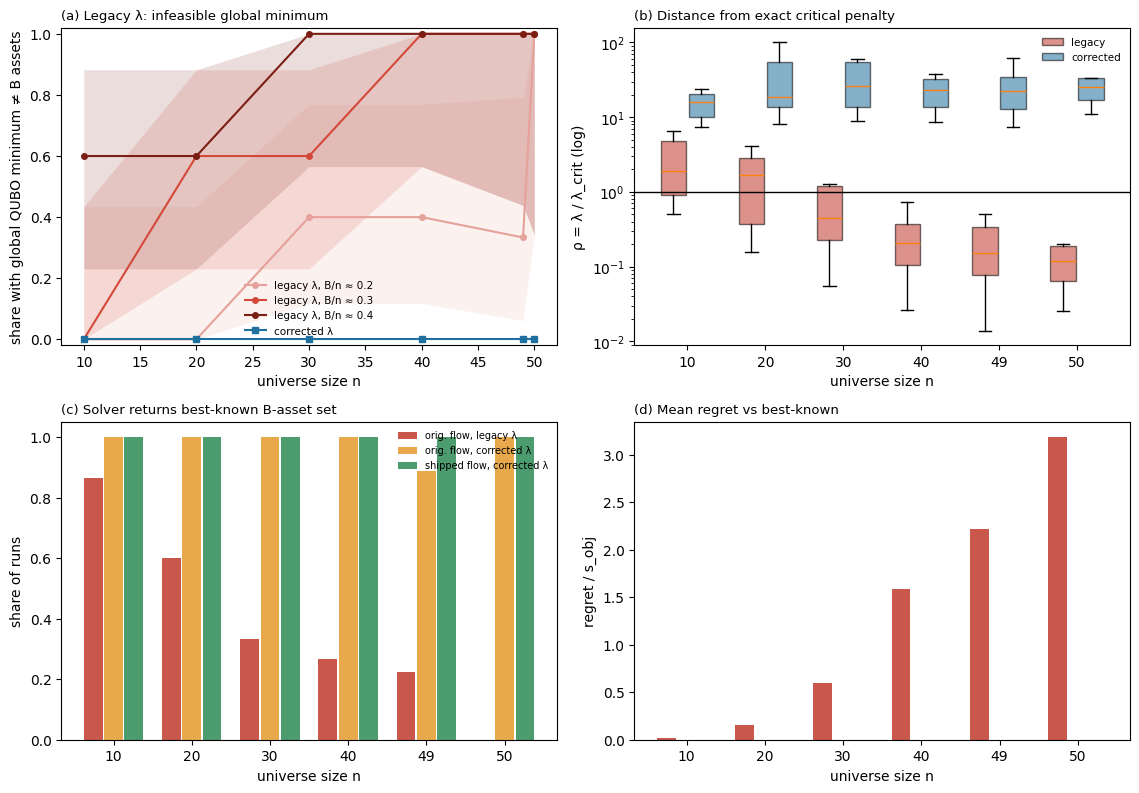

In [29]:
# ═══════════════════════════════════════════════════════════════════════════
# 26b. FIGURE: EMPIRICAL SIZE OF THE λ BUG  (NEW — replaces the original Figure 1)
# ═══════════════════════════════════════════════════════════════════════════
def _wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0, c - h), min(1, c + h))


def plot_bugsize(P, F=None, path=None, note=""):
    """P, F = outputs of bugsize_run(). (a) legacy infeasible-global-minimum rate by n and B/n;
    (b) ρ = λ/λ_crit; (c,d) solver-flow optimality and regret."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(2, 2, figsize=(11.5, 8.2))
    P = P.copy(); ns_ = sorted(P.n.unique())
    P["rbin"] = pd.cut(P.B / P.n, [0, 0.25, 0.35, 0.5], labels=["B/n ≈ 0.2", "B/n ≈ 0.3", "B/n ≈ 0.4"])
    a = ax[0, 0]
    for lab, col in zip(["B/n ≈ 0.2", "B/n ≈ 0.3", "B/n ≈ 0.4"], ["#e6a19a", "#d5493a", "#7b1e13"]):
        xs, ys, lo, hi = [], [], [], []
        for n_ in ns_:
            g = P[(P.n == n_) & (P.rbin == lab)]
            if len(g):
                k = int(g.viol_leg.sum()); l_, h_ = _wilson(k, len(g)); xs.append(n_); ys.append(k / len(g)); lo.append(l_); hi.append(h_)
        a.plot(xs, ys, "-o", color=col, ms=4, label=f"legacy λ, {lab}"); a.fill_between(xs, lo, hi, color=col, alpha=0.15, lw=0)
    a.plot(ns_, [P[P.n == n_].viol_cor.mean() for n_ in ns_], "-s", color="#1f6f9f", ms=4, label="corrected λ")
    a.set_xlabel("universe size n"); a.set_ylabel("share with global QUBO minimum ≠ B assets"); a.set_ylim(-0.02, 1.02)
    a.set_title("(a) Legacy λ: infeasible global minimum", fontsize=9.5, loc="left"); a.legend(fontsize=7.5, frameon=False)
    b = ax[0, 1]; pos = np.arange(len(ns_)); w = 0.36
    dl = [P[P.n == n_].rho_leg.replace(np.inf, np.nan).dropna().values for n_ in ns_]
    dc = [P[P.n == n_].rho_cor.replace(np.inf, np.nan).dropna().values for n_ in ns_]
    b1 = b.boxplot(dl, positions=pos - w / 2, widths=w * .9, patch_artist=True, showfliers=False)
    b2 = b.boxplot(dc, positions=pos + w / 2, widths=w * .9, patch_artist=True, showfliers=False)
    for bp, col in [(b1, "#c0392b"), (b2, "#1f6f9f")]:
        for p_ in bp["boxes"]:
            p_.set_facecolor(col); p_.set_alpha(.55)
    b.axhline(1, color="k", lw=1); b.set_yscale("log"); b.set_xticks(pos); b.set_xticklabels(ns_)
    b.set_xlabel("universe size n"); b.set_ylabel("ρ = λ / λ_crit (log)"); b.set_title("(b) Distance from exact critical penalty", fontsize=9.5, loc="left")
    b.legend([b1["boxes"][0], b2["boxes"][0]], ["legacy", "corrected"], fontsize=7.5, frameon=False)
    if F is not None and len(F):
        flows = [("orig_flow_lam_leg", "orig. flow, legacy λ", "#c0392b"), ("orig_flow_lam_cor", "orig. flow, corrected λ", "#e39a2d"),
                 ("ship_flow_lam_cor", "shipped flow, corrected λ", "#2e8b57")]
        nsF = sorted(F.n.unique()); pF = np.arange(len(nsF))
        for i, (fl, lab, col) in enumerate(flows):
            opt, mr = [], []
            for n_ in nsF:
                g = F[(F.flow == fl) & (F.n == n_)]; opt.append((g.regret_over_s <= 1e-9).mean()); mr.append(g.regret_over_s.clip(lower=0).mean())
            ax[1, 0].bar(pF + (i - 1) * .26, opt, .24, color=col, alpha=.85, label=lab); ax[1, 1].bar(pF + (i - 1) * .26, mr, .24, color=col, alpha=.85)
        for k_, (t_, yl) in enumerate([("(c) Solver returns best-known B-asset set", "share of runs"), ("(d) Mean regret vs best-known", "regret / s_obj")]):
            x_ = ax[1, k_]; x_.set_xticks(pF); x_.set_xticklabels(nsF); x_.set_xlabel("universe size n"); x_.set_ylabel(yl); x_.set_title(t_, fontsize=9.5, loc="left")
        ax[1, 0].legend(fontsize=7, frameon=False)
    if note:
        fig.text(0.01, 0.005, note, fontsize=7, color="#555")
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    if path:
        fig.savefig(path, dpi=170)
    return fig


if RUN_BUGSIZE_ABLATION:
    plot_bugsize(BUGSIZE_P, BUGSIZE_F, os.path.join(RESULTS_DIR, "fig1_lambda_bug_size.png"),
                 note=("SYNTHETIC data — not a research result." if DATA_SOURCE != "yfinance" else ""))


## 27. Walk-forward multi-window evaluation

In [30]:
# ═══════════════════════════════════════════════════════════════════════════
# 27. WALK-FORWARD MULTI-WINDOW EVALUATION  (NEW — addresses "single evaluation window")
# ═══════════════════════════════════════════════════════════════════════════
# WHY: the audit (Table B, last row) lists "single evaluation window" as an unresolved
# limitation: every market has ONE validation window and ONE holdout window of 252 days.
# A 252-day Sharpe has an annualised standard error of ~1, so a reviewer cannot tell
# "QUBO ~ MPT" from "one unlucky year".
#
# DESIGN (rolling-origin / walk-forward; every step uses only the functions above)
#   Window index w = 0,1,2,... counts back from the end of the data: window w has
#   end_offset = w * HOLDOUT_DAYS and length BACKTEST_DAYS (= HOLDOUT_DAYS).
#   Fold f (f = 0 .. K-1):   configuration is SELECTED on window f+1 (validation)
#                            and EVALUATED ONCE on window f (holdout).
#   * holdout windows 0..K-1 are pairwise NON-OVERLAPPING and contiguous in time;
#   * the validation window of fold f is the holdout window of fold f+1 (already
#     "seen" by the researcher only in the sense that fold f+1 evaluated on it; fold f's
#     selection never sees window f, so there is no leakage into any holdout);
#   * COST: K validation grids (windows 1..K) — NOT 2K, because the grid on window f+1 is
#     simultaneously fold f's validation grid and (for f+1 <= K-1) fold f+1's candidate pool.
#     Window 0 (the most recent) needs only the 3 selected configs per market.
#   * every fold is a FRESH deployment (entry cost paid again); concatenated returns
#     therefore describe "re-select every 252 days, hold buy-and-hold in between".
# DATA REQUIREMENT: rows >= max(lookback) + (K+1) * HOLDOUT_DAYS. The default 2022-2026 sample
# supports K=1 (one fold) for lookback 252 and K=0 for lookback 504. Set START_DATE earlier
# (e.g. "2015-01-01") for K>=3 — see wf_feasibility(). Longer history has two costs the paper
# must disclose: (i) survivorship bias is worse in early folds (today's constituents), (ii)
# the 80%-availability column filter + row-wise dropna in download_data will drop late-listed
# tickers (crypto especially), so early-fold universes can be smaller than requested
# (prepare_experiment records `universe_shortfall`).
RUN_WALK_FORWARD = True       # expensive: K validation grids
WF_N_FOLDS = 4
WF_PAIRS = [("QUBO", "MPT"), ("QUBO", "EqualWeight"), ("MPT", "EqualWeight")]


def wf_feasibility(price_data, lookbacks=None, n_folds=None):
    """Which markets/lookbacks can support n_folds folds with the loaded data?"""
    lookbacks = lookbacks or LOOKBACKS; n_folds = n_folds or WF_N_FOLDS
    H = HOLDOUT_DAYS; rows = []
    for m, p in price_data.items():
        N = len(p)
        for lb in lookbacks:
            rows.append({"market": m, "rows": N, "start": p.index[0].date(), "end": p.index[-1].date(),
                         "lookback": lb, "rows_needed": lb + (n_folds + 1) * H,
                         "max_folds_possible": max(0, (N - lb) // H - 1),
                         "supports_requested_folds": N >= lb + (n_folds + 1) * H})
    return pd.DataFrame(rows)


def _run_selected(sel_row, market, price_data, volume_data, end_offset):
    """Evaluate ONE validation-selected configuration on the window with this end_offset.
    Seeds are derived from the same keys as in the grid, so a config evaluated here is
    bit-identical to its row in a grid on the same window (asserted in run_walk_forward)."""
    s = sel_row; u = UNIVERSE_SIZES[s["universe_label"]]; lb = int(s["lookback"])
    p, v = price_data[market], volume_data[market]
    if s["strategy"] == "QUBO":
        return run_qubo_experiment(market, p, v, u, int(s["B"]), float(s["q"]), lb, BACKTEST_DAYS,
                                   end_offset=end_offset)
    if s["strategy"] == "MPT":
        return run_mpt_experiment(market, p, v, u, float(s["q"]), lb, BACKTEST_DAYS, end_offset=end_offset)
    if s["strategy"] == "EqualWeight":
        return run_equal_weight_experiment(market, p, v, u, lb, BACKTEST_DAYS, end_offset=end_offset)
    raise ValueError(s["strategy"])


def run_walk_forward(markets, n_folds, universe_sizes, cardinalities, q_values, lookbacks,
                     price_data, volume_data, include_rb=False, verbose=True):
    H = HOLDOUT_DAYS
    grids, objs = {}, {}
    for w in range(1, n_folds + 1):
        if verbose:
            print(f"[WF] validation/candidate grid on window w={w} (end_offset={w * H}) ...")
        grids[w], objs[w] = run_experiment_grid(
            markets, universe_sizes, cardinalities, q_values, lookbacks, price_data=price_data,
            volume_data=volume_data, end_offset=w * H, window_label=f"wf{w}", include_rb=False,
            verbose=verbose)
    folds = {}
    for f in range(n_folds):
        sel = select_on_validation(grids[f + 1])
        hobj, notes = {}, []
        for _, s in sel.iterrows():
            m, strat = s["market"], s["strategy"]
            try:
                r = _run_selected(s, m, price_data, volume_data, end_offset=f * H)
            except Exception as e:
                notes.append(f"{m}/{strat}: {e!r}"); continue
            if r is None:
                notes.append(f"{m}/{strat}: infeasible on window {f}"); continue
            if f >= 1:   # integrity: identical to the row the grid on window f produced for this config
                g = grids[f]; mask = (g["market"] == m) & (g["strategy"] == strat) & (g["status"] == "ok")
                for k in CONFIG_KEYS[strat]:
                    mask &= g[k] == s[k]
                if mask.sum() == 1:
                    assert abs(g[mask].iloc[0]["sharpe_ratio"] - r["sharpe_ratio"]) < 1e-9, \
                        f"fold {f} {m} {strat}: re-evaluation differs from grid row"
            r = {**r, "fold": f, "window": f, "selected_on_window": f + 1,
                 "validation_sharpe": float(s["validation_sharpe_ratio"]),
                 "n_validation_candidates": int(s["n_candidates"])}
            hobj[(m, strat)] = r
        if include_rb:
            for m in markets:
                if (m, "QUBO") in hobj:
                    b = hobj[(m, "QUBO")]
                    hobj[(m, "QUBO_RB")] = run_qubo_experiment_with_rebalancing(
                        m, price_data[m], volume_data[m], b["universe_size_requested"], b["B"], b["q"],
                        b["lookback"], BACKTEST_DAYS, end_offset=f * H, base_result=b)
        # protocol assertion: validation window strictly precedes the holdout window it selected for
        for (m, strat), r in hobj.items():
            v = grids[f + 1]; v = v[(v["market"] == m) & (v["status"] == "ok")]
            assert v["test_end"].max() < r["test_start"], f"fold {f} {m}: validation overlaps holdout"
        folds[f] = {"selection": sel, "obj": hobj, "notes": notes}
        if verbose:
            print(f"[WF] fold {f}: {len(hobj)} holdout evaluations" + (f" | notes: {notes}" if notes else ""))
    return {"grids": grids, "grid_objects": objs, "folds": folds, "n_folds": n_folds}


def _fold_returns(obj):
    return nav_returns(obj["nav"], INITIAL_CAPITAL).values


def wf_collect(wf, n_boot=10000, block=20):
    """Per-fold table and pooled paired tests (concatenated chronological holdout returns)."""
    rows = []
    for f, d in wf["folds"].items():
        for (m, s), o in d["obj"].items():
            rows.append({"fold": f, "market": m, "strategy": s, "test_start": o["test_start"],
                         "test_end": o["test_end"], "validation_sharpe": o["validation_sharpe"],
                         "holdout_sharpe": o["sharpe_ratio"], "ann_return": o["ann_return"],
                         "volatility": o["volatility"], "max_drawdown": o["max_drawdown"],
                         "total_return": o["total_return"], "universe": o["universe_size_requested"],
                         "universe_realised": o["universe_size"], "lookback": o["lookback"],
                         "B": o.get("B", np.nan), "q": o.get("q", np.nan)})
    per_fold = pd.DataFrame(rows)
    tests, wf_sharpe = [], []
    for m in sorted(per_fold["market"].unique()) if len(per_fold) else []:
        P, rf = ppy(m), RISK_FREE_RATES.get(m, 0.0)
        for s in ["QUBO", "MPT", "EqualWeight"]:
            fs = sorted([f for f, d in wf["folds"].items() if (m, s) in d["obj"]], reverse=True)  # chronological
            if not fs:
                continue
            r = np.concatenate([_fold_returns(wf["folds"][f]["obj"][(m, s)]) for f in fs])
            ci = bootstrap_sharpe_ci(r, rf, n_boot=min(n_boot, 5000), block_size=block, periods=P,
                                     seed=derive_seed(m, s, "wf_ci"))
            wf_sharpe.append({"market": m, "strategy": s, "n_folds": len(fs), "n_days": len(r),
                              "sharpe": ci["sharpe"], "ci_low": ci["ci_low"], "ci_high": ci["ci_high"]})
        for a, b in WF_PAIRS:
            fs = sorted([f for f, d in wf["folds"].items() if (m, a) in d["obj"] and (m, b) in d["obj"]],
                        reverse=True)
            if not fs:
                continue
            for f in fs:
                assert (wf["folds"][f]["obj"][(m, a)]["nav"].index == wf["folds"][f]["obj"][(m, b)]["nav"].index).all()
            ra = np.concatenate([_fold_returns(wf["folds"][f]["obj"][(m, a)]) for f in fs])
            rb = np.concatenate([_fold_returns(wf["folds"][f]["obj"][(m, b)]) for f in fs])
            res = paired_sharpe_difference(ra, rb, rf, P, n_boot, block, seed=derive_seed(m, a, b, "wf"))
            per = np.array([wf["folds"][f]["obj"][(m, a)]["sharpe_ratio"] - wf["folds"][f]["obj"][(m, b)]["sharpe_ratio"]
                            for f in fs])
            tests.append({"market": m, "comparison": f"{a} - {b}", "n_folds": len(fs), "n_days": res["n_days"],
                          "diff": res["diff"], "ci_low": res["ci_low"], "ci_high": res["ci_high"],
                          "p_value": res["p_value"], "return_corr": res["return_corr"],
                          "folds_a_better": int((per > 0).sum()), "fold_diff_mean": float(per.mean()),
                          "fold_diff_sd": float(per.std(ddof=1)) if len(per) > 1 else np.nan})
    tests = pd.DataFrame(tests)
    if not tests.empty:
        tests["p_holm"] = np.nan
        for comp, g in tests.groupby("comparison"):
            tests.loc[g.index, "p_holm"] = holm_adjust(g["p_value"].values)
    return per_fold, pd.DataFrame(wf_sharpe), tests


def sharpe_diff_se(years, rho, sharpe=0.5):
    """Approximate SE of a paired Sharpe difference (annual units); iid/Lo-style approximation.
    Verified against simulation in section 28."""
    return float(np.sqrt(2.0 * (1.0 - rho) * (1.0 + 0.5 * sharpe ** 2) / years))


def sharpe_diff_mde(years, rho, sharpe=0.5, z_alpha=1.96, z_power=0.8416):
    """Minimum detectable Sharpe difference at 5% two-sided / 80% power."""
    return (z_alpha + z_power) * sharpe_diff_se(years, rho, sharpe)


if RUN_WALK_FORWARD:
    print(wf_feasibility(price_data).to_string())
    WF = run_walk_forward(MARKETS, WF_N_FOLDS, UNIVERSE_SIZES, CARDINALITIES, Q_VALUES, LOOKBACKS,
                          price_data, volume_data, include_rb=False)
    WF_PER_FOLD, WF_SHARPE, WF_TESTS = wf_collect(WF)
    print(WF_PER_FOLD.round(3).to_string())
    print(WF_SHARPE.round(3).to_string())
    print(WF_TESTS.round(4).to_string())
    _st = datetime.now().strftime("%Y%m%d_%H%M%S")
    WF_PER_FOLD.to_csv(os.path.join(RESULTS_DIR, f"wf_per_fold_{_st}.csv"), index=False)
    WF_SHARPE.to_csv(os.path.join(RESULTS_DIR, f"wf_sharpe_{_st}.csv"), index=False)
    WF_TESTS.to_csv(os.path.join(RESULTS_DIR, f"wf_paired_tests_{_st}.csv"), index=False)
    if DATA_SOURCE != "yfinance":
        print("!! SYNTHETIC DATA — code-path check only; no number above is a research result.")
else:
    print("RUN_WALK_FORWARD=False — walk-forward skipped. Design MDE (rho=0.9, Sharpe 0.5): "
          + ", ".join(f"{y}y: {sharpe_diff_mde(y, 0.9):.2f}" for y in (1, 2, 4)))


    market  rows       start         end  lookback  rows_needed  max_folds_possible  supports_requested_folds
0    india   988  2022-01-03  2025-12-31       126         1386                   2                     False
1    india   988  2022-01-03  2025-12-31       252         1512                   1                     False
2    india   988  2022-01-03  2025-12-31       504         1764                   0                     False
3      usa  1003  2022-01-03  2025-12-31       126         1386                   2                     False
4      usa  1003  2022-01-03  2025-12-31       252         1512                   1                     False
5      usa  1003  2022-01-03  2025-12-31       504         1764                   0                     False
6   europe   958  2022-01-04  2025-12-30       126         1386                   2                     False
7   europe   958  2022-01-04  2025-12-30       252         1512                   1                     False
8   europe

01:02:07 - WARNING - india: universe u=50 has only 49 assets


  [wf1] india: 195 rows (59s elapsed)
  [wf1] usa: 195 rows (118s elapsed)


01:03:56 - WARNING - europe: universe u=50 has only 47 assets
01:04:03 - WARNING - europe: universe u=50 has only 48 assets


  [wf1] europe: 195 rows (174s elapsed)
  [wf1] japan: 195 rows (230s elapsed)


...

01:10:39 - WARNING - crypto: universe u=50 has only 49 assets
01:10:44 - WARNING - crypto: universe u=50 has only 49 assets


  [wf3] crypto: 195 rows (53s elapsed)
[WF] validation/candidate grid on window w=4 (end_offset=1008) ...
  [wf4] india: 195 rows (0s elapsed)
  [wf4] usa: 195 rows (0s elapsed)
  [wf4] europe: 195 rows (0s elapsed)
  [wf4] japan: 195 rows (1s elapsed)


01:11:14 - WARNING - crypto: universe u=50 has only 49 assets


  [wf4] crypto: 195 rows (31s elapsed)
[WF] fold 0: 15 holdout evaluations
[WF] fold 1: 15 holdout evaluations
[WF] fold 2: 3 holdout evaluations
[WF] fold 3: 3 holdout evaluations
    fold  market     strategy test_start   test_end  validation_sharpe  holdout_sharpe  ann_return  volatility  max_drawdown  total_return  universe  universe_realised  lookback     B    q
0      0  crypto  EqualWeight 2025-04-24 2025-12-31              0.831           1.208       0.853       0.733        -0.336         0.531        20                 20       504   NaN  NaN
1      0  crypto          MPT 2025-04-24 2025-12-31              1.637           0.052      -0.086       0.478        -0.319        -0.060        30                 30       126   NaN  0.3
2      0  crypto         QUBO 2025-04-24 2025-12-31              1.614          -0.303      -0.264       0.536        -0.400        -0.191        20                 20       126   4.0  0.5
3      0  europe  EqualWeight 2024-12-05 2025-12-30            

C:\Users\yashg\AppData\Local\Temp\ipykernel_35616\3974255235.py:186: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(WF_PER_FOLD.round(3).to_string())


## 28. Calibration of the paired Sharpe-difference test

In [31]:
# ═══════════════════════════════════════════════════════════════════════════
# 28. CALIBRATION OF THE PAIRED SHARPE-DIFFERENCE TEST  (NEW — needs NO market data)
# ═══════════════════════════════════════════════════════════════════════════
# Question a reviewer will ask: "with ONE 252-day window, could your test have detected a
# real difference at all, and does its nominal 5% level hold?"  This cell answers it by
# simulation: two strategies with a KNOWN true Sharpe gap, return correlation rho, fat tails
# (multivariate t, 5 df) and a shared stochastic-volatility path (so returns are dependent
# over time), tested with the SAME paired circular-block-bootstrap test used in section 17/21
# (paired_sharpe_difference). Rejection rate at delta=0 is the empirical SIZE; at delta>0 the POWER.
RUN_TEST_CALIBRATION = True
CAL_HORIZONS_DAYS = [252, 504, 756, 1008]      # 1..4 years  (1 window .. 4 walk-forward folds)
CAL_DELTAS = [0.0, 0.3, 0.6, 1.0]              # true annual Sharpe gap, strategy A minus B
CAL_RHO = 0.9                                   # return correlation between the two strategies
CAL_REPS, CAL_BOOT = 250, 1000


def _simulate_pair(T, rho, delta, reps, rng, sharpe_b=0.5, ann_vol=0.15, nu=5, alpha=0.10, beta=0.88, P=252):
    sd = ann_vol / np.sqrt(P)
    h = np.ones(reps); H = np.empty((reps, T))
    for t in range(T):                      # common stochastic vol, unit long-run variance
        H[:, t] = h
        c = rng.standard_normal(reps)
        h = (1 - alpha - beta) + alpha * c ** 2 + beta * h
    g = rng.standard_normal((reps, T, 2))
    g[:, :, 1] = rho * g[:, :, 0] + np.sqrt(1 - rho ** 2) * g[:, :, 1]
    w = rng.chisquare(nu, size=(reps, T, 1)) / nu
    z = g / np.sqrt(w) * np.sqrt((nu - 2) / nu)             # unit-variance multivariate t
    mu_b = sharpe_b * sd / np.sqrt(P); mu_a = (sharpe_b + delta) * sd / np.sqrt(P)
    vol = sd * np.sqrt(H)
    return mu_a + vol * z[:, :, 0], mu_b + vol * z[:, :, 1]


def test_size_power(horizons=None, deltas=None, rho=None, reps=None, n_boot=None, block=20, seed=123):
    horizons = horizons or CAL_HORIZONS_DAYS; deltas = deltas or CAL_DELTAS
    rho = CAL_RHO if rho is None else rho; reps = reps or CAL_REPS; n_boot = n_boot or CAL_BOOT
    rng = np.random.default_rng(seed); rows = []
    for T in horizons:
        for d in deltas:
            A, Bm = _simulate_pair(T, rho, d, reps, rng)
            rej, ci_cover, ests = 0, 0, []
            for i in range(reps):
                res = paired_sharpe_difference(A[i], Bm[i], 0.0, 252, n_boot, block, seed=int(rng.integers(1 << 30)))
                rej += int(res["p_value"] < 0.05)
                ci_cover += int(res["ci_low"] <= d <= res["ci_high"])
                ests.append(res["diff"])
            ests = np.array(ests)
            rows.append({"horizon_days": T, "years": T / 252, "true_delta": d, "rho": rho,
                         "reject_rate_5pct": rej / reps, "ci95_coverage": ci_cover / reps,
                         "mean_est": float(ests.mean()), "sd_est": float(ests.std(ddof=1)),
                         "approx_se_formula": sharpe_diff_se(T / 252, rho) if "sharpe_diff_se" in globals() else np.nan,
                         "mde_formula": sharpe_diff_mde(T / 252, rho) if "sharpe_diff_mde" in globals() else np.nan,
                         "reps": reps, "n_boot": n_boot})
    return pd.DataFrame(rows)


if RUN_TEST_CALIBRATION:
    CAL = test_size_power()
    print(CAL.round(3).to_string())
    CAL.to_csv(os.path.join(RESULTS_DIR, "test_calibration.csv"), index=False)
else:
    print("RUN_TEST_CALIBRATION=False — skipped.")


    horizon_days  years  true_delta  rho  reject_rate_5pct  ci95_coverage  mean_est  sd_est  approx_se_formula  mde_formula  reps  n_boot
0            252    1.0         0.0  0.9             0.056          0.940     0.032   0.428              0.474        1.329   250    1000
1            252    1.0         0.3  0.9             0.132          0.888     0.298   0.489              0.474        1.329   250    1000
2            252    1.0         0.6  0.9             0.332          0.940     0.594   0.440              0.474        1.329   250    1000
3            252    1.0         1.0  0.9             0.612          0.888     1.025   0.474              0.474        1.329   250    1000
4            504    2.0         0.0  0.9             0.040          0.956     0.007   0.297              0.335        0.940   250    1000
5            504    2.0         0.3  0.9             0.176          0.932     0.286   0.321              0.335        0.940   250    1000
6            504    2.0         0.

In [32]:
# ═══════════════════════════════════════════════════════════════════════════
# 19. SINGLE-COMBINATION EXPERIMENT
# ═══════════════════════════════════════════════════════════════════════════
# Debug exactly ONE configuration with the SAME functions the grid uses.
# SINGLE_END_OFFSET = 0            -> final window (the holdout, if you use the
#                                     holdout protocol: do NOT tune on it)
# SINGLE_END_OFFSET = HOLDOUT_DAYS -> validation window
SINGLE_MARKET          = "usa"
SINGLE_UNIVERSE_SIZE   = 20
SINGLE_B               = 6            # = int(0.3 * 20)
SINGLE_Q               = 0.5
SINGLE_LOOKBACK        = 252
SINGLE_BACKTEST_DAYS   = BACKTEST_DAYS
SINGLE_SEED            = EXPERIMENT_SEED
SINGLE_END_OFFSET      = HOLDOUT_DAYS
SINGLE_RUN_REBALANCING = True
SINGLE_RUN_STABILITY   = True


def run_single_combination(market, u, B, q, lookback, backtest_days, seed, end_offset,
                           with_rb=True, with_stability=True, verbose=True):
    t0 = time.perf_counter()
    rq = run_qubo_experiment(market, price_data[market], volume_data[market], u, B, q, lookback,
                             backtest_days, seed=seed, end_offset=end_offset)
    t_q = time.perf_counter() - t0
    if rq is None:
        print("configuration infeasible (insufficient data)"); return None
    t0 = time.perf_counter()
    rm = run_mpt_experiment(market, price_data[market], volume_data[market], u, q, lookback,
                            backtest_days, seed=seed, end_offset=end_offset)
    t_m = time.perf_counter() - t0
    rrb = None
    if with_rb:
        t0 = time.perf_counter()
        rrb = run_qubo_experiment_with_rebalancing(market, price_data[market], volume_data[market], u, B, q,
                                                   lookback, backtest_days, seed=seed,
                                                   end_offset=end_offset, base_result=rq)
        t_rb = time.perf_counter() - t0
    # ── consistency proofs ─────────────────────────────────────────────────
    assert rq["final_count"] == B == rq["n_selected"], "cardinality"
    assert list(rq["tickers"]) == list(rm["tickers"]), "QUBO/MPT universes differ"
    assert rq["test_start"] == rm["test_start"] and rq["test_end"] == rm["test_end"]
    for r in [rq, rm] + ([rrb] if rrb else []):
        chk = nav_metrics(r["nav"], INITIAL_CAPITAL, market)
        assert abs(chk["sharpe_ratio"] - r["sharpe_ratio"]) < 1e-12, "metrics != NAV"
    rows = []
    for name, r, t in [("QUBO", rq, t_q), ("MPT", rm, t_m)] + ([("QUBO_RB", rrb, t_rb)] if rrb else []):
        rows.append({"strategy": name, "sharpe": r["sharpe_ratio"], "ann_return": r["ann_return"],
                     "total_return": r["total_return"], "volatility": r["volatility"],
                     "max_drawdown": r["max_drawdown"], "n_held": r.get("n_held"),
                     "end_to_end_runtime_s": t, "optimiser_runtime_s": r.get("runtime_s")})
    # NOTE: QUBO_RB end-to-end excludes the initial selection (re-used from QUBO);
    #       its optimiser_runtime_s = initial selection + all re-optimisations.
    summary = pd.DataFrame(rows).set_index("strategy")
    stab = None
    if with_stability:
        prep = prepare_experiment(market, price_data[market], volume_data[market], u, lookback,
                                  backtest_days, seed, end_offset)
        Q_single, _ = build_qubo_model(prep["mu"], prep["cov"], q, B, prep["returns"], market)
        stab = run_stability(Q_single, B, n_seeds=3, num_reads=20, n_sweeps=500, base_seed=seed)
        assert stab["solver_cardinality_violations"] == 0
    if verbose:
        print(f"market={market} universe_size={rq['universe_size']} (requested {u}) B={B} q={q} "
              f"lookback={lookback} backtest_days={backtest_days} seed={seed} end_offset={end_offset}")
        print(f"window: {rq['test_start'].date()} → {rq['test_end'].date()} | mode={rq['qubo_mode']} "
              f"garch={rq['garch_mode']} q_eff={rq['q_eff']:.3f} lambda={rq['lambda_used']:.3f}")
        print(f"cardinality: final={rq['final_count']} (B={B}) | raw Neal count={rq['raw_neal_count']} "
              f"| Neal feasible fraction={rq['neal_feasible_fraction']:.2f} | won_by={rq['won_by']}")
        print(f"selected ({rq['n_selected']}): {rq['selected_assets']}")
        print(f"MPT holdings (>1e-4): {rm['n_held']}  | weight solvers: QUBO={rq['weight_solver']} MPT={rm['weight_solver']}")
        if rrb:
            print(f"QUBO_RB: rebalances={rrb['n_rebalances']} failures={rrb['n_reopt_failures']} "
                  f"identical_to_bah={rrb['identical_to_bah']} tax={rrb['total_tax_paid']:,.0f} "
                  f"tc={rrb['total_tc_paid']:,.0f} max_assets_held={rrb['max_assets_held']}")
        if stab:
            print(f"stability: jaccard={stab['mean_pairwise_jaccard']:.2f} "
                  f"consensus_fixed={stab['consensus_cardinality_fixed']} distinct={stab['n_distinct_solutions']}")
        print(summary.to_string(float_format=lambda x: f"{x:.4f}"))
        print("Consistency checks passed: cardinality, identical universe/window, metrics == NAV.")
    return {"qubo": rq, "mpt": rm, "qubo_rb": rrb, "summary": summary, "stability": stab}


if RUN_SINGLE_COMBINATION:
    if SINGLE_MARKET not in price_data:
        raise KeyError(f"SINGLE_MARKET={SINGLE_MARKET!r} not loaded; available: {list(price_data)}")
    SINGLE_RESULT = run_single_combination(SINGLE_MARKET, SINGLE_UNIVERSE_SIZE, SINGLE_B, SINGLE_Q,
                                           SINGLE_LOOKBACK, SINGLE_BACKTEST_DAYS, SINGLE_SEED,
                                           SINGLE_END_OFFSET, SINGLE_RUN_REBALANCING, SINGLE_RUN_STABILITY)

In [33]:
os.makedirs("results_audited", exist_ok=True)
q_nav, m_nav = SINGLE_RESULT["qubo"]["nav"], SINGLE_RESULT["mpt"]["nav"]
bench = bench_data[MARKET].reindex(q_nav.index).ffill() if "bench_data" in globals() and MARKET in bench_data else None
out = pd.DataFrame({"QUBO": q_nav, "MPT": m_nav})
if bench is not None:
    out["Benchmark"] = bench
path = f"results_audited/nav_{MARKET}_{q_nav.index[0].date()}_{q_nav.index[-1].date()}.csv"
out.rename_axis("Date").to_csv(path)
print("wrote", path)

NameError: name 'SINGLE_RESULT' is not defined

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# PLOT — Portfolio Value | Drawdown: QUBO vs MPT vs Benchmark   (no QUBO_RB)
# ═══════════════════════════════════════════════════════════════════════════
# Pure CSV mode: no dependency on a live notebook session / SINGLE_RESULT.
# Data source, in priority order:
#   1) NAV_CSV explicitly set to a path      -> use it directly
#   2) auto-discovered nav_{MARKET}_*.csv in RESULTS_DIR (newest by end date)
#
# NOTE: the grid / holdout / selection CSVs written by Section 24 hold only
# scalar metrics (Sharpe, return, ...). They contain NO daily NAV, so they
# cannot be plotted as a curve. Only a nav_*.csv (written by Section 19 with
# EXPORT_NAV_CSV=True, from a live session) has the daily series this cell needs.
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

# ── settings ───────────────────────────────────────────────────────────────
NAV_CSV          = None            # force a specific file; None -> auto-discover in RESULTS_DIR
RESULTS_DIR      = "results_audited"   # where nav_*.csv files live
MARKET           = "usa"
INITIAL_CAPITAL  = 1_600_000
OUT_DIR          = "plots_audited"
OUT_NAME         = None            # None -> f"portfolio_value_drawdown_{MARKET}.png"

RISK_FREE = {"india": 0.065, "usa": 0.0525, "europe": 0.035, "japan": 0.001, "crypto": 0.0}
PERIODS   = {"india": 252, "usa": 252, "europe": 252, "japan": 252, "crypto": 365}

CYAN, PINK, GREY = "#5bc8c8", "#c85b8a", "#888888"


# ── helpers ────────────────────────────────────────────────────────────────
def sharpe_from_nav(nav: pd.Series, capital: float, market: str) -> float:
    """Same definition as the notebook's nav_metrics(): day-0 return is vs initial capital."""
    P, rf = PERIODS.get(market, 252), RISK_FREE.get(market, 0.0)
    prev = nav.shift(1); prev.iloc[0] = capital
    ex = (nav / prev - 1.0).values - rf / P
    sd = ex.std(ddof=1)
    return float(ex.mean() / sd * np.sqrt(P)) if sd > 1e-12 else 0.0


def _find_col(df, names):
    lower = {c.lower(): c for c in df.columns}
    for n in names:
        if n.lower() in lower:
            return lower[n.lower()]
    return None


def find_latest_nav_csv(results_dir, market):
    """Look for previously-exported nav_{market}_{start}_{end}.csv files and
    return the path with the latest end date, or None if none exist."""
    pattern = os.path.join(results_dir, f"nav_{market}_*.csv")
    candidates = glob.glob(pattern)
    if not candidates:
        return None

    def end_date(path):
        m = re.search(r"nav_.*_(\d{4}-\d{2}-\d{2})\.csv$", os.path.basename(path))
        return m.group(1) if m else ""

    candidates.sort(key=end_date)  # lexicographic == chronological for YYYY-MM-DD
    return candidates[-1]


def load_navs_from_csv(path):
    df = pd.read_csv(path)
    date_col = _find_col(df, ["date", "Date", "index", "Unnamed: 0"]) or df.columns[0]
    df[date_col] = pd.to_datetime(df[date_col])
    s_col = _find_col(df, ["strategy"])
    if s_col is not None:                                   # long format
        v_col = _find_col(df, ["nav", "value", "portfolio_value"])
        df = df.pivot(index=date_col, columns=s_col, values=v_col)
    else:                                                   # wide format
        df = df.set_index(date_col)
    df = df.sort_index()
    q, m = _find_col(df, ["QUBO"]), _find_col(df, ["MPT"])
    b = _find_col(df, ["Benchmark", "Bench"])
    if q is None or m is None:
        raise KeyError(f"NAV CSV needs 'QUBO' and 'MPT' columns; found {list(df.columns)}")
    bench = df[b] if b is not None else None
    return df[q], df[m], bench


# ── load ───────────────────────────────────────────────────────────────────
resolved_csv = NAV_CSV or find_latest_nav_csv(RESULTS_DIR, MARKET)

if not resolved_csv or not os.path.exists(resolved_csv):
    available = sorted(glob.glob(os.path.join(RESULTS_DIR, "nav_*.csv")))
    raise FileNotFoundError(
        f"No NAV CSV found for market='{MARKET}' in '{RESULTS_DIR}/'.\n"
        f"This cell only plots from a nav_{{market}}_*.csv file — it does not "
        f"run a live session anymore.\n"
        f"nav_*.csv files present in '{RESULTS_DIR}/': {available or '(none)'}\n"
        f"If you have no nav_*.csv at all yet, you need to (re)run the pipeline "
        f"section (Section 19) once with EXPORT_NAV_CSV=True in a live kernel "
        f"to generate one — the daily NAV series doesn't exist in the "
        f"holdout/selection/grid CSVs or the objects_*.pkl files, only scalar metrics do."
    )

q_nav, m_nav, bench = load_navs_from_csv(resolved_csv)
src = f"CSV: {resolved_csv}"

idx = q_nav.index.intersection(m_nav.index)                  # identical dates for every curve
q_nav, m_nav = q_nav.loc[idx].astype(float), m_nav.loc[idx].astype(float)
if bench is not None:
    bench = bench.reindex(idx).ffill().bfill().astype(float)
    bench = bench / bench.iloc[0] * INITIAL_CAPITAL          # rebase to the same starting capital

# ── plot: Portfolio Value | Drawdown, side by side ─────────────────────────
FS_TITLE, FS_LABEL, FS_TICK, FS_LEGEND = 24, 22, 19, 20

def drawdown_pct(nav, capital):
    path = np.concatenate([[capital], nav.values]); peak = np.maximum.accumulate(path)
    return pd.Series(((path - peak) / peak * 100)[1:], index=nav.index)

fig, (ax, ax_dd) = plt.subplots(1, 2, figsize=(26, 9))
fig.patch.set_facecolor("#f4f6f8")

q_lab = f"QUBO (Sh={sharpe_from_nav(q_nav, INITIAL_CAPITAL, MARKET):.2f})"
m_lab = f"MPT (Sh={sharpe_from_nav(m_nav, INITIAL_CAPITAL, MARKET):.2f})"
ax.plot(q_nav.index, q_nav.values, color=CYAN, lw=3.2, label=q_lab)
ax.plot(m_nav.index, m_nav.values, color=PINK, lw=3.2, label=m_lab)
ax_dd.plot(q_nav.index, drawdown_pct(q_nav, INITIAL_CAPITAL).values, color=CYAN, lw=2.8, label=q_lab)
ax_dd.plot(m_nav.index, drawdown_pct(m_nav, INITIAL_CAPITAL).values, color=PINK, lw=2.8, label=m_lab)
ax_dd.fill_between(q_nav.index, drawdown_pct(q_nav, INITIAL_CAPITAL).values, 0, color=CYAN, alpha=0.12)
ax_dd.fill_between(m_nav.index, drawdown_pct(m_nav, INITIAL_CAPITAL).values, 0, color=PINK, alpha=0.12)
if bench is not None:
    ax.plot(bench.index, bench.values, color=GREY, lw=3.0, ls="--", label="Benchmark")
    ax_dd.plot(bench.index, drawdown_pct(bench, INITIAL_CAPITAL).values, color=GREY, lw=2.6, ls="--", label="Benchmark")

for a_, ttl, yl in [(ax, f"{MARKET.upper()} — Portfolio Value", "Portfolio Value"),
                    (ax_dd, f"{MARKET.upper()} — Drawdown", "Drawdown (%)")]:
    a_.set_title(ttl, fontweight="bold", fontsize=FS_TITLE, color="#222222", pad=12)
    a_.set_xlabel("Date", fontsize=FS_LABEL, color="#333333")
    a_.set_ylabel(yl, fontsize=FS_LABEL, color="#333333")
    a_.spines[["top", "right"]].set_visible(False)
    a_.spines[["left", "bottom"]].set_color("#cccccc")
    a_.tick_params(colors="#333333", labelsize=FS_TICK, length=6, width=1.2)
    a_.grid(True, alpha=0.25, linestyle="--", color="#cccccc")
    a_.set_facecolor("white")
    a_.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    a_.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    for lab in a_.get_xticklabels():
        lab.set_rotation(30); lab.set_ha("right")

ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e6:.2f}M" if abs(x) >= 1e6 else (f"{x/1e3:.1f}K" if abs(x) >= 1e3 else f"{x:.2f}")))
ax.legend(fontsize=FS_LEGEND, framealpha=0.9, loc="upper left", markerscale=2)
ax_dd.legend(fontsize=FS_LEGEND, framealpha=0.9, loc="lower left", markerscale=2)

plt.tight_layout()
os.makedirs(OUT_DIR, exist_ok=True)
save_path = os.path.join(OUT_DIR, OUT_NAME or f"portfolio_value_drawdown_{MARKET}.png")
fig.savefig(save_path, dpi=150, bbox_inches="tight")
print(f"source: {src} | {idx[0].date()} → {idx[-1].date()} | saved -> {save_path}")
plt.show()


In [ ]:
!pip install pyscipopt ecos

   ---------------------------------------- 0.0/48.2 MB ? eta -:--:--
    --------------------------------------- 0.8/48.2 MB 8.5 MB/s eta 0:00:06
    --------------------------------------- 1.0/48.2 MB 10.1 MB/s eta 0:00:05
   - -------------------------------------- 2.1/48.2 MB 3.9 MB/s eta 0:00:12
   --- ------------------------------------ 4.2/48.2 MB 6.5 MB/s eta 0:00:07
   --- ------------------------------------ 4.2/48.2 MB 6.5 MB/s eta 0:00:07
   ---- ----------------------------------- 5.2/48.2 MB 5.1 MB/s eta 0:00:09
   ----- ---------------------------------- 6.3/48.2 MB 5.1 MB/s eta 0:00:09
   ------ --------------------------------- 8.4/48.2 MB 5.6 MB/s eta 0:00:08
   ------ --------------------------------- 8.4/48.2 MB 5.6 MB/s eta 0:00:08
   ------ --------------------------------- 8.4/48.2 MB 5.6 MB/s eta 0:00:08
   ------ --------------------------------- 8.4/48.2 MB 5.6 MB/s eta 0:00:08
   ------ --------------------------------- 8.4/48.2 MB 5.6 MB/s eta 0:00:08
   --


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  N=20   seed=42   neal_pipeline      0.761s  feasible=True  status=mv:CLARABEL:optimal
  N=20   seed=42   SCIP               0.105s  feasible=True  status=optimal
  N=20   seed=42   ECOS_BB            0.012s  feasible=True  status=optimal
  N=20   seed=123  neal_pipeline      0.703s  feasible=True  status=mv:CLARABEL:optimal
  N=20   seed=123  SCIP               0.188s  feasible=True  status=optimal
  N=20   seed=123  ECOS_BB            0.007s  feasible=True  status=optimal
  N=20   seed=7    neal_pipeline      0.680s  feasible=True  status=mv:CLARABEL:optimal
  N=20   seed=7    SCIP               0.148s  feasible=True  status=optimal
  N=20   seed=7    ECOS_BB            0.007s  feasible=True  status=optimal
  N=30   seed=42   neal_pipeline      0.722s  feasible=True  status=mv:CLARABEL:optimal
  N=30   seed=42   SCIP               0.104s  feasible=True  status=optimal
  N=30   seed=42   ECOS_BB            0.009s  feasible=True  status=optimal
  N=30   seed=123  neal_pipeline      0.

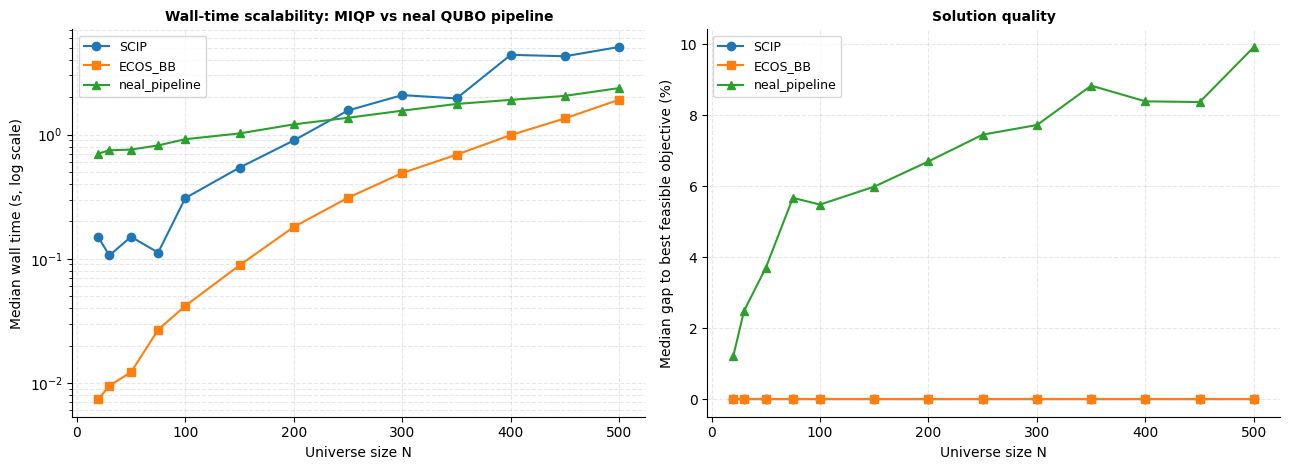

In [37]:
# ═══════════════════════════════════════════════════════════════════════════
# 29. SOLVER TIME COMPARISON — neal QUBO pipeline vs SCIP vs ECOS_BB
#     (re-creates "Experiment A: scalability on synthetic instances" of the paper,
#      Avdoshin & Patrushev, Trudy ISP RAN 38(4-2), 2026, Table 1 / Fig. 1-2)
# ═══════════════════════════════════════════════════════════════════════════
# WHAT IS COMPARED (one shared problem instance per (N, seed), as in the paper)
#   min_{w,z}  LAM * w' Sigma w - mu' w
#   s.t.       sum(w) = 1,  WMIN*z_i <= w_i <= WMAX*z_i,  sum(z) <= K,  z binary
#   * SCIP     : exact MIQP via CVXPY (cp.SCIP, per-instance time limit)
#   * ECOS_BB  : CVXPY branch-and-bound on the conic solver ECOS (CVXPY defaults)
#   * neal     : this notebook's own two-stage pipeline = select_qubo_portfolio()
#   Gap (%) = (f - f_best)/|f_best|*100, f_best = best feasible objective on that (N, seed).
#   FIXES vs previous version:
#     - tries to pip-install pyscipopt / ecos if missing
#     - errored solver runs are reported and set to NaN (never a fake 0.000 s)
#     - speedup is NaN (not 0.0) when a reference solver is unavailable
RUN_SOLVER_TIME_COMPARISON = True
CMP_SIZES            = [20, 30, 50, 75, 100, 150, 200, 250, 300, 350, 400, 450, 500]   # paper's N grid
CMP_SEEDS            = [42, 123, 7]                      # paper's three seeds
CMP_LAMBDA           = 2.0                               # paper's risk-aversion lambda
CMP_CARD_DIVISOR     = 4                                 # K = ceil(N / 4)
CMP_SCIP_TIME_LIMIT  = 300                               # seconds per instance (paper)
CMP_INCLUDE          = ["neal_pipeline", "SCIP", "ECOS_BB"]
CMP_AUTO_INSTALL     = True                              # try pip install of missing solvers


def _cmp_ensure_solvers():
    """Install pyscipopt / ecos if the CVXPY solvers are missing. Restart kernel if still missing."""
    import importlib, subprocess, sys
    inst = set(cp.installed_solvers())
    need = []
    if "SCIP" in CMP_INCLUDE and "SCIP" not in inst:
        need.append("pyscipopt")
    if "ECOS_BB" in CMP_INCLUDE and "ECOS_BB" not in inst:
        need.append("ecos")
    if need and CMP_AUTO_INSTALL:
        print(f"installing {need} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=False)
        importlib.invalidate_caches()
    inst = set(cp.installed_solvers())
    still = [s for s in ("SCIP", "ECOS_BB") if s in CMP_INCLUDE and s not in inst]
    if still:
        print(f"!! {still} still unavailable after install attempt -> restart the kernel and rerun this cell.")
    return inst


def _cmp_instance(n, seed):
    """Dense random covariance (same recipe as _random_problem, plus a small ridge => PD)."""
    rng = np.random.default_rng(derive_seed(seed, "solver_cmp", n))
    A = rng.normal(size=(n, n))
    cov = A @ A.T / n * 0.04 + 1e-4 * np.eye(n)
    cov = 0.5 * (cov + cov.T)
    mu = rng.normal(0.08, 0.15, size=n)
    K = int(np.ceil(n / CMP_CARD_DIVISOR))
    wmin = 1.0 / (5 * K)
    wmax = max(MARKET_MAX_WEIGHT["combined"], 1.0 / K)
    return mu, cov, K, wmin, wmax


def _cmp_objective(w, mu, cov, lam=CMP_LAMBDA):
    w = np.asarray(w, dtype=float).ravel()
    return float(lam * w @ cov @ w - mu @ w)


def _cmp_feasible(w, K, wmin, wmax):
    if w is None:
        return False
    w = np.asarray(w, dtype=float).ravel()
    if not np.all(np.isfinite(w)) or abs(w.sum() - 1.0) > 1e-4:
        return False
    supp = w > 1e-5
    if supp.sum() > K or np.any(w[supp] < wmin - 1e-4) or np.any(w > wmax + 1e-4):
        return False
    return True


def _cmp_solve_cvxpy(name, mu, cov, K, wmin, wmax, lam=CMP_LAMBDA):
    """SCIP / ECOS_BB through CVXPY on the big-M MIQP. Returns (w, wall_s, status, timed_out)."""
    n = len(mu)
    L = np.linalg.cholesky(cov)
    w = cp.Variable(n)
    z = cp.Variable(n, boolean=True)
    prob = cp.Problem(cp.Minimize(lam * cp.sum_squares(L.T @ w) - mu @ w),
                      [cp.sum(w) == 1, w >= wmin * z, w <= wmax * z, cp.sum(z) <= K])
    kw = {}
    if name == "SCIP":
        solver, kw = cp.SCIP, {"scip_params": {"limits/time": float(CMP_SCIP_TIME_LIMIT)}}
    else:
        solver = cp.ECOS_BB
    gc.collect()
    t0 = time.perf_counter()
    try:
        prob.solve(solver=solver, **kw)
        status = str(prob.status)
    except Exception as e:                                   # solver failure is recorded, not hidden
        status = f"error: {str(e)[:80]}"
    dt = time.perf_counter() - t0
    wv = None if w.value is None else np.asarray(w.value, dtype=float).ravel()
    timed_out = bool(name == "SCIP" and dt >= 0.98 * CMP_SCIP_TIME_LIMIT)
    return wv, dt, status, timed_out


def _cmp_solve_neal(mu, cov, K, seed, lam=CMP_LAMBDA):
    """The notebook's own QUBO pipeline (Neal + swap-SA + continuous re-weighting)."""
    gc.collect()
    t0 = time.perf_counter()
    s = select_qubo_portfolio(mu, cov, None, K, 1.0 / lam, "combined",
                              derive_seed(seed, "solver_cmp_neal"), garch_mode="off")
    dt = time.perf_counter() - t0
    extra = {"neal_stage_s": s["sinfo"]["neal_time_s"], "swap_stage_s": s["sinfo"]["swap_time_s"]}
    return np.asarray(s["weights"], dtype=float), dt, str(s["weight_solver"]), extra


def _cmp_available():
    inst = _cmp_ensure_solvers()
    avail = [s for s in CMP_INCLUDE if s == "neal_pipeline" or s in inst]
    missing = [s for s in CMP_INCLUDE if s not in avail]
    if missing:
        print(f"!! skipping {missing}: not in cvxpy.installed_solvers() {sorted(inst)} "
              f"(pip install pyscipopt ecos)")
    return avail


def run_solver_time_comparison(sizes=None, seeds=None, verbose=True):
    sizes, seeds = sizes or CMP_SIZES, seeds or CMP_SEEDS
    solvers = _cmp_available()
    # untimed warm-up (first-call overheads: cvxpy compilation, neal, SCIP/ECOS import)
    mu0, cov0, K0, a0, b0 = _cmp_instance(20, 0)
    for s_ in solvers:
        (_cmp_solve_neal(mu0, cov0, K0, 0) if s_ == "neal_pipeline"
         else _cmp_solve_cvxpy(s_, mu0, cov0, K0, a0, b0))
    rows = []
    for n in sizes:
        for seed in seeds:
            mu, cov, K, wmin, wmax = _cmp_instance(n, seed)
            for s_ in solvers:
                extra, timed_out = {}, False
                if s_ == "neal_pipeline":
                    w, dt, status, extra = _cmp_solve_neal(mu, cov, K, seed)
                else:
                    w, dt, status, timed_out = _cmp_solve_cvxpy(s_, mu, cov, K, wmin, wmax)
                ok = _cmp_feasible(w, K, wmin, wmax)
                rows.append({"N": n, "K": K, "seed": seed, "solver": s_, "wall_s": dt,
                             "objective": _cmp_objective(w, mu, cov) if ok else np.nan,
                             "feasible": ok, "status": status, "timed_out": timed_out,
                             "n_support": int((np.asarray(w) > 1e-5).sum()) if w is not None else -1,
                             **extra})
                if verbose:
                    print(f"  N={n:<4} seed={seed:<4} {s_:<14} {dt:9.3f}s  feasible={ok}  "
                          f"status={status}", flush=True)
    raw = pd.DataFrame(rows)

    # errored runs must never show up as timings
    bad = raw["status"].astype(str).str.startswith("error")
    if bad.any():
        print(f"\n!! {int(bad.sum())} solver runs errored and are excluded from timing/gap:")
        print(raw[bad].groupby("solver")["status"].first().to_string())
    raw.loc[bad, ["wall_s", "objective"]] = np.nan

    best = raw.groupby(["N", "seed"])["objective"].transform("min")      # NaN-aware best feasible
    raw["gap_pct"] = (raw["objective"] - best) / best.abs().clip(lower=1e-12) * 100.0
    return raw


def summarise_solver_comparison(raw):
    g = raw.groupby(["N", "solver"])
    t = g["wall_s"].median().unstack("solver")
    gap = g["gap_pct"].median().unstack("solver")
    out = pd.DataFrame(index=t.index)
    for s_ in t.columns:
        out[f"{s_} median, s"] = t[s_]
    if "SCIP" in t:
        out["SCIP std, s"] = g["wall_s"].std().unstack("solver")["SCIP"]
        out["SCIP timeouts"] = raw[raw.solver == "SCIP"].groupby("N")["timed_out"].sum()
    for s_ in t.columns:
        out[f"{s_} gap, %"] = gap[s_]
    if "neal_pipeline" in t:
        for ref in [c for c in ("SCIP", "ECOS_BB") if c in t]:
            sp = t[ref] / t["neal_pipeline"]                               # >1 => neal faster
            out[f"speedup vs {ref}"] = sp.where(t[ref].notna() & (t[ref] > 0))
        nb = raw[raw.solver == "neal_pipeline"].groupby("N")[["neal_stage_s", "swap_stage_s"]].median()
        out["neal: Neal stage, s"], out["neal: swap-SA stage, s"] = nb["neal_stage_s"], nb["swap_stage_s"]
    out["infeasible runs"] = raw[~raw.feasible].groupby("N").size().reindex(out.index).fillna(0).astype(int)
    return out


def plot_solver_comparison(raw, path=None):
    styles = {"SCIP": ("#1f77b4", "o"), "ECOS_BB": ("#ff7f0e", "s"), "neal_pipeline": ("#2ca02c", "^")}
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    for s_, (col, mk) in styles.items():
        d = raw[(raw.solver == s_) & raw["wall_s"].notna()]
        if d.empty:
            continue
        ax[0].plot(*zip(*d.groupby("N")["wall_s"].median().items()), marker=mk, color=col, label=s_)
        gp = d.dropna(subset=["gap_pct"])
        if not gp.empty:
            ax[1].plot(*zip(*gp.groupby("N")["gap_pct"].median().items()), marker=mk, color=col, label=s_)
    ax[0].set_yscale("log"); ax[0].set_xlabel("Universe size N"); ax[0].set_ylabel("Median wall time (s, log scale)")
    ax[0].set_title("Wall-time scalability: MIQP vs neal QUBO pipeline", fontsize=10, fontweight="bold")
    ax[1].set_xlabel("Universe size N"); ax[1].set_ylabel("Median gap to best feasible objective (%)")
    ax[1].set_title("Solution quality", fontsize=10, fontweight="bold")
    for a in ax:
        a.grid(True, alpha=0.3, which="both", ls="--")
        if a.get_legend_handles_labels()[0]:
            a.legend(fontsize=9)
        a.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


if RUN_SOLVER_TIME_COMPARISON:
    CMP_RAW = run_solver_time_comparison()
    CMP_TABLE = summarise_solver_comparison(CMP_RAW)
    print("\nMedian wall time (s) and optimality gap (%) over seeds", CMP_SEEDS,
          f"| K=ceil(N/{CMP_CARD_DIVISOR}), lambda={CMP_LAMBDA}, SCIP limit={CMP_SCIP_TIME_LIMIT}s")
    print(CMP_TABLE.round(3).to_string())
    _cmp_stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    CMP_RAW.to_csv(os.path.join(RESULTS_DIR, f"solver_time_comparison_raw_{_cmp_stamp}.csv"), index=False)
    CMP_TABLE.to_csv(os.path.join(RESULTS_DIR, f"solver_time_comparison_table_{_cmp_stamp}.csv"))
    plot_solver_comparison(CMP_RAW, os.path.join(PLOTS_DIR, f"solver_time_comparison_{_cmp_stamp}.png"))
else:
    print("RUN_SOLVER_TIME_COMPARISON=False — skipped.")

In [38]:
# ═══════════════════════════════════════════════════════════════════════════
# 30. PORTFOLIO INSPECTION — which assets / weights does each solver pick?
#     Same instances as Section 29 (N = 20, 30, 50), same seeds and settings.
#     Requires the helpers defined in Section 29 to be in the session.
# ═══════════════════════════════════════════════════════════════════════════
INSPECT_SIZES = [20, 30, 50]
INSPECT_SEEDS = [42]            # add 123, 7 to see all three paper seeds
WEIGHT_TOL    = 1e-5            # weights below this count as "not held"


def _inspect_one(n, seed, solvers):
    mu, cov, K, wmin, wmax = _cmp_instance(n, seed)
    vol = np.sqrt(np.diag(cov))
    mu_rank = (-mu).argsort().argsort() + 1               # 1 = highest expected return
    names = [f"A{i:02d}" for i in range(n)]

    print("\n" + "═" * 78)
    print(f"N={n}  seed={seed}  K={K}  wmin={wmin:.4f}  wmax={wmax:.3f}  lambda={CMP_LAMBDA}")
    print("═" * 78)

    sols, meta = {}, {}
    for s_ in solvers:
        if s_ == "neal_pipeline":
            w, dt, status, _ = _cmp_solve_neal(mu, cov, K, seed)
        else:
            w, dt, status, _ = _cmp_solve_cvxpy(s_, mu, cov, K, wmin, wmax)
        if w is None:
            print(f"\n[{s_}] no solution returned (status={status})")
            continue
        w = np.where(np.abs(w) < WEIGHT_TOL, 0.0, w)
        ok = _cmp_feasible(w, K, wmin, wmax)
        sols[s_] = w
        meta[s_] = {"time_s": dt, "status": status, "feasible": ok,
                    "objective": _cmp_objective(w, mu, cov) if ok else np.nan,
                    "n_held": int((w > 0).sum()),
                    "exp_return": float(mu @ w),
                    "volatility": float(np.sqrt(w @ cov @ w))}

        held = np.flatnonzero(w > 0)
        h = pd.DataFrame({"asset": [names[i] for i in held], "weight_%": w[held] * 100,
                          "mu": mu[held], "vol": vol[held], "mu_rank": mu_rank[held]})
        h = h.sort_values("weight_%", ascending=False).reset_index(drop=True)
        print(f"\n── {s_} ──  {dt:.3f}s | status={status} | feasible={ok} | "
              f"held={len(held)}/{K} | obj={meta[s_]['objective']:.6f}")
        print(h.round(4).to_string(index=False))

    if len(sols) < 1:
        return None, None

    # side-by-side weights (% of portfolio) over the union of held assets
    union = sorted(set().union(*[set(np.flatnonzero(w > 0)) for w in sols.values()]))
    side = pd.DataFrame({s_: sols[s_][union] * 100 for s_ in sols},
                        index=[names[i] for i in union])
    side["mu"], side["vol"], side["mu_rank"] = mu[union], vol[union], mu_rank[union]
    side = side.sort_values(list(sols)[0], ascending=False)
    print("\n── side-by-side weights (%) ──")
    print(side.round(3).to_string())

    # agreement between solvers
    if len(sols) > 1:
        print("\n── agreement between solvers ──")
        keys = list(sols)
        for a_i in range(len(keys)):
            for b_i in range(a_i + 1, len(keys)):
                a, b = keys[a_i], keys[b_i]
                sa, sb = set(np.flatnonzero(sols[a] > 0)), set(np.flatnonzero(sols[b] > 0))
                jac = len(sa & sb) / max(1, len(sa | sb))
                l1 = np.abs(sols[a] - sols[b]).sum() * 100
                print(f"  {a:>14} vs {b:<14} shared assets={len(sa & sb)}/{max(len(sa), len(sb))} "
                      f"| Jaccard={jac:.2f} | weight L1 diff={l1:.1f}%")

    long = [{"N": n, "seed": seed, "solver": s_, "asset": names[i], "weight": sols[s_][i],
             "mu": mu[i], "vol": vol[i], "mu_rank": mu_rank[i]}
            for s_ in sols for i in np.flatnonzero(sols[s_] > 0)]
    summ = [{"N": n, "seed": seed, "K": K, "solver": s_, **m} for s_, m in meta.items()]
    return long, summ


_solvers = _cmp_available()
INSPECT_HOLDINGS, INSPECT_SUMMARY = [], []
for _n in INSPECT_SIZES:
    for _seed in INSPECT_SEEDS:
        _l, _s = _inspect_one(_n, _seed, _solvers)
        if _l:
            INSPECT_HOLDINGS += _l
            INSPECT_SUMMARY += _s

INSPECT_HOLDINGS = pd.DataFrame(INSPECT_HOLDINGS)
INSPECT_SUMMARY = pd.DataFrame(INSPECT_SUMMARY)
print("\n" + "═" * 78 + "\nSUMMARY\n" + "═" * 78)
print(INSPECT_SUMMARY.round(5).to_string(index=False))

_stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
INSPECT_HOLDINGS.to_csv(os.path.join(RESULTS_DIR, f"solver_portfolios_holdings_{_stamp}.csv"), index=False)
INSPECT_SUMMARY.to_csv(os.path.join(RESULTS_DIR, f"solver_portfolios_summary_{_stamp}.csv"), index=False)


══════════════════════════════════════════════════════════════════════════════
N=20  seed=42  K=5  wmin=0.0400  wmax=0.350  lambda=2.0
══════════════════════════════════════════════════════════════════════════════

── neal_pipeline ──  0.506s | status=mv:CLARABEL:optimal | feasible=True | held=5/5 | obj=-0.232811
asset  weight_%     mu    vol  mu_rank
  A01   35.0000 0.3169 0.1939        1
  A05   30.8302 0.2354 0.2122        2
  A16   26.1698 0.2165 0.1575        3
  A03    4.0000 0.1950 0.2087        5
  A13    4.0000 0.1026 0.2235       13

── SCIP ──  0.076s | status=optimal | feasible=True | held=4/5 | obj=-0.235652
asset  weight_%     mu    vol  mu_rank
  A01   35.0000 0.3169 0.1939        1
  A05   30.2474 0.2354 0.2122        2
  A16   29.5831 0.2165 0.1575        3
  A19    5.1695 0.2161 0.1814        4

── ECOS_BB ──  0.006s | status=optimal | feasible=True | held=4/5 | obj=-0.235652
asset  weight_%     mu    vol  mu_rank
  A01   35.0000 0.3169 0.1939        1
  A05   30.272